In [47]:
import torch
from torch import nn 
import torch.nn.functional as F


class NADE(nn.Module): 
    def __init__(self, D=784, H=500): 
        super().__init__() 

        self.D = D 
        self.H = H 

        # W: input -> hidden, shape (H, D)
        self.W = nn.Parameter(torch.randn(H, D) * 0.01)

        # V: hidden -> output, shape (D, H)
        self.V = nn.Parameter(torch.randn(D, H) * 0.01)

        # Hidden and output biases
        self.c = nn.Parameter(torch.zeros(H))
        self.b = nn.Parameter(torch.zeros(D))

    def forward(self, v):
        # v: (batch_size, D), values are 0 or 1
        B = v.shape[0]

        # a_i: hidden pre-activation
        a = self.c.unsqueeze(0).expand(B, -1)
        logits = [] 

        for i in range(self.D):
            # Equation 10 
            h = torch.sigmoid(a)

            # Equation 9, using united output weights V
            logit = self.b[i] + h @ self.V[i] 

            logits.append(logit) 

            # Prepare the hidden state for the next pixel 
            a = a + v[:, i:i+1] * self.W[:, i] 

        return torch.stack(logits, dim=1) 

    def loss(self, v):
        logits = self.forward(v) 

        # Equation (11): negative log-likelihood 
        # Sum over pixels, average over images
        return F.binary_cross_entropy_with_logits(
            logits, v, reduction="none" 
        ).sum(dim=1).mean()

    @torch.no_grad()
    def sample(self, n=64):
        """Ancestral sampling: draw x_i ~ Bernoulli(p(x_i | x_<i)), left to right."""
        B = n
        # a: hidden pre-activation, starts at the hidden bias c
        a = self.c.unsqueeze(0).expand(B, -1).clone()
        x = torch.zeros(B, self.D, device=a.device)

        for i in range(self.D):
            # Equation 10
            h = torch.sigmoid(a)

            # Equation 9 -> probability that pixel i is on
            p = torch.sigmoid(self.b[i] + h @ self.V[i])

            # Draw this pixel, then condition the next step on the draw
            xi = torch.bernoulli(p)
            x[:, i] = xi
            a = a + xi.unsqueeze(1) * self.W[:, i]

        return x


In [48]:
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms 

device = torch.device(
    "cuda" if torch.cuda.is_available() 
    else "mps" if torch.mps.is_available() 
    else "cpu" 
)

full_train = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)

# Carve a validation set out of the 60k training images, so the 10k test set
# stays untouched for an unbiased final score.
VAL_SIZE = 5_000
train_dataset, val_dataset = random_split(
    full_train,
    [len(full_train) - VAL_SIZE, VAL_SIZE],
    generator=torch.Generator().manual_seed(42),
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transforms.ToTensor(),
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=512, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)


Visualize the data as a sanity check

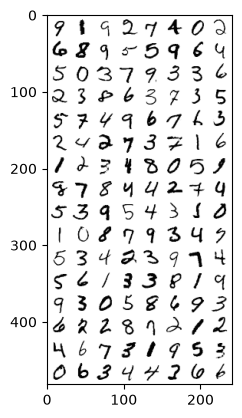

In [49]:
dataiter = iter(train_loader)
images, labels = next(dataiter)

import matplotlib.pyplot as plt 
import numpy as np 
from torchvision.utils import make_grid

# Helper function for inline image display 
def matplotlib_imshow(img, one_channel = False):
    if one_channel: # what is this condition?
        img = img.mean(dim=0)
    img = img / 2 + 0.5 # unnormalize; why this is unnormalize?
    npimg = img.numpy()
    if one_channel:
        plt.imshow(npimg, cmap="Greys") # what is this cmap? - it mean
    else: 
        plt.imshow(np.transpose(npimg, (1, 2, 0))) 

# Creat a grid from the images and show them 
img_grid = make_grid(images)
matplotlib_imshow(img_grid, one_channel=True)

In [50]:
import wandb
import numpy as np
import matplotlib.pyplot as plt
from torchvision.utils import make_grid


def make_display_grid(samples, nrow=8, scale=4, pad=2):
    """(n,1,28,28) 0/1 -> uint8 (H,W,3) grid, upscaled so it's legible at thumbnail size."""
    # pad_value=1 makes a white gutter on the black background
    grid = make_grid(samples, nrow=nrow, padding=pad, pad_value=1.0)  # (3,H,W) float 0/1
    grid = grid.permute(1, 2, 0).numpy()
    # Nearest-neighbour upscale so digits stay crisp instead of being blurred by the UI
    grid = np.repeat(np.repeat(grid, scale, axis=0), scale, axis=1)
    return (grid * 255).clip(0, 255).astype(np.uint8)


def sample_and_log(model, n=64, epoch=None, key="samples/grid"):
    """Draw n samples, show them inline, and (if a run is active) log a grid to wandb."""
    was_training = model.training
    model.eval()

    samples = model.sample(n).cpu().view(-1, 1, 28, 28)  # (n, 1, 28, 28), 0/1
    img = make_display_grid(samples, nrow=8, scale=4)

    # 1) Show inline
    plt.figure(figsize=(8, 8))
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"NADE samples — epoch {epoch}")
    plt.show()

    # 2) Send to wandb (uint8 = no ambiguity about the value range)
    if wandb.run is not None:
        payload = {key: wandb.Image(img, caption=f"epoch {epoch}")}
        if isinstance(epoch, int):
            payload["epoch"] = epoch
        wandb.log(payload, commit=False)

    model.train(was_training)
    return samples


run = wandb.init(
    project="nade-mnist",
    config={
        "D": 784, "H": 500, "lr": 5e-3, "batch_size": 128, "epochs": 500,
        "eval_every": 100, "patience": 10, "top_k_checkpoints": 10,
        "val_size": VAL_SIZE,
    },
)

model = NADE(D=run.config.D, H=run.config.H).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=run.config.lr)

wandb.watch(model, log="gradients", log_freq=100)


In [51]:
from pathlib import Path
import torch.nn.functional as F


@torch.no_grad()
def evaluate(model, loader):
    """Average NLL per image on a dataset (val uses the same dynamic binarization)."""
    was_training = model.training
    model.eval()

    total, seen = 0.0, 0
    for images, _ in loader:
        images = images.to(device).flatten(start_dim=1)
        images = torch.bernoulli(images)
        total += model.loss(images).item() * images.size(0)
        seen += images.size(0)

    model.train(was_training)
    return total / seen


class EarlyStopping:
    """Stop when `metric` hasn't improved for `patience` consecutive evaluations."""

    def __init__(self, patience=10, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best = float("inf")
        self.best_state = None
        self.bad_evals = 0          # consecutive evals without improvement

    def step(self, value, model):
        """Returns True when patience is exhausted."""
        if value < self.best - self.min_delta:
            self.best = value
            self.best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            self.bad_evals = 0
            return False

        self.bad_evals += 1
        return self.bad_evals >= self.patience

    def restore(self, model):
        """Load the best weights seen so far."""
        if self.best_state is not None:
            model.load_state_dict(self.best_state)


class TopKCheckpoints:
    """Keep the k checkpoints with the lowest validation loss on disk."""

    def __init__(self, k=10, out_dir="checkpoints"):
        self.k = k
        self.out_dir = Path(out_dir)
        self.out_dir.mkdir(parents=True, exist_ok=True)
        self.entries = []       # [(val_loss, path)], sorted ascending
        self.counter = 0

    def maybe_save(self, val_loss, model, epoch=None, batch=None):
        """Save if this run makes the top k. Returns the path, or None if not kept."""
        # Cheap reject: worse than the current worst kept checkpoint
        if len(self.entries) >= self.k and val_loss >= self.entries[-1][0]:
            return None

        self.counter += 1
        path = self.out_dir / f"ckpt_{self.counter:04d}_nll{val_loss:.4f}.pt"
        torch.save({
            "state_dict": model.state_dict(),
            "val_loss": val_loss,
            "epoch": epoch,
            "batch": batch,
        }, path)

        self.entries.append((val_loss, path))
        self.entries.sort(key=lambda e: e[0])

        # Evict the worst checkpoint(s) beyond k
        while len(self.entries) > self.k:
            _, old_path = self.entries.pop()
            old_path.unlink(missing_ok=True)

        return path

    def paths(self):
        return [p for _, p in self.entries]

    def best_path(self):
        return self.entries[0][1] if self.entries else None


In [52]:
EVAL_EVERY = run.config.eval_every       # evaluate val loss every N batches
PATIENCE = run.config.patience           # consecutive evals without improvement before stopping

def train_one_epoch(epoch_number, stopper, keep):
    running_loss = 0. 
    seen = 0 
    stopped = False

    for i, (images, _) in enumerate(train_loader):
        # (B, 1, 28, 28) -> (B, 784) 
        images = images.to(device).flatten(start_dim=1)

        # Dynamic binarization 
        images = torch.bernoulli(images)

        optimizer.zero_grad()

        loss = model.loss(images) 

        loss.backward() 
        optimizer.step() 

        wandb.log({"train/loss_step": loss.item(), "epoch": epoch_number})

        running_loss += loss.item() * images.size(0)
        seen += images.size(0)

        # --- Validation + early stopping + checkpointing ---
        if (i + 1) % EVAL_EVERY == 0:
            val_loss = evaluate(model, val_loader)

            # Keep this state if it's one of the k best seen so far
            saved = keep.maybe_save(val_loss, model, epoch=epoch_number, batch=i + 1)

            stopped = stopper.step(val_loss, model)

            wandb.log({
                "val/nll_per_image": val_loss,
                "val/best": stopper.best,
                "val/bad_evals": stopper.bad_evals,
                "val/is_top_k": 1 if saved else 0,
                "epoch": epoch_number,
            })

            print(f"  batch {i+1}: val NLL = {val_loss:.4f} "
                  f"(best {stopper.best:.4f}, {stopper.bad_evals}/{PATIENCE})"
                  + (f" [saved {saved.name}]" if saved else ""))

            if stopped:
                print(f"Early stopping at epoch {epoch_number}, batch {i+1}")
                break

    return running_loss / seen, stopped


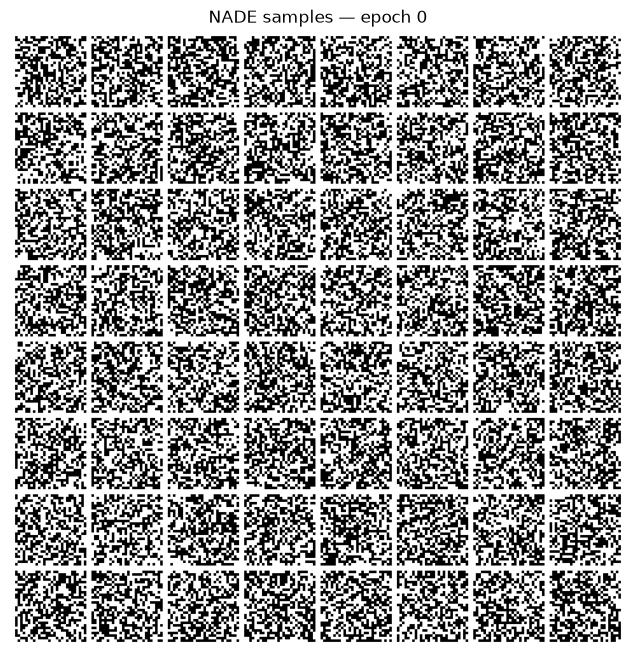

  batch 100: val NLL = 209.5730 (best 209.5730, 0/10) [saved ckpt_0001_nll209.5730.pt]
  batch 200: val NLL = 207.2180 (best 207.2180, 0/10) [saved ckpt_0002_nll207.2180.pt]
  batch 300: val NLL = 205.9838 (best 205.9838, 0/10) [saved ckpt_0003_nll205.9838.pt]
  batch 400: val NLL = 205.1826 (best 205.1826, 0/10) [saved ckpt_0004_nll205.1826.pt]
Epoch 1: train NLL = 213.2041


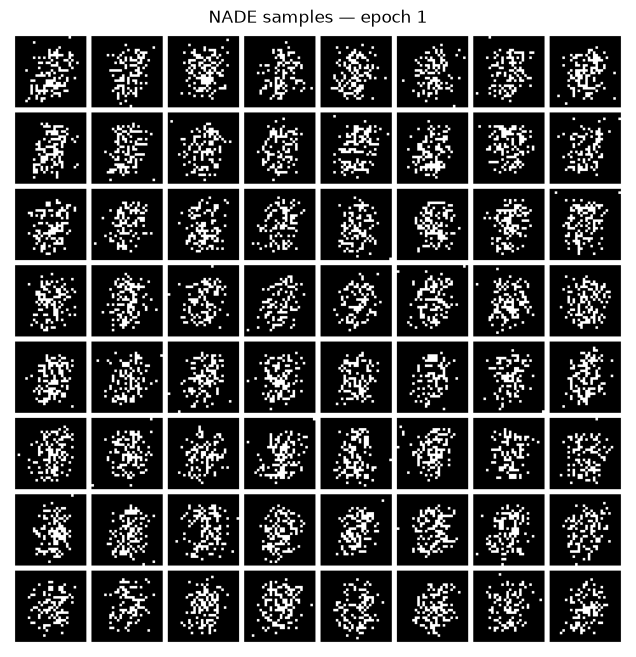

  batch 100: val NLL = 203.7481 (best 203.7481, 0/10) [saved ckpt_0005_nll203.7481.pt]
  batch 200: val NLL = 202.2693 (best 202.2693, 0/10) [saved ckpt_0006_nll202.2693.pt]
  batch 300: val NLL = 200.5871 (best 200.5871, 0/10) [saved ckpt_0007_nll200.5871.pt]
  batch 400: val NLL = 198.4042 (best 198.4042, 0/10) [saved ckpt_0008_nll198.4042.pt]
Epoch 2: train NLL = 202.0803


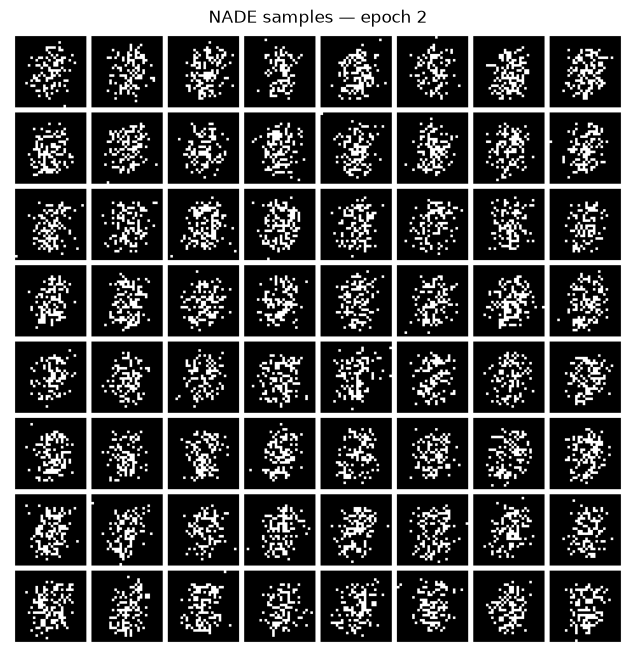

  batch 100: val NLL = 195.4079 (best 195.4079, 0/10) [saved ckpt_0009_nll195.4079.pt]
  batch 200: val NLL = 192.9564 (best 192.9564, 0/10) [saved ckpt_0010_nll192.9564.pt]
  batch 300: val NLL = 190.4542 (best 190.4542, 0/10) [saved ckpt_0011_nll190.4542.pt]
  batch 400: val NLL = 187.9827 (best 187.9827, 0/10) [saved ckpt_0012_nll187.9827.pt]
Epoch 3: train NLL = 192.7074


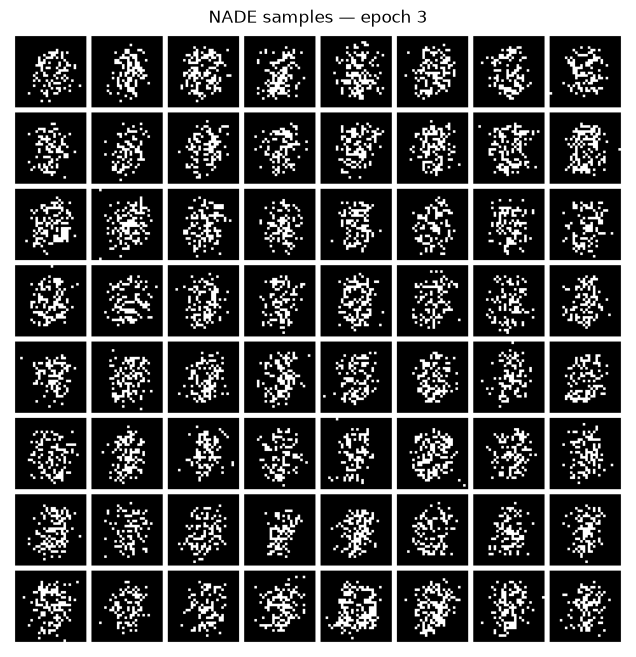

  batch 100: val NLL = 184.7881 (best 184.7881, 0/10) [saved ckpt_0013_nll184.7881.pt]
  batch 200: val NLL = 182.4311 (best 182.4311, 0/10) [saved ckpt_0014_nll182.4311.pt]
  batch 300: val NLL = 180.2613 (best 180.2613, 0/10) [saved ckpt_0015_nll180.2613.pt]
  batch 400: val NLL = 178.1134 (best 178.1134, 0/10) [saved ckpt_0016_nll178.1134.pt]
Epoch 4: train NLL = 182.3291


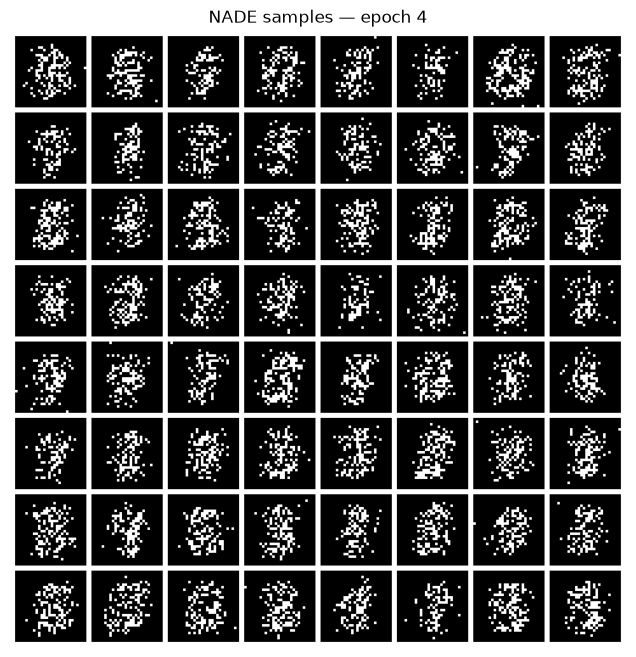

  batch 100: val NLL = 175.4762 (best 175.4762, 0/10) [saved ckpt_0017_nll175.4762.pt]
  batch 200: val NLL = 173.6706 (best 173.6706, 0/10) [saved ckpt_0018_nll173.6706.pt]
  batch 300: val NLL = 171.9263 (best 171.9263, 0/10) [saved ckpt_0019_nll171.9263.pt]
  batch 400: val NLL = 170.1706 (best 170.1706, 0/10) [saved ckpt_0020_nll170.1706.pt]
Epoch 5: train NLL = 173.5615


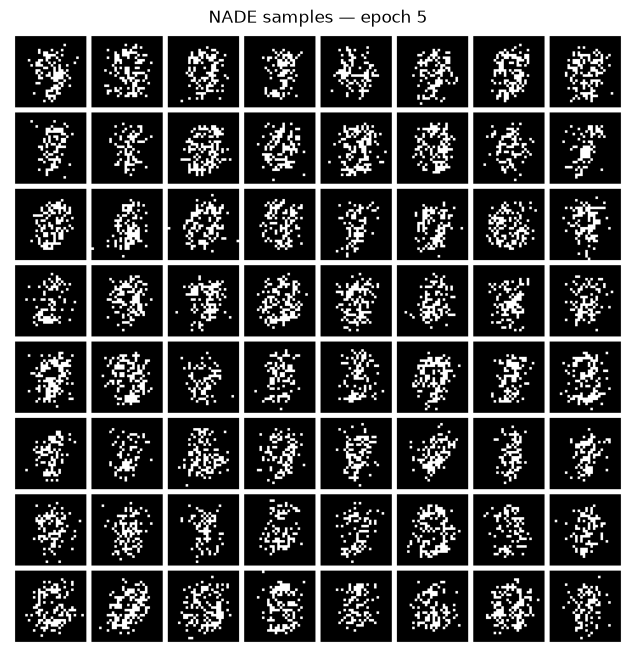

  batch 100: val NLL = 168.2388 (best 168.2388, 0/10) [saved ckpt_0021_nll168.2388.pt]
  batch 200: val NLL = 167.0562 (best 167.0562, 0/10) [saved ckpt_0022_nll167.0562.pt]
  batch 300: val NLL = 165.5355 (best 165.5355, 0/10) [saved ckpt_0023_nll165.5355.pt]
  batch 400: val NLL = 164.3399 (best 164.3399, 0/10) [saved ckpt_0024_nll164.3399.pt]
Epoch 6: train NLL = 166.8736


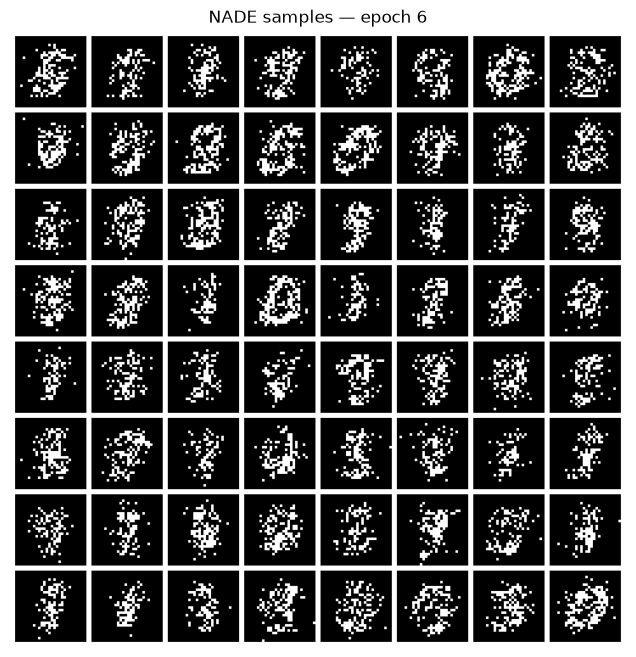

  batch 100: val NLL = 162.8664 (best 162.8664, 0/10) [saved ckpt_0025_nll162.8664.pt]
  batch 200: val NLL = 161.7510 (best 161.7510, 0/10) [saved ckpt_0026_nll161.7510.pt]
  batch 300: val NLL = 160.6005 (best 160.6005, 0/10) [saved ckpt_0027_nll160.6005.pt]
  batch 400: val NLL = 159.5783 (best 159.5783, 0/10) [saved ckpt_0028_nll159.5783.pt]
Epoch 7: train NLL = 161.6372


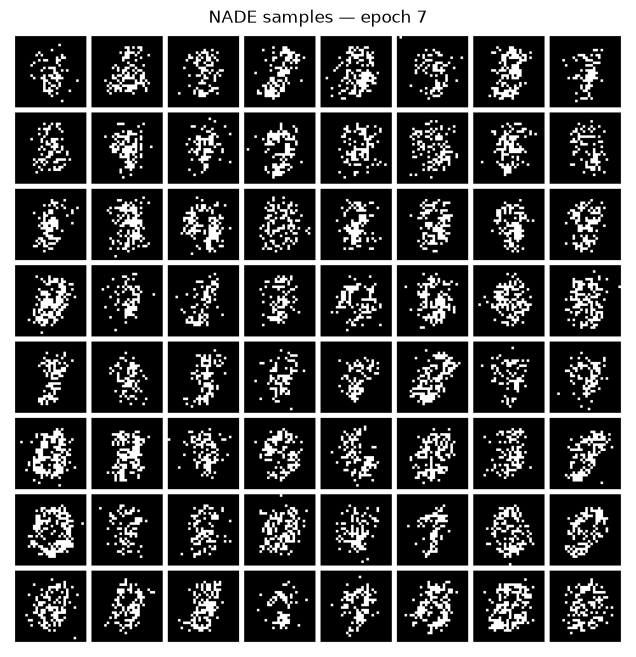

  batch 100: val NLL = 158.2462 (best 158.2462, 0/10) [saved ckpt_0029_nll158.2462.pt]
  batch 200: val NLL = 157.3898 (best 157.3898, 0/10) [saved ckpt_0030_nll157.3898.pt]
  batch 300: val NLL = 156.4215 (best 156.4215, 0/10) [saved ckpt_0031_nll156.4215.pt]
  batch 400: val NLL = 155.5319 (best 155.5319, 0/10) [saved ckpt_0032_nll155.5319.pt]
Epoch 8: train NLL = 157.2818


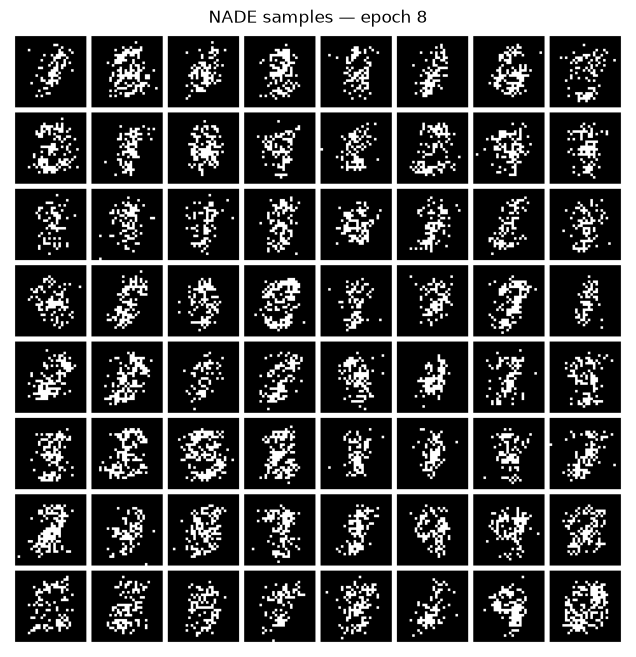

  batch 100: val NLL = 154.4134 (best 154.4134, 0/10) [saved ckpt_0033_nll154.4134.pt]
  batch 200: val NLL = 153.6302 (best 153.6302, 0/10) [saved ckpt_0034_nll153.6302.pt]
  batch 300: val NLL = 152.7641 (best 152.7641, 0/10) [saved ckpt_0035_nll152.7641.pt]
  batch 400: val NLL = 152.0326 (best 152.0326, 0/10) [saved ckpt_0036_nll152.0326.pt]
Epoch 9: train NLL = 153.5204


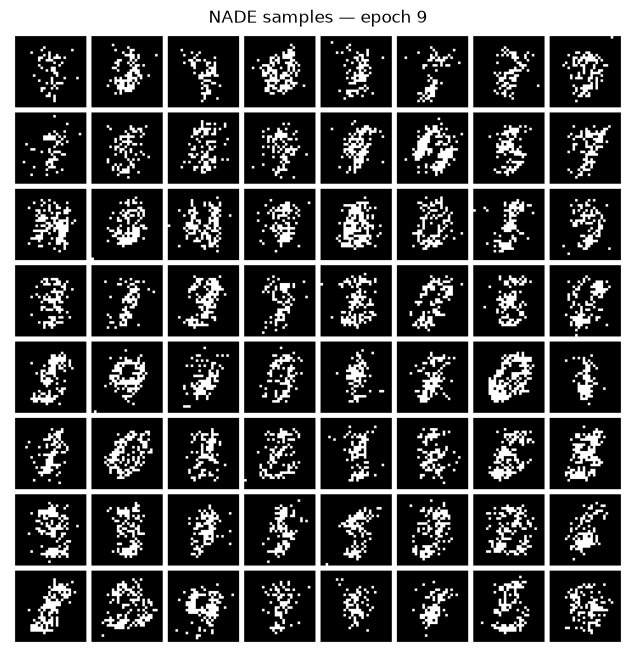

  batch 100: val NLL = 150.9969 (best 150.9969, 0/10) [saved ckpt_0037_nll150.9969.pt]
  batch 200: val NLL = 150.3108 (best 150.3108, 0/10) [saved ckpt_0038_nll150.3108.pt]
  batch 300: val NLL = 149.5185 (best 149.5185, 0/10) [saved ckpt_0039_nll149.5185.pt]
  batch 400: val NLL = 148.9086 (best 148.9086, 0/10) [saved ckpt_0040_nll148.9086.pt]
Epoch 10: train NLL = 150.1626


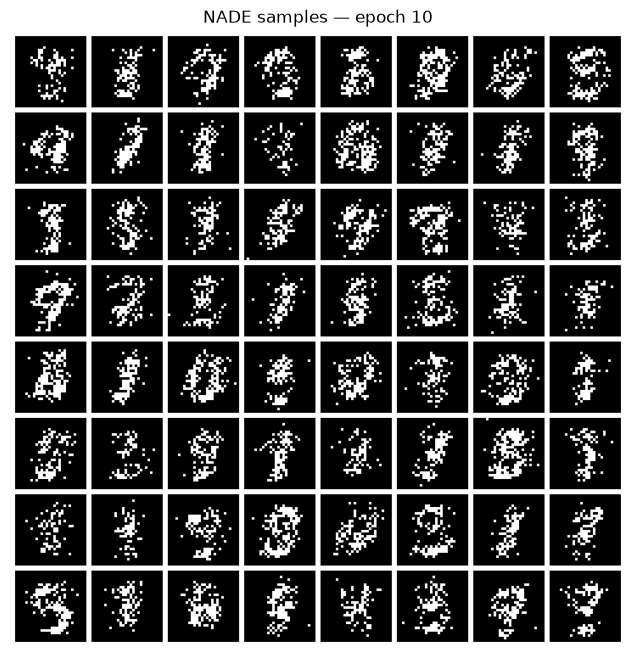

  batch 100: val NLL = 147.9288 (best 147.9288, 0/10) [saved ckpt_0041_nll147.9288.pt]
  batch 200: val NLL = 147.2714 (best 147.2714, 0/10) [saved ckpt_0042_nll147.2714.pt]
  batch 300: val NLL = 146.6596 (best 146.6596, 0/10) [saved ckpt_0043_nll146.6596.pt]
  batch 400: val NLL = 145.8465 (best 145.8465, 0/10) [saved ckpt_0044_nll145.8465.pt]
Epoch 11: train NLL = 147.1702


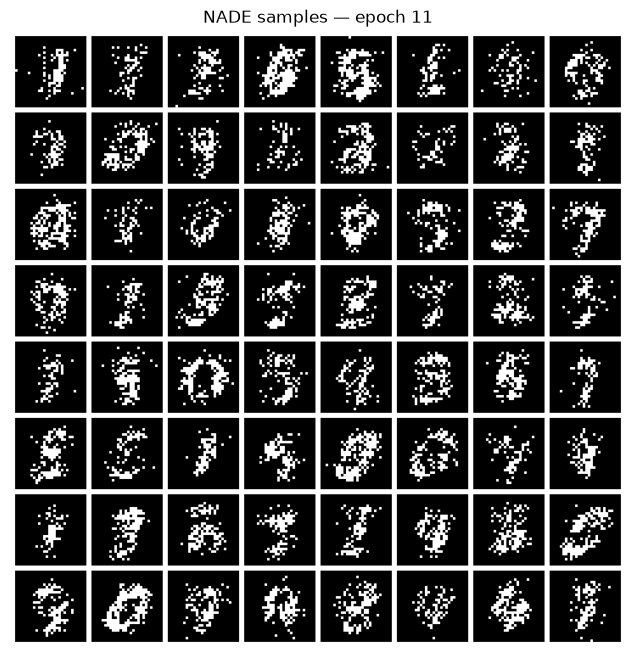

  batch 100: val NLL = 145.0694 (best 145.0694, 0/10) [saved ckpt_0045_nll145.0694.pt]
  batch 200: val NLL = 144.5572 (best 144.5572, 0/10) [saved ckpt_0046_nll144.5572.pt]
  batch 300: val NLL = 143.9232 (best 143.9232, 0/10) [saved ckpt_0047_nll143.9232.pt]
  batch 400: val NLL = 143.3245 (best 143.3245, 0/10) [saved ckpt_0048_nll143.3245.pt]
Epoch 12: train NLL = 144.4738


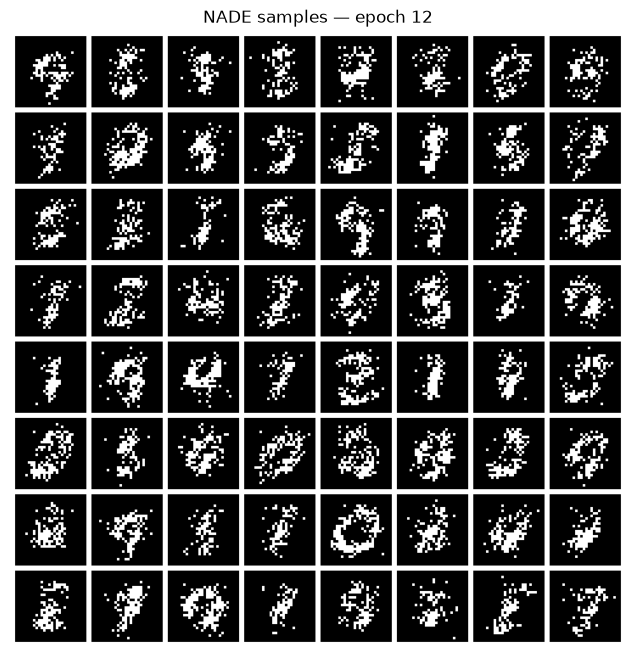

  batch 100: val NLL = 142.6997 (best 142.6997, 0/10) [saved ckpt_0049_nll142.6997.pt]
  batch 200: val NLL = 142.1524 (best 142.1524, 0/10) [saved ckpt_0050_nll142.1524.pt]
  batch 300: val NLL = 141.6601 (best 141.6601, 0/10) [saved ckpt_0051_nll141.6601.pt]
  batch 400: val NLL = 141.2221 (best 141.2221, 0/10) [saved ckpt_0052_nll141.2221.pt]
Epoch 13: train NLL = 142.0089


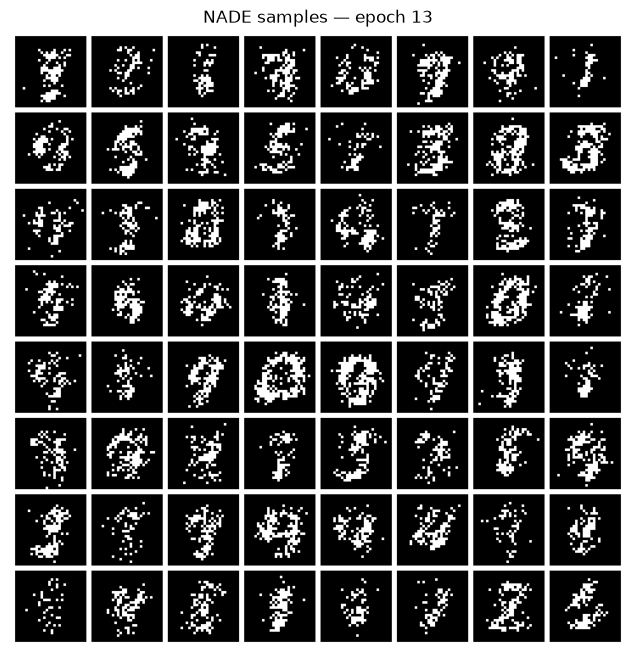

  batch 100: val NLL = 140.4125 (best 140.4125, 0/10) [saved ckpt_0053_nll140.4125.pt]
  batch 200: val NLL = 140.0543 (best 140.0543, 0/10) [saved ckpt_0054_nll140.0543.pt]
  batch 300: val NLL = 139.5270 (best 139.5270, 0/10) [saved ckpt_0055_nll139.5270.pt]
  batch 400: val NLL = 139.0679 (best 139.0679, 0/10) [saved ckpt_0056_nll139.0679.pt]
Epoch 14: train NLL = 139.7854


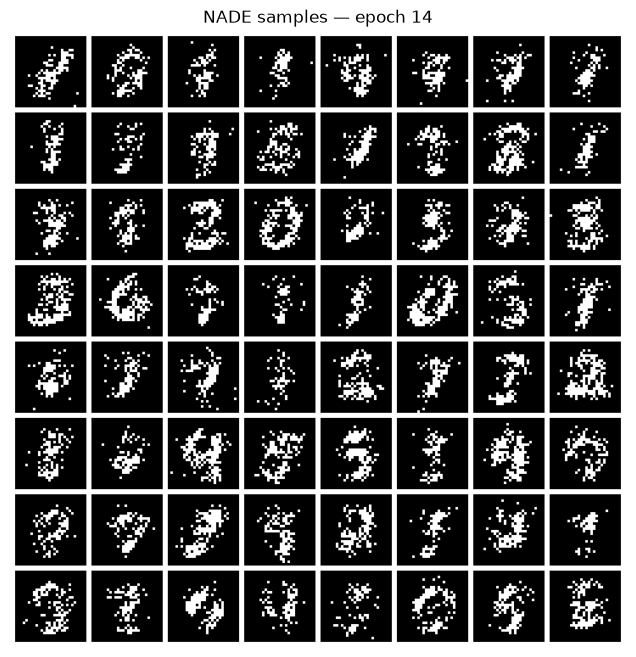

  batch 100: val NLL = 138.3837 (best 138.3837, 0/10) [saved ckpt_0057_nll138.3837.pt]
  batch 200: val NLL = 138.0535 (best 138.0535, 0/10) [saved ckpt_0058_nll138.0535.pt]
  batch 300: val NLL = 137.6400 (best 137.6400, 0/10) [saved ckpt_0059_nll137.6400.pt]
  batch 400: val NLL = 137.0695 (best 137.0695, 0/10) [saved ckpt_0060_nll137.0695.pt]
Epoch 15: train NLL = 137.7259


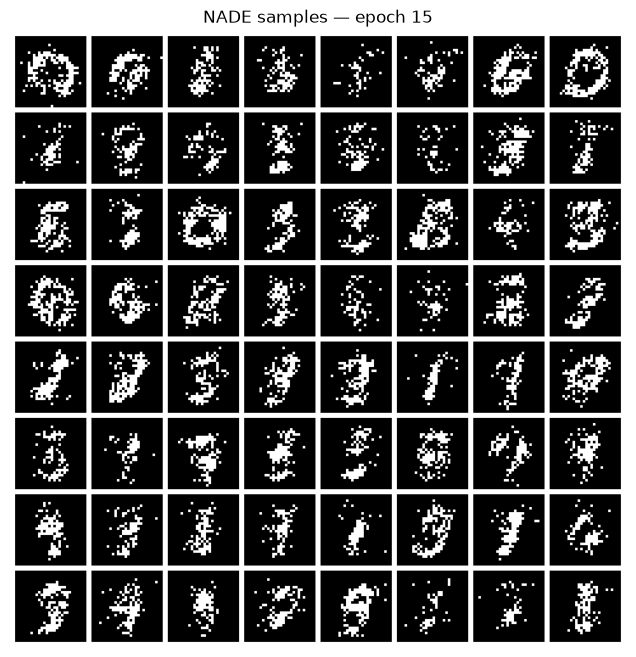

  batch 100: val NLL = 136.4551 (best 136.4551, 0/10) [saved ckpt_0061_nll136.4551.pt]
  batch 200: val NLL = 136.1556 (best 136.1556, 0/10) [saved ckpt_0062_nll136.1556.pt]
  batch 300: val NLL = 135.6557 (best 135.6557, 0/10) [saved ckpt_0063_nll135.6557.pt]
  batch 400: val NLL = 135.2523 (best 135.2523, 0/10) [saved ckpt_0064_nll135.2523.pt]
Epoch 16: train NLL = 135.8620


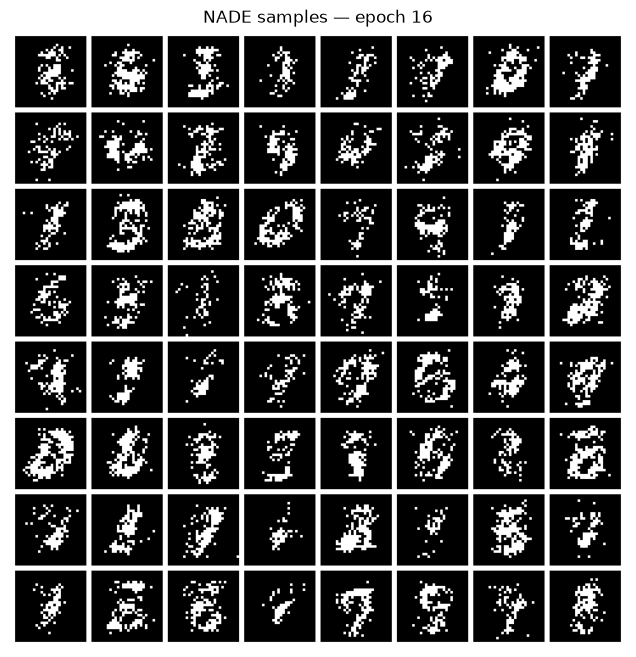

  batch 100: val NLL = 134.6782 (best 134.6782, 0/10) [saved ckpt_0065_nll134.6782.pt]
  batch 200: val NLL = 134.3617 (best 134.3617, 0/10) [saved ckpt_0066_nll134.3617.pt]
  batch 300: val NLL = 134.0081 (best 134.0081, 0/10) [saved ckpt_0067_nll134.0081.pt]
  batch 400: val NLL = 133.5243 (best 133.5243, 0/10) [saved ckpt_0068_nll133.5243.pt]
Epoch 17: train NLL = 134.1438


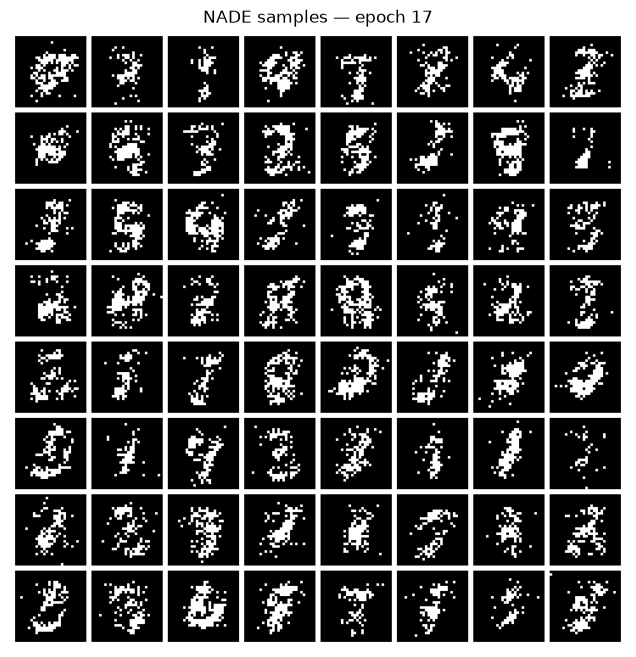

  batch 100: val NLL = 133.2393 (best 133.2393, 0/10) [saved ckpt_0069_nll133.2393.pt]
  batch 200: val NLL = 132.6745 (best 132.6745, 0/10) [saved ckpt_0070_nll132.6745.pt]
  batch 300: val NLL = 132.4683 (best 132.4683, 0/10) [saved ckpt_0071_nll132.4683.pt]
  batch 400: val NLL = 132.1440 (best 132.1440, 0/10) [saved ckpt_0072_nll132.1440.pt]
Epoch 18: train NLL = 132.5936


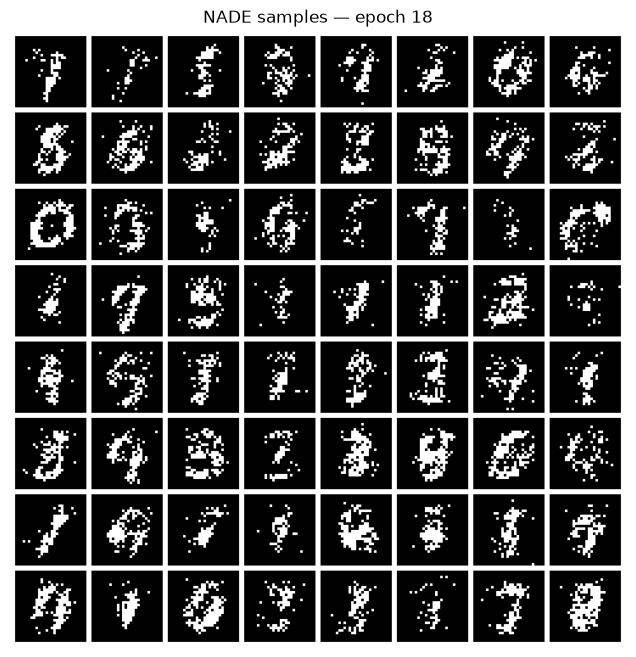

  batch 100: val NLL = 131.6085 (best 131.6085, 0/10) [saved ckpt_0073_nll131.6085.pt]
  batch 200: val NLL = 131.3247 (best 131.3247, 0/10) [saved ckpt_0074_nll131.3247.pt]
  batch 300: val NLL = 131.0269 (best 131.0269, 0/10) [saved ckpt_0075_nll131.0269.pt]
  batch 400: val NLL = 130.6825 (best 130.6825, 0/10) [saved ckpt_0076_nll130.6825.pt]
Epoch 19: train NLL = 131.0824


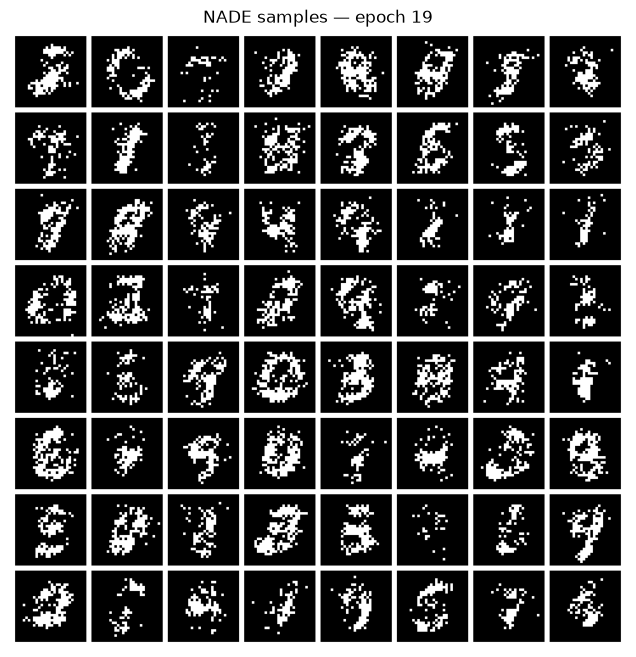

  batch 100: val NLL = 130.1965 (best 130.1965, 0/10) [saved ckpt_0077_nll130.1965.pt]
  batch 200: val NLL = 129.9468 (best 129.9468, 0/10) [saved ckpt_0078_nll129.9468.pt]
  batch 300: val NLL = 129.5926 (best 129.5926, 0/10) [saved ckpt_0079_nll129.5926.pt]
  batch 400: val NLL = 129.2780 (best 129.2780, 0/10) [saved ckpt_0080_nll129.2780.pt]
Epoch 20: train NLL = 129.7301


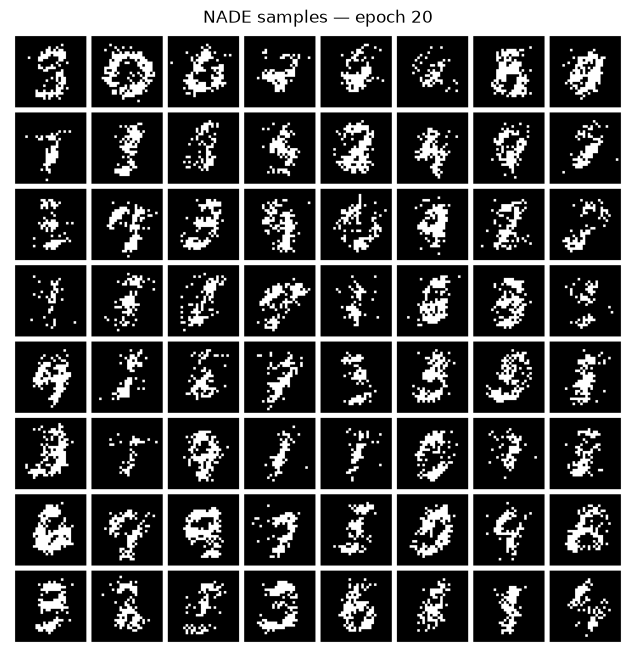

  batch 100: val NLL = 128.9251 (best 128.9251, 0/10) [saved ckpt_0081_nll128.9251.pt]
  batch 200: val NLL = 128.8664 (best 128.8664, 0/10) [saved ckpt_0082_nll128.8664.pt]
  batch 300: val NLL = 128.4445 (best 128.4445, 0/10) [saved ckpt_0083_nll128.4445.pt]
  batch 400: val NLL = 127.9489 (best 127.9489, 0/10) [saved ckpt_0084_nll127.9489.pt]
Epoch 21: train NLL = 128.4549


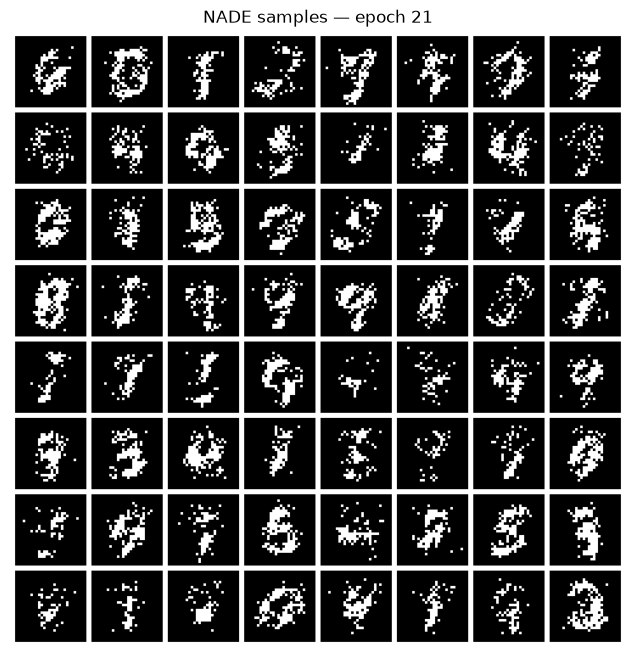

  batch 100: val NLL = 127.7696 (best 127.7696, 0/10) [saved ckpt_0085_nll127.7696.pt]
  batch 200: val NLL = 127.4268 (best 127.4268, 0/10) [saved ckpt_0086_nll127.4268.pt]
  batch 300: val NLL = 127.2229 (best 127.2229, 0/10) [saved ckpt_0087_nll127.2229.pt]
  batch 400: val NLL = 126.7895 (best 126.7895, 0/10) [saved ckpt_0088_nll126.7895.pt]
Epoch 22: train NLL = 127.2432


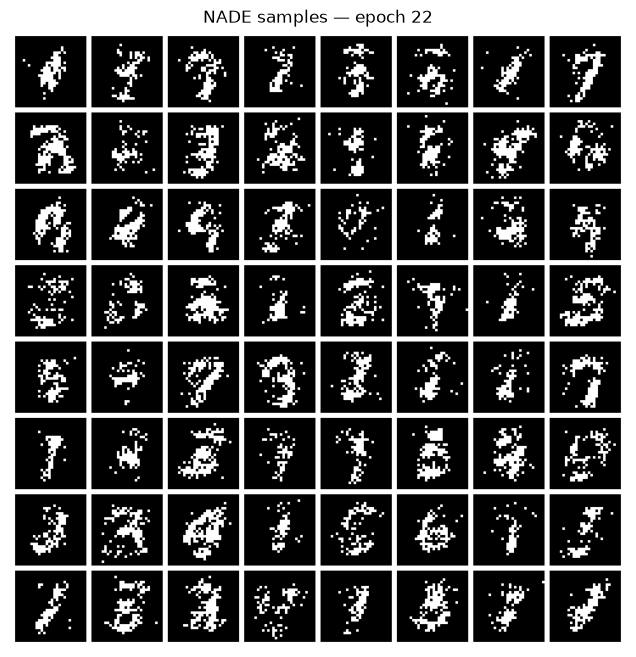

  batch 100: val NLL = 126.5599 (best 126.5599, 0/10) [saved ckpt_0089_nll126.5599.pt]
  batch 200: val NLL = 126.3276 (best 126.3276, 0/10) [saved ckpt_0090_nll126.3276.pt]
  batch 300: val NLL = 126.2096 (best 126.2096, 0/10) [saved ckpt_0091_nll126.2096.pt]
  batch 400: val NLL = 125.8497 (best 125.8497, 0/10) [saved ckpt_0092_nll125.8497.pt]
Epoch 23: train NLL = 126.0717


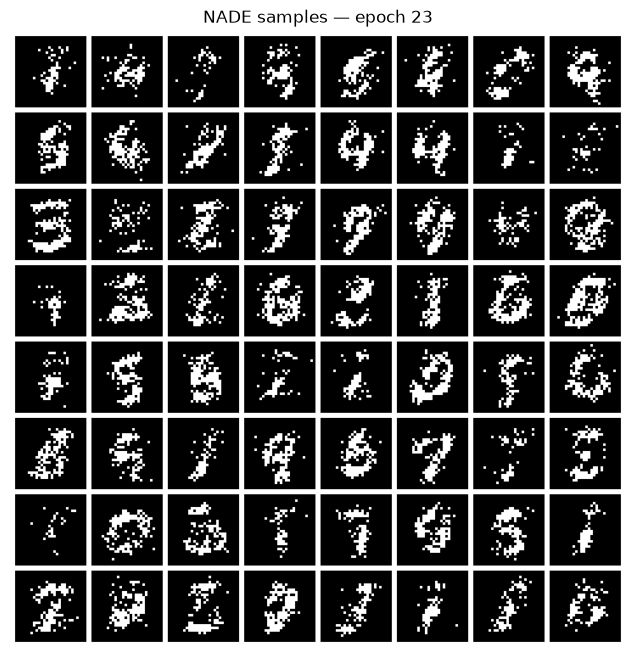

  batch 100: val NLL = 125.4518 (best 125.4518, 0/10) [saved ckpt_0093_nll125.4518.pt]
  batch 200: val NLL = 125.2808 (best 125.2808, 0/10) [saved ckpt_0094_nll125.2808.pt]
  batch 300: val NLL = 125.0844 (best 125.0844, 0/10) [saved ckpt_0095_nll125.0844.pt]
  batch 400: val NLL = 124.9844 (best 124.9844, 0/10) [saved ckpt_0096_nll124.9844.pt]
Epoch 24: train NLL = 125.0900


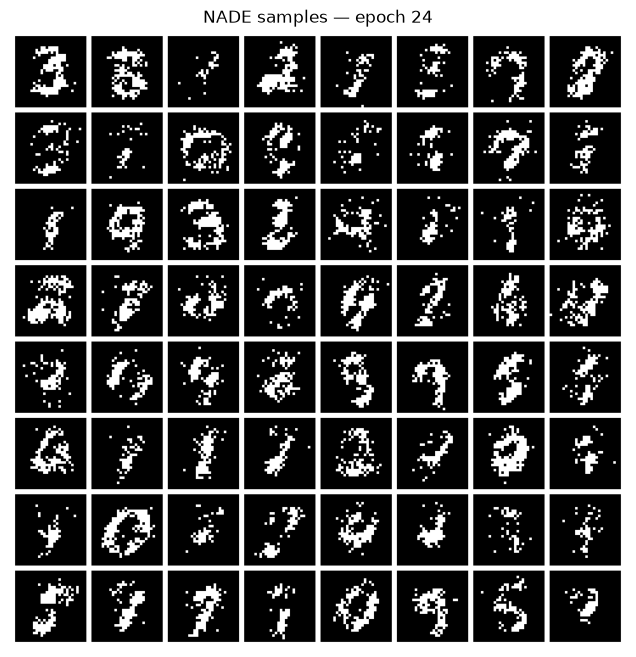

  batch 100: val NLL = 124.5705 (best 124.5705, 0/10) [saved ckpt_0097_nll124.5705.pt]
  batch 200: val NLL = 124.2108 (best 124.2108, 0/10) [saved ckpt_0098_nll124.2108.pt]
  batch 300: val NLL = 124.1396 (best 124.1396, 0/10) [saved ckpt_0099_nll124.1396.pt]
  batch 400: val NLL = 123.8926 (best 123.8926, 0/10) [saved ckpt_0100_nll123.8926.pt]
Epoch 25: train NLL = 124.1112


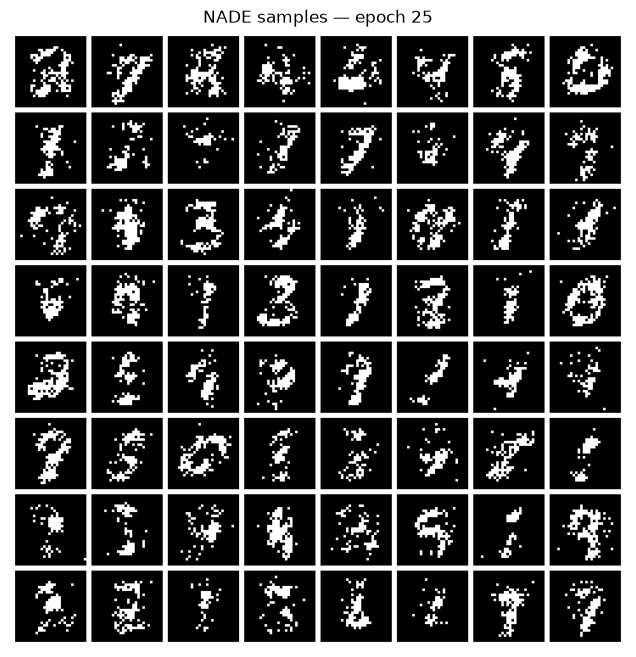

  batch 100: val NLL = 123.5068 (best 123.5068, 0/10) [saved ckpt_0101_nll123.5068.pt]
  batch 200: val NLL = 123.2803 (best 123.2803, 0/10) [saved ckpt_0102_nll123.2803.pt]
  batch 300: val NLL = 123.3022 (best 123.2803, 1/10) [saved ckpt_0103_nll123.3022.pt]
  batch 400: val NLL = 123.0575 (best 123.0575, 0/10) [saved ckpt_0104_nll123.0575.pt]
Epoch 26: train NLL = 123.1384


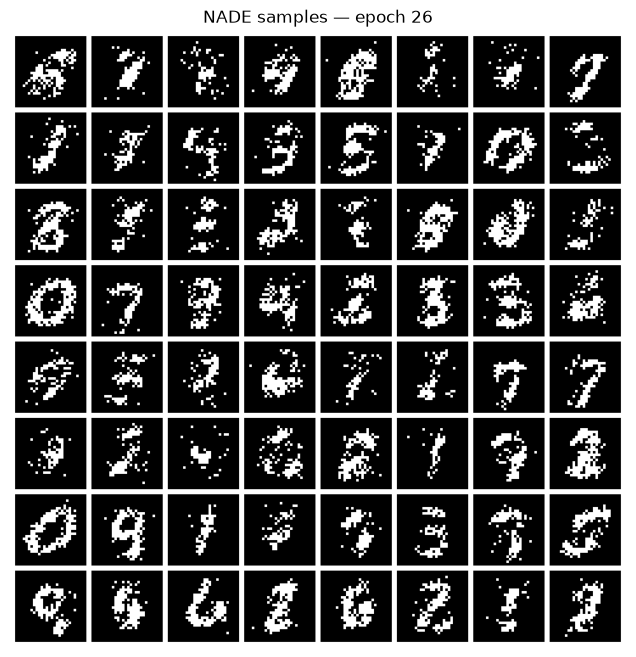

  batch 100: val NLL = 122.5409 (best 122.5409, 0/10) [saved ckpt_0105_nll122.5409.pt]
  batch 200: val NLL = 122.3994 (best 122.3994, 0/10) [saved ckpt_0106_nll122.3994.pt]
  batch 300: val NLL = 122.3768 (best 122.3768, 0/10) [saved ckpt_0107_nll122.3768.pt]
  batch 400: val NLL = 122.1014 (best 122.1014, 0/10) [saved ckpt_0108_nll122.1014.pt]
Epoch 27: train NLL = 122.2252


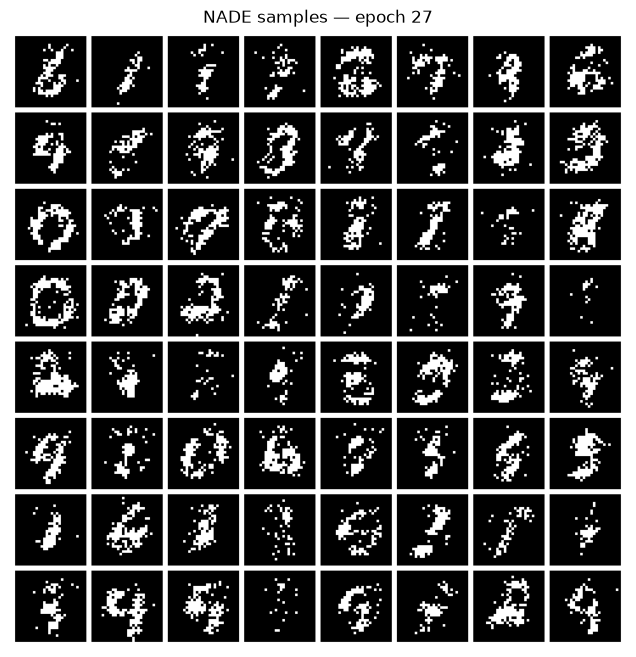

  batch 100: val NLL = 121.8389 (best 121.8389, 0/10) [saved ckpt_0109_nll121.8389.pt]
  batch 200: val NLL = 121.6234 (best 121.6234, 0/10) [saved ckpt_0110_nll121.6234.pt]
  batch 300: val NLL = 121.4466 (best 121.4466, 0/10) [saved ckpt_0111_nll121.4466.pt]
  batch 400: val NLL = 121.3991 (best 121.3991, 0/10) [saved ckpt_0112_nll121.3991.pt]
Epoch 28: train NLL = 121.3767


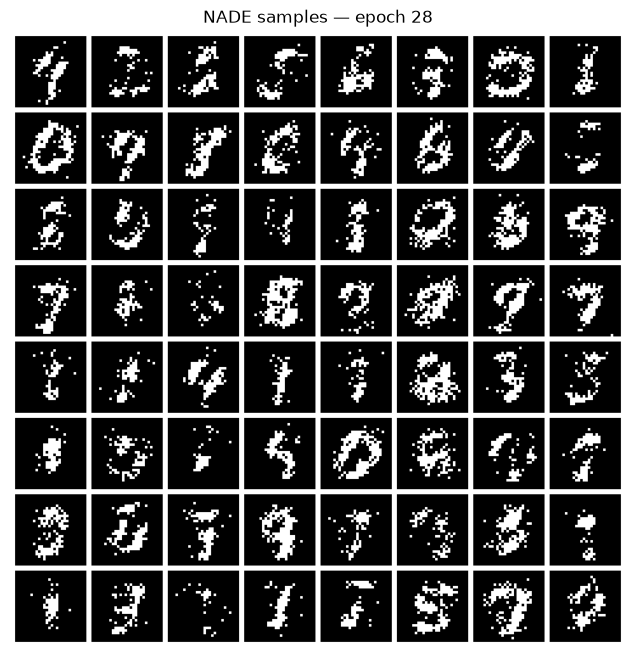

  batch 100: val NLL = 121.0699 (best 121.0699, 0/10) [saved ckpt_0113_nll121.0699.pt]
  batch 200: val NLL = 120.8409 (best 120.8409, 0/10) [saved ckpt_0114_nll120.8409.pt]
  batch 300: val NLL = 120.7157 (best 120.7157, 0/10) [saved ckpt_0115_nll120.7157.pt]
  batch 400: val NLL = 120.5175 (best 120.5175, 0/10) [saved ckpt_0116_nll120.5175.pt]
Epoch 29: train NLL = 120.5804


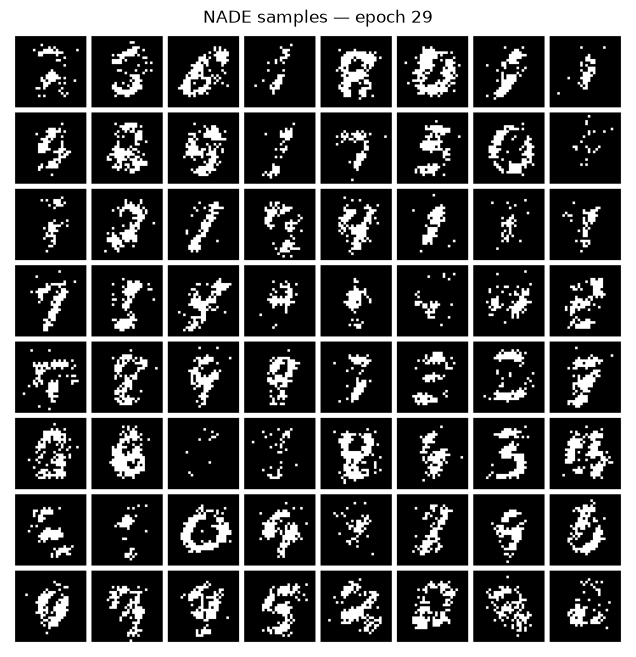

  batch 100: val NLL = 120.2938 (best 120.2938, 0/10) [saved ckpt_0117_nll120.2938.pt]
  batch 200: val NLL = 120.0957 (best 120.0957, 0/10) [saved ckpt_0118_nll120.0957.pt]
  batch 300: val NLL = 119.8863 (best 119.8863, 0/10) [saved ckpt_0119_nll119.8863.pt]
  batch 400: val NLL = 119.7850 (best 119.7850, 0/10) [saved ckpt_0120_nll119.7850.pt]
Epoch 30: train NLL = 119.8673


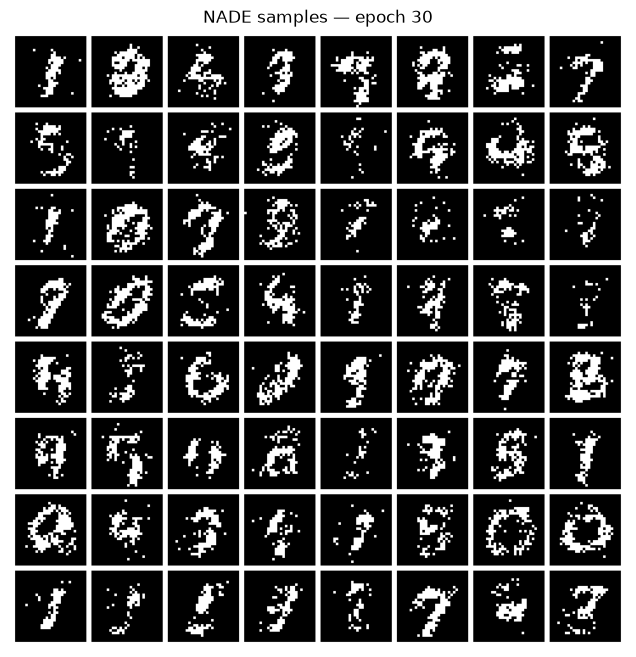

  batch 100: val NLL = 119.5311 (best 119.5311, 0/10) [saved ckpt_0121_nll119.5311.pt]
  batch 200: val NLL = 119.3381 (best 119.3381, 0/10) [saved ckpt_0122_nll119.3381.pt]
  batch 300: val NLL = 119.3210 (best 119.3210, 0/10) [saved ckpt_0123_nll119.3210.pt]
  batch 400: val NLL = 119.1009 (best 119.1009, 0/10) [saved ckpt_0124_nll119.1009.pt]
Epoch 31: train NLL = 119.1584


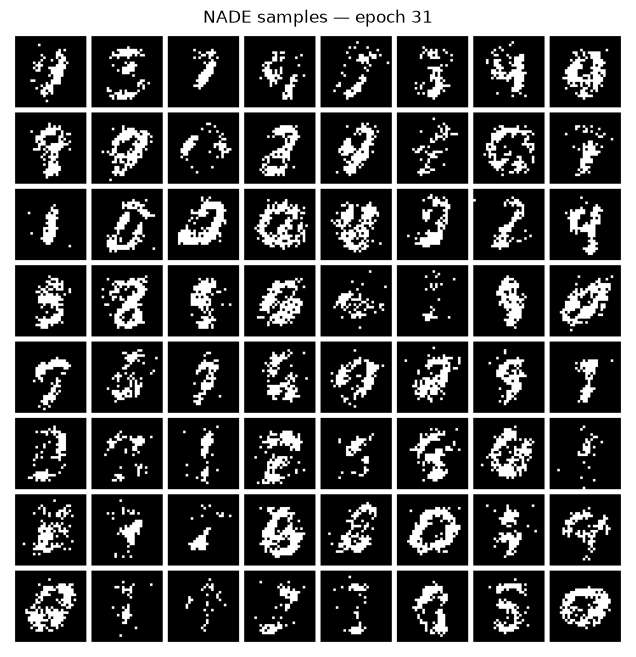

  batch 100: val NLL = 118.9725 (best 118.9725, 0/10) [saved ckpt_0125_nll118.9725.pt]
  batch 200: val NLL = 118.7750 (best 118.7750, 0/10) [saved ckpt_0126_nll118.7750.pt]
  batch 300: val NLL = 118.5475 (best 118.5475, 0/10) [saved ckpt_0127_nll118.5475.pt]
  batch 400: val NLL = 118.5172 (best 118.5172, 0/10) [saved ckpt_0128_nll118.5172.pt]
Epoch 32: train NLL = 118.4455


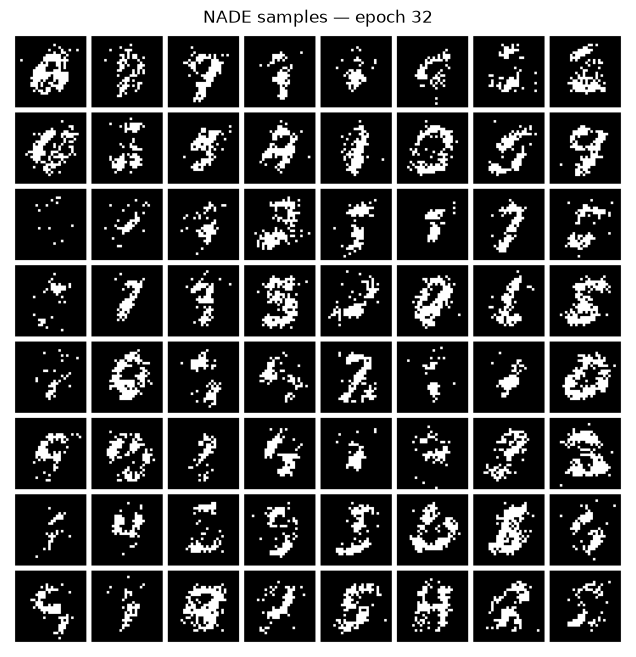

  batch 100: val NLL = 118.3368 (best 118.3368, 0/10) [saved ckpt_0129_nll118.3368.pt]
  batch 200: val NLL = 117.9961 (best 117.9961, 0/10) [saved ckpt_0130_nll117.9961.pt]
  batch 300: val NLL = 117.8968 (best 117.8968, 0/10) [saved ckpt_0131_nll117.8968.pt]
  batch 400: val NLL = 117.8341 (best 117.8341, 0/10) [saved ckpt_0132_nll117.8341.pt]
Epoch 33: train NLL = 117.7860


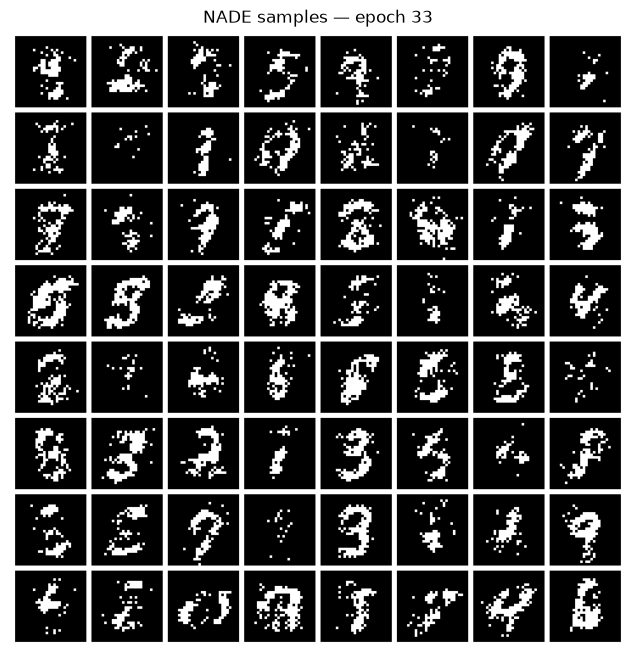

  batch 100: val NLL = 117.6871 (best 117.6871, 0/10) [saved ckpt_0133_nll117.6871.pt]
  batch 200: val NLL = 117.5498 (best 117.5498, 0/10) [saved ckpt_0134_nll117.5498.pt]
  batch 300: val NLL = 117.2906 (best 117.2906, 0/10) [saved ckpt_0135_nll117.2906.pt]
  batch 400: val NLL = 117.1009 (best 117.1009, 0/10) [saved ckpt_0136_nll117.1009.pt]
Epoch 34: train NLL = 117.1857


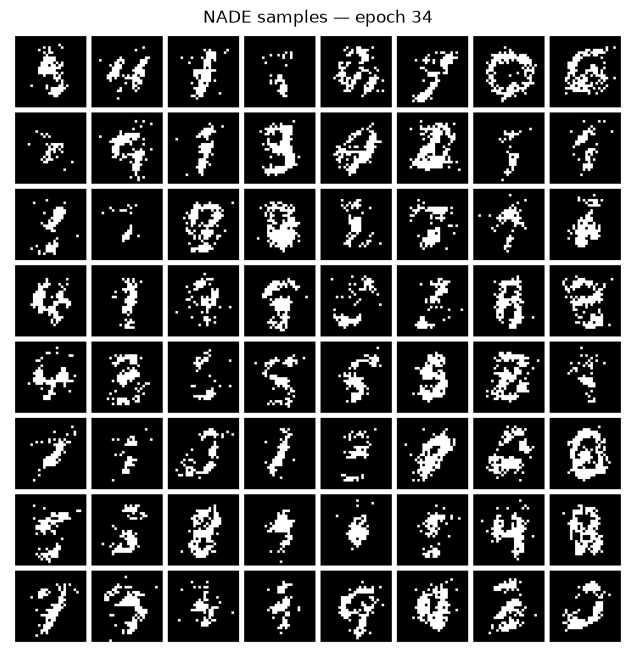

  batch 100: val NLL = 116.9976 (best 116.9976, 0/10) [saved ckpt_0137_nll116.9976.pt]
  batch 200: val NLL = 116.7622 (best 116.7622, 0/10) [saved ckpt_0138_nll116.7622.pt]
  batch 300: val NLL = 116.7945 (best 116.7622, 1/10) [saved ckpt_0139_nll116.7945.pt]
  batch 400: val NLL = 116.7167 (best 116.7167, 0/10) [saved ckpt_0140_nll116.7167.pt]
Epoch 35: train NLL = 116.6086


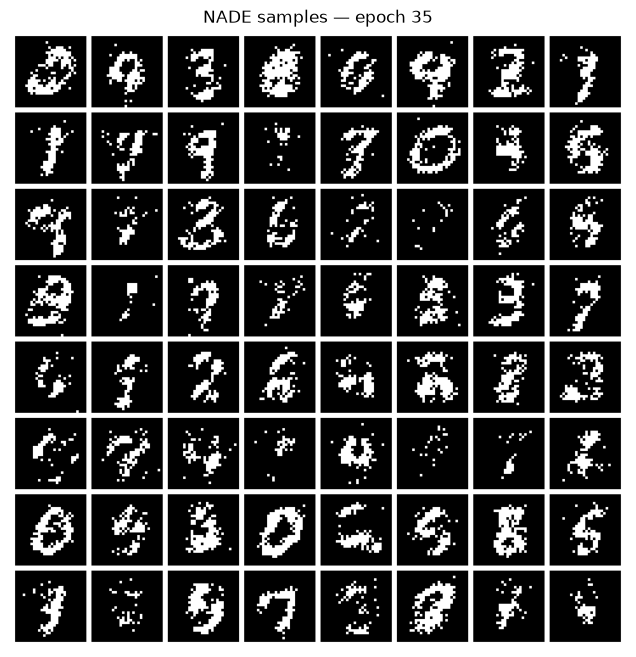

  batch 100: val NLL = 116.4779 (best 116.4779, 0/10) [saved ckpt_0141_nll116.4779.pt]
  batch 200: val NLL = 116.3120 (best 116.3120, 0/10) [saved ckpt_0142_nll116.3120.pt]
  batch 300: val NLL = 116.2508 (best 116.2508, 0/10) [saved ckpt_0143_nll116.2508.pt]
  batch 400: val NLL = 116.0031 (best 116.0031, 0/10) [saved ckpt_0144_nll116.0031.pt]
Epoch 36: train NLL = 116.0010


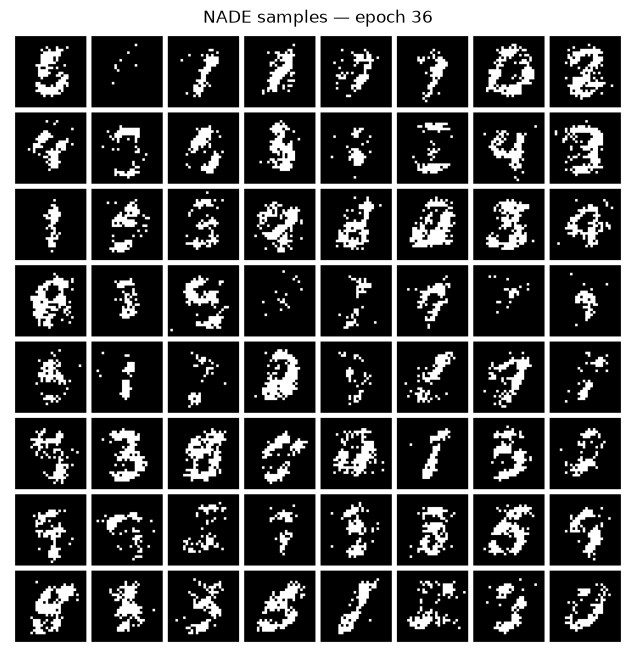

  batch 100: val NLL = 115.9038 (best 115.9038, 0/10) [saved ckpt_0145_nll115.9038.pt]
  batch 200: val NLL = 115.7418 (best 115.7418, 0/10) [saved ckpt_0146_nll115.7418.pt]
  batch 300: val NLL = 115.6802 (best 115.6802, 0/10) [saved ckpt_0147_nll115.6802.pt]
  batch 400: val NLL = 115.5941 (best 115.5941, 0/10) [saved ckpt_0148_nll115.5941.pt]
Epoch 37: train NLL = 115.4995


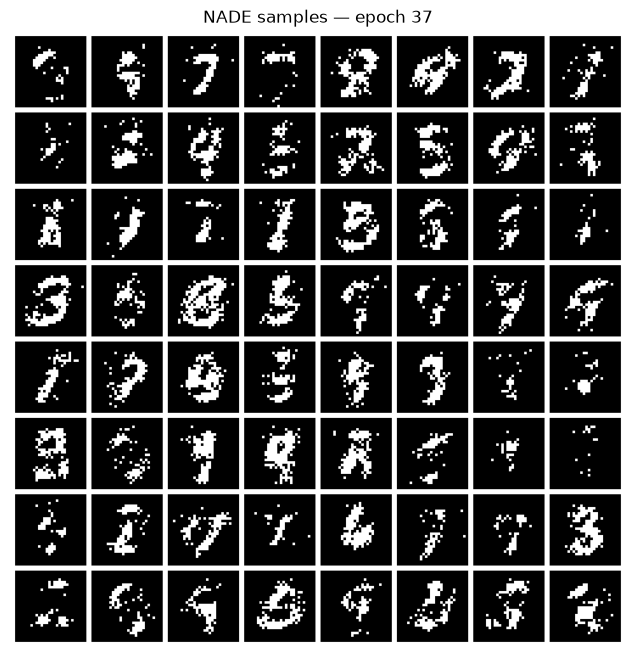

  batch 100: val NLL = 115.3410 (best 115.3410, 0/10) [saved ckpt_0149_nll115.3410.pt]
  batch 200: val NLL = 115.2139 (best 115.2139, 0/10) [saved ckpt_0150_nll115.2139.pt]
  batch 300: val NLL = 115.1781 (best 115.1781, 0/10) [saved ckpt_0151_nll115.1781.pt]
  batch 400: val NLL = 114.9315 (best 114.9315, 0/10) [saved ckpt_0152_nll114.9315.pt]
Epoch 38: train NLL = 114.9454


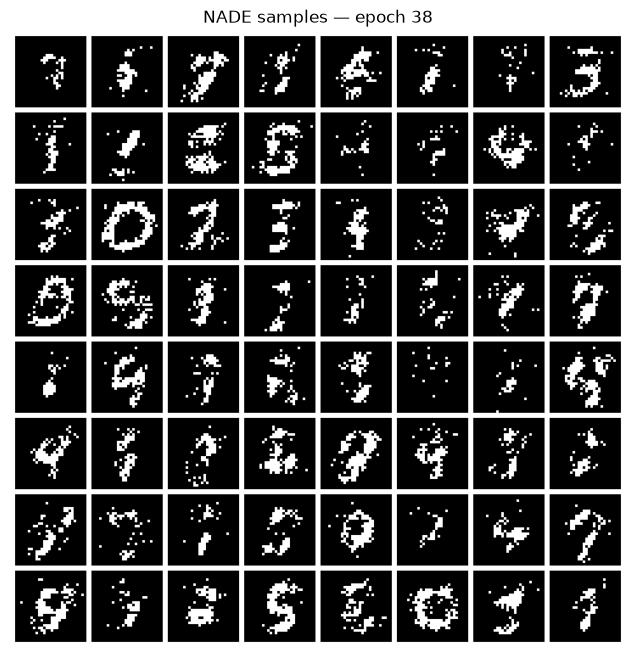

  batch 100: val NLL = 114.9818 (best 114.9315, 1/10) [saved ckpt_0153_nll114.9818.pt]
  batch 200: val NLL = 114.9291 (best 114.9291, 0/10) [saved ckpt_0154_nll114.9291.pt]
  batch 300: val NLL = 114.5029 (best 114.5029, 0/10) [saved ckpt_0155_nll114.5029.pt]
  batch 400: val NLL = 114.4491 (best 114.4491, 0/10) [saved ckpt_0156_nll114.4491.pt]
Epoch 39: train NLL = 114.4255


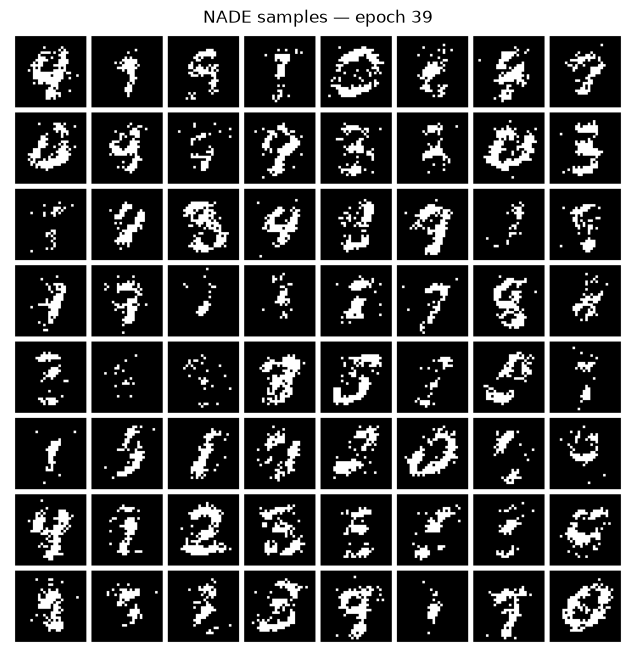

  batch 100: val NLL = 114.3837 (best 114.3837, 0/10) [saved ckpt_0157_nll114.3837.pt]
  batch 200: val NLL = 114.3713 (best 114.3713, 0/10) [saved ckpt_0158_nll114.3713.pt]
  batch 300: val NLL = 114.2684 (best 114.2684, 0/10) [saved ckpt_0159_nll114.2684.pt]
  batch 400: val NLL = 114.1674 (best 114.1674, 0/10) [saved ckpt_0160_nll114.1674.pt]
Epoch 40: train NLL = 113.9843


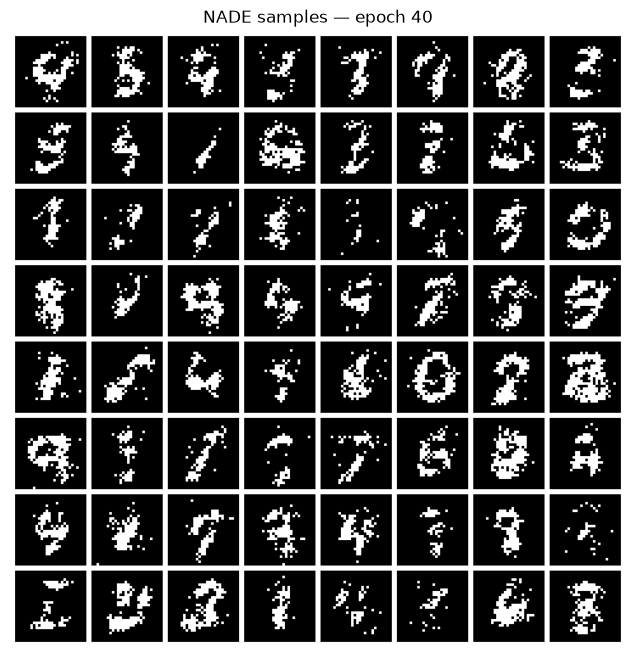

  batch 100: val NLL = 114.0289 (best 114.0289, 0/10) [saved ckpt_0161_nll114.0289.pt]
  batch 200: val NLL = 113.6863 (best 113.6863, 0/10) [saved ckpt_0162_nll113.6863.pt]
  batch 300: val NLL = 113.6125 (best 113.6125, 0/10) [saved ckpt_0163_nll113.6125.pt]
  batch 400: val NLL = 113.5031 (best 113.5031, 0/10) [saved ckpt_0164_nll113.5031.pt]
Epoch 41: train NLL = 113.4849


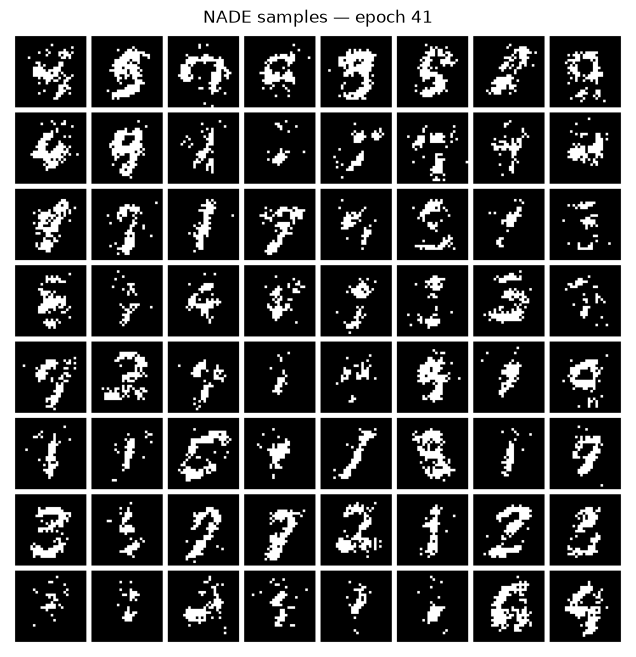

  batch 100: val NLL = 113.5027 (best 113.5027, 0/10) [saved ckpt_0165_nll113.5027.pt]
  batch 200: val NLL = 113.3806 (best 113.3806, 0/10) [saved ckpt_0166_nll113.3806.pt]
  batch 300: val NLL = 113.2293 (best 113.2293, 0/10) [saved ckpt_0167_nll113.2293.pt]
  batch 400: val NLL = 113.3355 (best 113.2293, 1/10) [saved ckpt_0168_nll113.3355.pt]
Epoch 42: train NLL = 113.0231


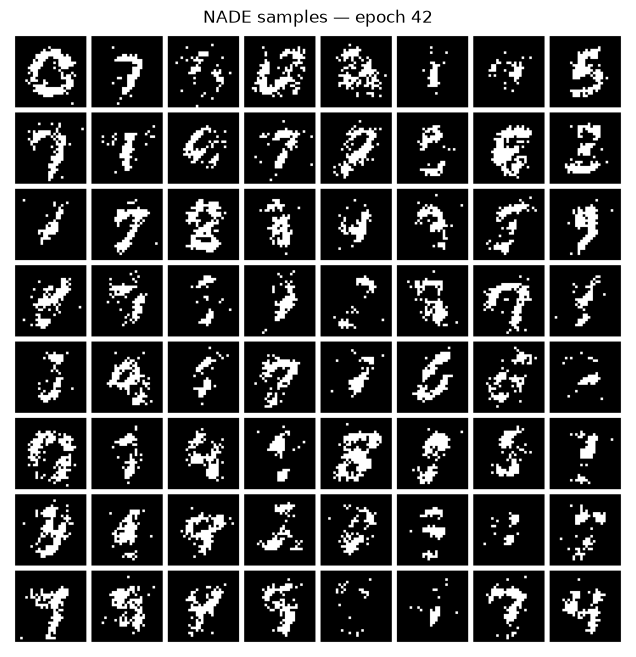

  batch 100: val NLL = 113.0030 (best 113.0030, 0/10) [saved ckpt_0169_nll113.0030.pt]
  batch 200: val NLL = 112.9966 (best 112.9966, 0/10) [saved ckpt_0170_nll112.9966.pt]
  batch 300: val NLL = 112.8998 (best 112.8998, 0/10) [saved ckpt_0171_nll112.8998.pt]
  batch 400: val NLL = 112.6792 (best 112.6792, 0/10) [saved ckpt_0172_nll112.6792.pt]
Epoch 43: train NLL = 112.6242


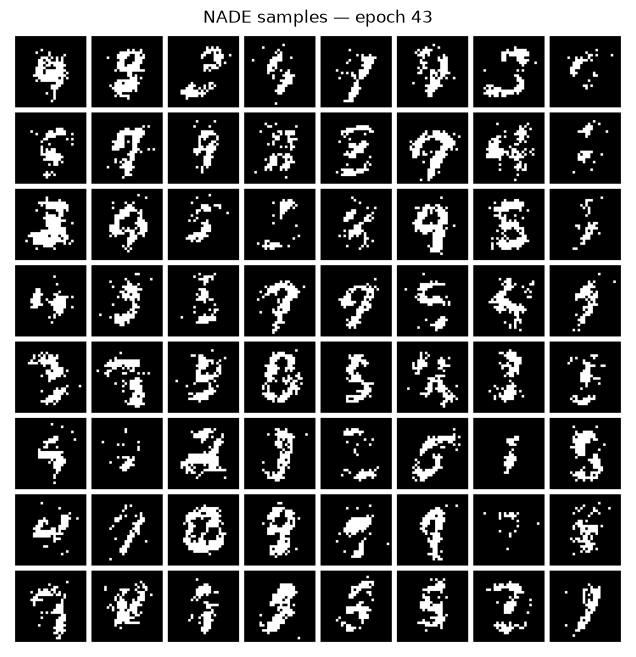

  batch 100: val NLL = 112.5620 (best 112.5620, 0/10) [saved ckpt_0173_nll112.5620.pt]
  batch 200: val NLL = 112.5748 (best 112.5620, 1/10) [saved ckpt_0174_nll112.5748.pt]
  batch 300: val NLL = 112.3788 (best 112.3788, 0/10) [saved ckpt_0175_nll112.3788.pt]
  batch 400: val NLL = 112.1877 (best 112.1877, 0/10) [saved ckpt_0176_nll112.1877.pt]
Epoch 44: train NLL = 112.2018


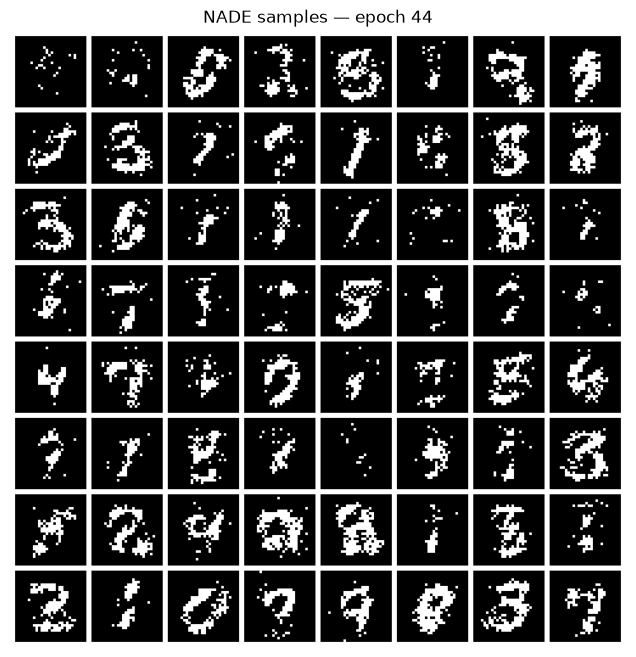

  batch 100: val NLL = 112.2338 (best 112.1877, 1/10) [saved ckpt_0177_nll112.2338.pt]
  batch 200: val NLL = 112.1232 (best 112.1232, 0/10) [saved ckpt_0178_nll112.1232.pt]
  batch 300: val NLL = 112.0693 (best 112.0693, 0/10) [saved ckpt_0179_nll112.0693.pt]
  batch 400: val NLL = 111.9829 (best 111.9829, 0/10) [saved ckpt_0180_nll111.9829.pt]
Epoch 45: train NLL = 111.7985


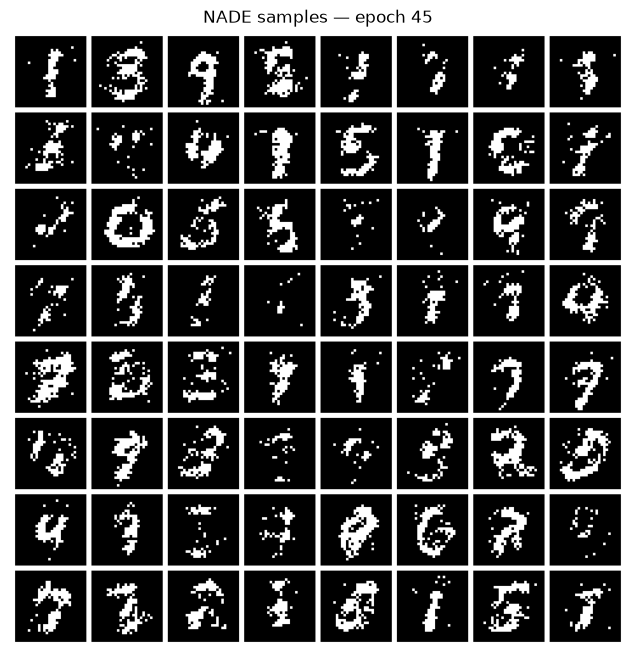

  batch 100: val NLL = 111.9391 (best 111.9391, 0/10) [saved ckpt_0181_nll111.9391.pt]
  batch 200: val NLL = 111.7193 (best 111.7193, 0/10) [saved ckpt_0182_nll111.7193.pt]
  batch 300: val NLL = 111.5993 (best 111.5993, 0/10) [saved ckpt_0183_nll111.5993.pt]
  batch 400: val NLL = 111.5095 (best 111.5095, 0/10) [saved ckpt_0184_nll111.5095.pt]
Epoch 46: train NLL = 111.4428


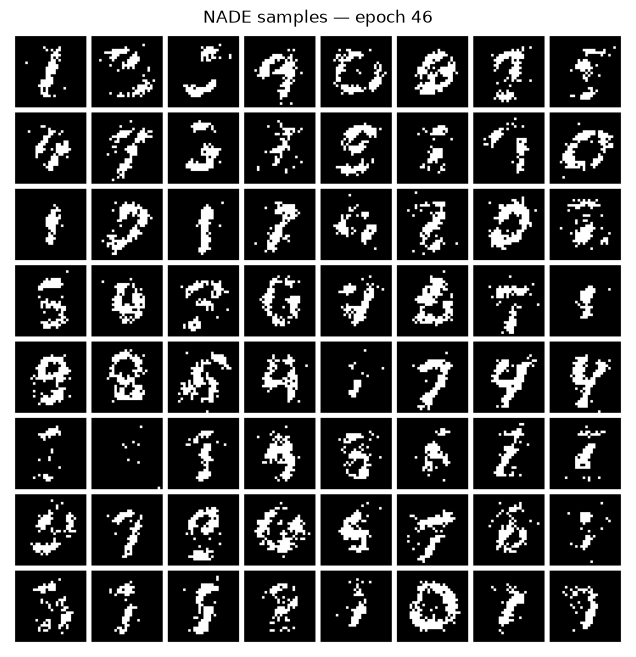

  batch 100: val NLL = 111.2355 (best 111.2355, 0/10) [saved ckpt_0185_nll111.2355.pt]
  batch 200: val NLL = 111.4189 (best 111.2355, 1/10) [saved ckpt_0186_nll111.4189.pt]
  batch 300: val NLL = 111.2619 (best 111.2355, 2/10) [saved ckpt_0187_nll111.2619.pt]
  batch 400: val NLL = 111.2864 (best 111.2355, 3/10) [saved ckpt_0188_nll111.2864.pt]
Epoch 47: train NLL = 111.0493


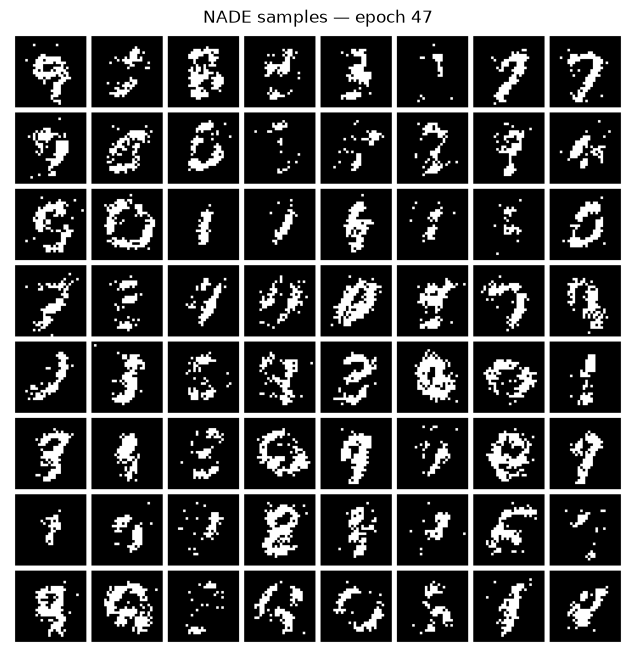

  batch 100: val NLL = 111.0016 (best 111.0016, 0/10) [saved ckpt_0189_nll111.0016.pt]
  batch 200: val NLL = 110.9799 (best 110.9799, 0/10) [saved ckpt_0190_nll110.9799.pt]
  batch 300: val NLL = 111.0234 (best 110.9799, 1/10) [saved ckpt_0191_nll111.0234.pt]
  batch 400: val NLL = 111.0425 (best 110.9799, 2/10) [saved ckpt_0192_nll111.0425.pt]
Epoch 48: train NLL = 110.6814


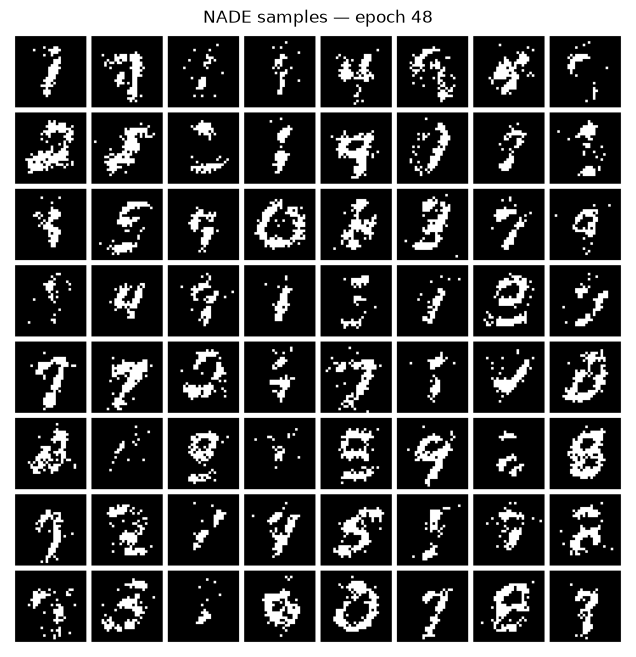

  batch 100: val NLL = 110.7135 (best 110.7135, 0/10) [saved ckpt_0193_nll110.7135.pt]
  batch 200: val NLL = 110.5090 (best 110.5090, 0/10) [saved ckpt_0194_nll110.5090.pt]
  batch 300: val NLL = 110.6211 (best 110.5090, 1/10) [saved ckpt_0195_nll110.6211.pt]
  batch 400: val NLL = 110.5438 (best 110.5090, 2/10) [saved ckpt_0196_nll110.5438.pt]
Epoch 49: train NLL = 110.3535


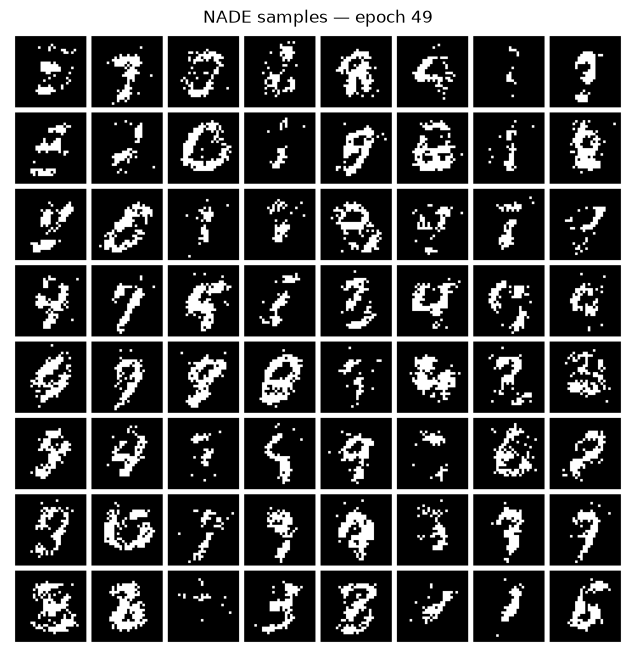

  batch 100: val NLL = 110.3264 (best 110.3264, 0/10) [saved ckpt_0197_nll110.3264.pt]
  batch 200: val NLL = 110.2190 (best 110.2190, 0/10) [saved ckpt_0198_nll110.2190.pt]
  batch 300: val NLL = 110.2666 (best 110.2190, 1/10) [saved ckpt_0199_nll110.2666.pt]
  batch 400: val NLL = 110.1639 (best 110.1639, 0/10) [saved ckpt_0200_nll110.1639.pt]
Epoch 50: train NLL = 110.0112


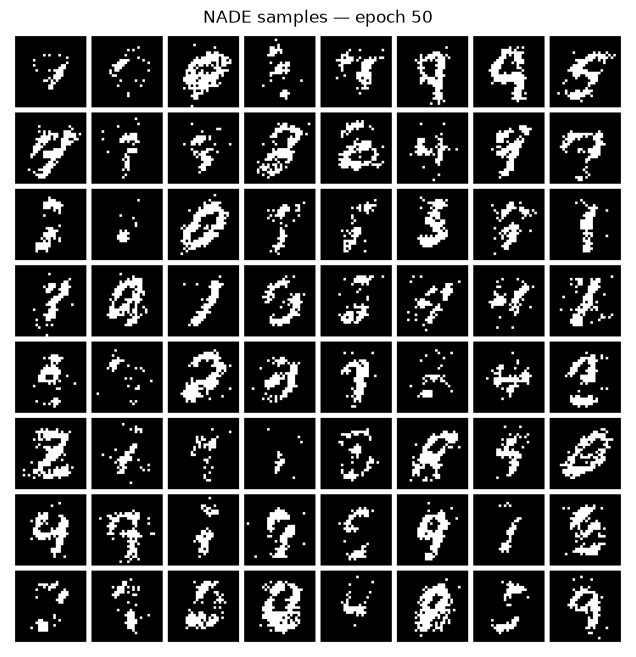

  batch 100: val NLL = 110.0578 (best 110.0578, 0/10) [saved ckpt_0201_nll110.0578.pt]
  batch 200: val NLL = 110.1397 (best 110.0578, 1/10) [saved ckpt_0202_nll110.1397.pt]
  batch 300: val NLL = 109.8721 (best 109.8721, 0/10) [saved ckpt_0203_nll109.8721.pt]
  batch 400: val NLL = 109.9120 (best 109.8721, 1/10) [saved ckpt_0204_nll109.9120.pt]
Epoch 51: train NLL = 109.6338


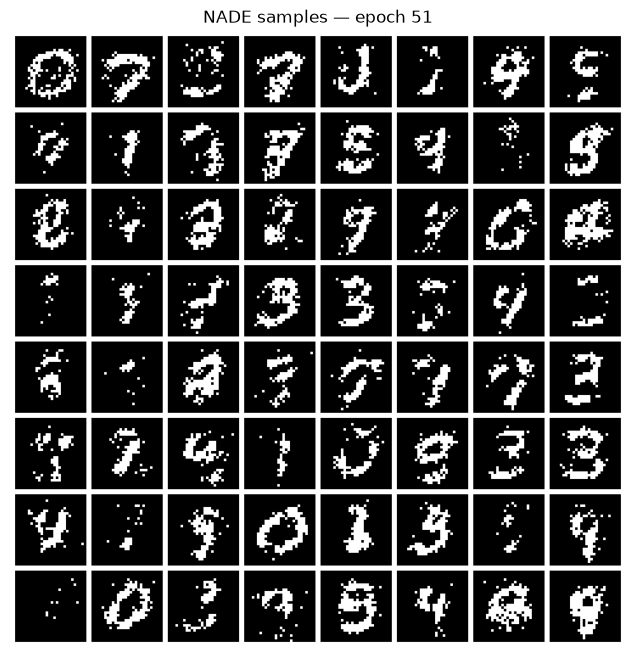

  batch 100: val NLL = 109.7893 (best 109.7893, 0/10) [saved ckpt_0205_nll109.7893.pt]
  batch 200: val NLL = 109.7023 (best 109.7023, 0/10) [saved ckpt_0206_nll109.7023.pt]
  batch 300: val NLL = 109.5871 (best 109.5871, 0/10) [saved ckpt_0207_nll109.5871.pt]
  batch 400: val NLL = 109.4438 (best 109.4438, 0/10) [saved ckpt_0208_nll109.4438.pt]
Epoch 52: train NLL = 109.3463


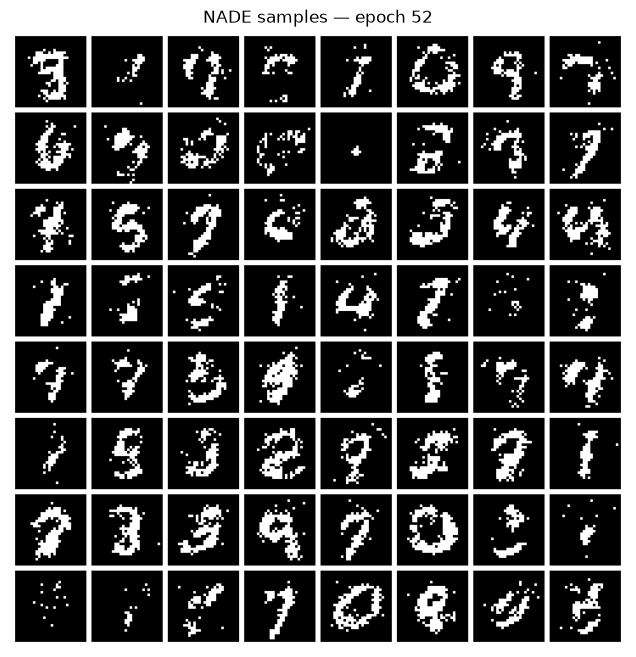

  batch 100: val NLL = 109.5261 (best 109.4438, 1/10) [saved ckpt_0209_nll109.5261.pt]
  batch 200: val NLL = 109.3000 (best 109.3000, 0/10) [saved ckpt_0210_nll109.3000.pt]
  batch 300: val NLL = 109.2517 (best 109.2517, 0/10) [saved ckpt_0211_nll109.2517.pt]
  batch 400: val NLL = 109.1011 (best 109.1011, 0/10) [saved ckpt_0212_nll109.1011.pt]
Epoch 53: train NLL = 109.0345


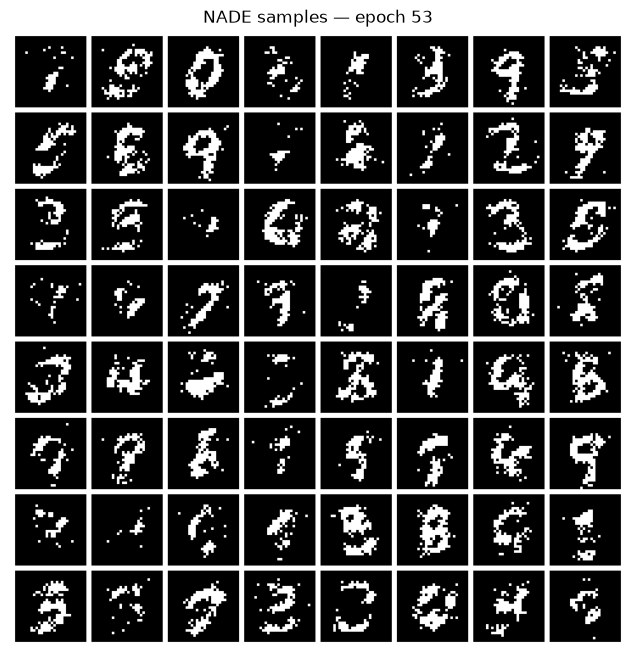

  batch 100: val NLL = 109.0285 (best 109.0285, 0/10) [saved ckpt_0213_nll109.0285.pt]
  batch 200: val NLL = 109.0083 (best 109.0083, 0/10) [saved ckpt_0214_nll109.0083.pt]
  batch 300: val NLL = 109.1562 (best 109.0083, 1/10) [saved ckpt_0215_nll109.1562.pt]
  batch 400: val NLL = 109.1108 (best 109.0083, 2/10) [saved ckpt_0216_nll109.1108.pt]
Epoch 54: train NLL = 108.7423


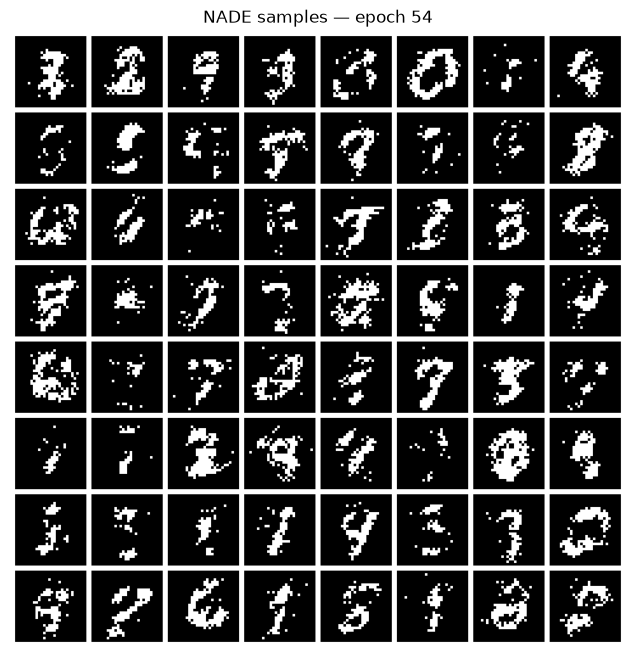

  batch 100: val NLL = 108.9260 (best 108.9260, 0/10) [saved ckpt_0217_nll108.9260.pt]
  batch 200: val NLL = 108.7781 (best 108.7781, 0/10) [saved ckpt_0218_nll108.7781.pt]
  batch 300: val NLL = 108.8321 (best 108.7781, 1/10) [saved ckpt_0219_nll108.8321.pt]
  batch 400: val NLL = 108.5432 (best 108.5432, 0/10) [saved ckpt_0220_nll108.5432.pt]
Epoch 55: train NLL = 108.4733


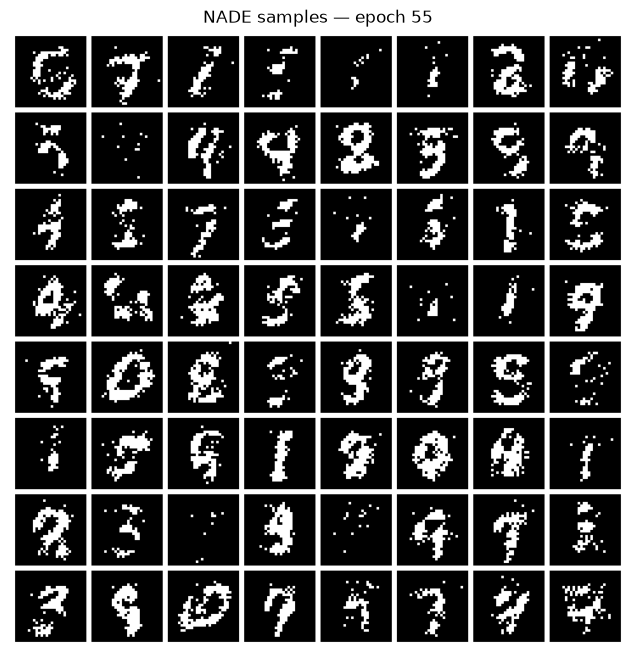

  batch 100: val NLL = 108.5679 (best 108.5432, 1/10) [saved ckpt_0221_nll108.5679.pt]
  batch 200: val NLL = 108.6018 (best 108.5432, 2/10) [saved ckpt_0222_nll108.6018.pt]
  batch 300: val NLL = 108.3825 (best 108.3825, 0/10) [saved ckpt_0223_nll108.3825.pt]
  batch 400: val NLL = 108.2837 (best 108.2837, 0/10) [saved ckpt_0224_nll108.2837.pt]
Epoch 56: train NLL = 108.1784


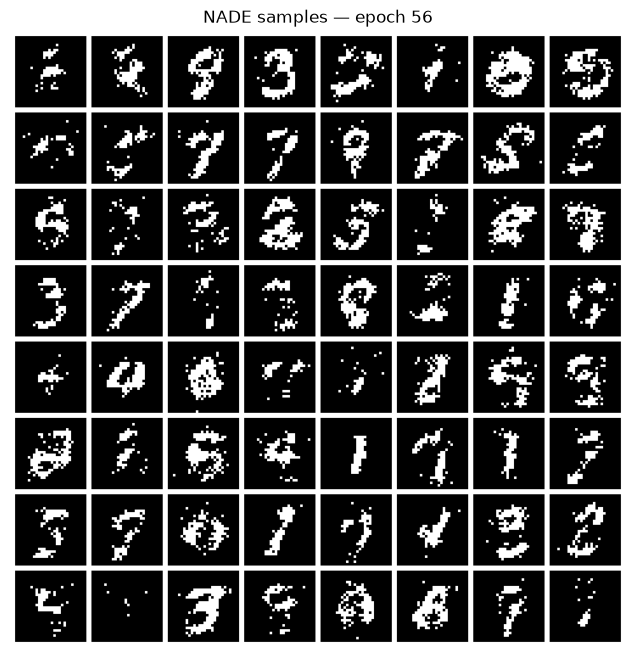

  batch 100: val NLL = 108.4080 (best 108.2837, 1/10) [saved ckpt_0225_nll108.4080.pt]
  batch 200: val NLL = 108.2007 (best 108.2007, 0/10) [saved ckpt_0226_nll108.2007.pt]
  batch 300: val NLL = 108.2373 (best 108.2007, 1/10) [saved ckpt_0227_nll108.2373.pt]
  batch 400: val NLL = 108.1772 (best 108.1772, 0/10) [saved ckpt_0228_nll108.1772.pt]
Epoch 57: train NLL = 107.8416


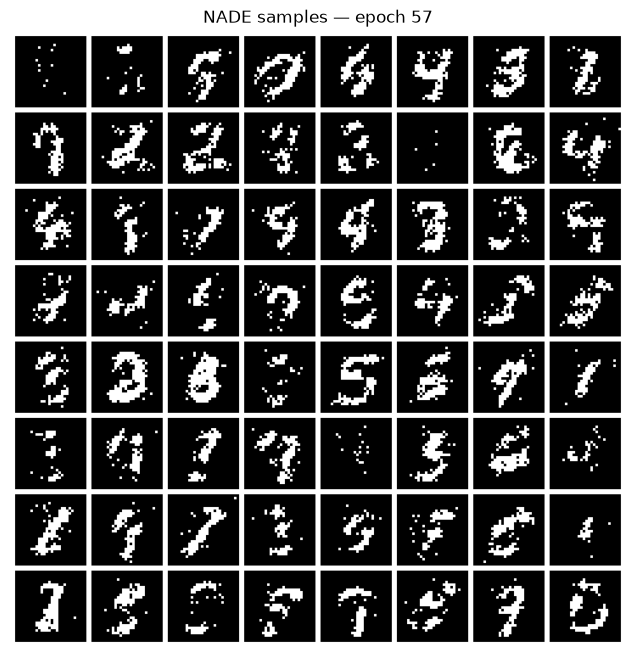

  batch 100: val NLL = 108.0801 (best 108.0801, 0/10) [saved ckpt_0229_nll108.0801.pt]
  batch 200: val NLL = 107.9802 (best 107.9802, 0/10) [saved ckpt_0230_nll107.9802.pt]
  batch 300: val NLL = 107.8887 (best 107.8887, 0/10) [saved ckpt_0231_nll107.8887.pt]
  batch 400: val NLL = 107.7783 (best 107.7783, 0/10) [saved ckpt_0232_nll107.7783.pt]
Epoch 58: train NLL = 107.6462


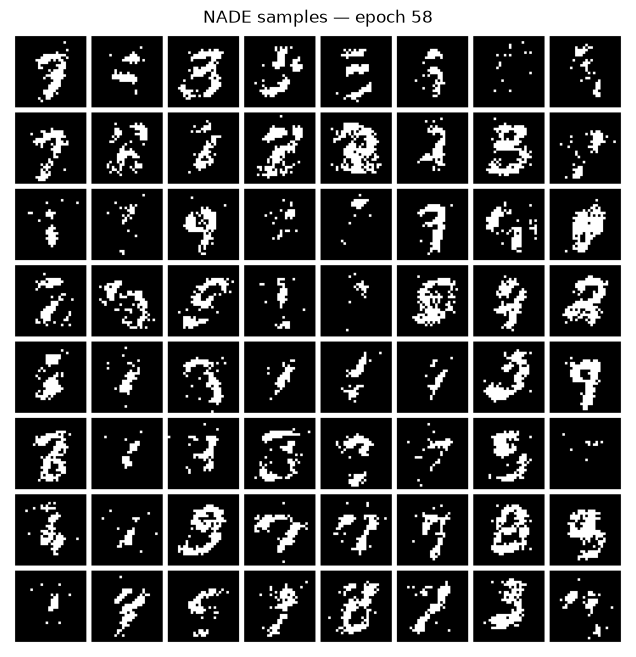

  batch 100: val NLL = 107.5889 (best 107.5889, 0/10) [saved ckpt_0233_nll107.5889.pt]
  batch 200: val NLL = 107.8462 (best 107.5889, 1/10) [saved ckpt_0234_nll107.8462.pt]
  batch 300: val NLL = 107.6092 (best 107.5889, 2/10) [saved ckpt_0235_nll107.6092.pt]
  batch 400: val NLL = 107.6039 (best 107.5889, 3/10) [saved ckpt_0236_nll107.6039.pt]
Epoch 59: train NLL = 107.3334


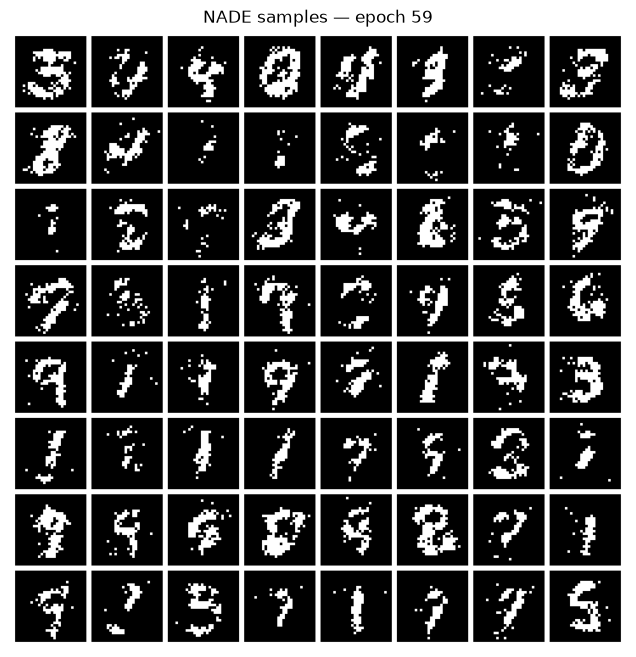

  batch 100: val NLL = 107.3838 (best 107.3838, 0/10) [saved ckpt_0237_nll107.3838.pt]
  batch 200: val NLL = 107.3601 (best 107.3601, 0/10) [saved ckpt_0238_nll107.3601.pt]
  batch 300: val NLL = 107.4174 (best 107.3601, 1/10) [saved ckpt_0239_nll107.4174.pt]
  batch 400: val NLL = 107.3795 (best 107.3601, 2/10) [saved ckpt_0240_nll107.3795.pt]
Epoch 60: train NLL = 107.1303


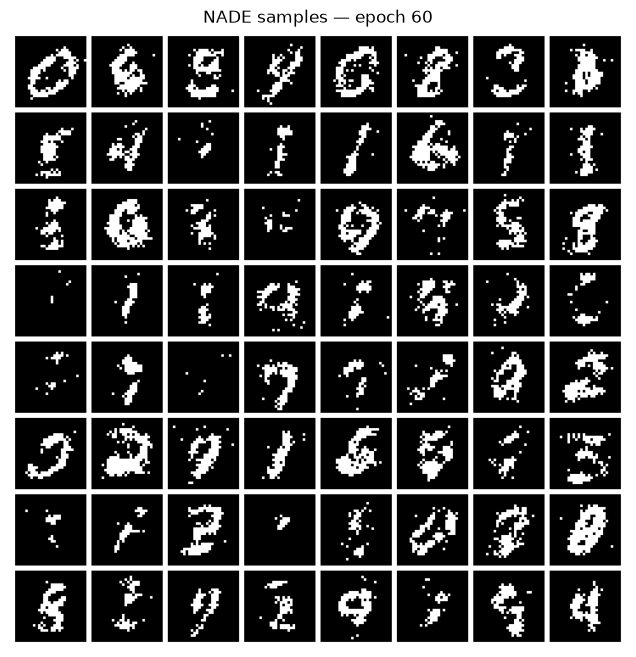

  batch 100: val NLL = 107.4584 (best 107.3601, 3/10) [saved ckpt_0241_nll107.4584.pt]
  batch 200: val NLL = 107.1471 (best 107.1471, 0/10) [saved ckpt_0242_nll107.1471.pt]
  batch 300: val NLL = 107.1391 (best 107.1391, 0/10) [saved ckpt_0243_nll107.1391.pt]
  batch 400: val NLL = 106.9404 (best 106.9404, 0/10) [saved ckpt_0244_nll106.9404.pt]
Epoch 61: train NLL = 106.8629


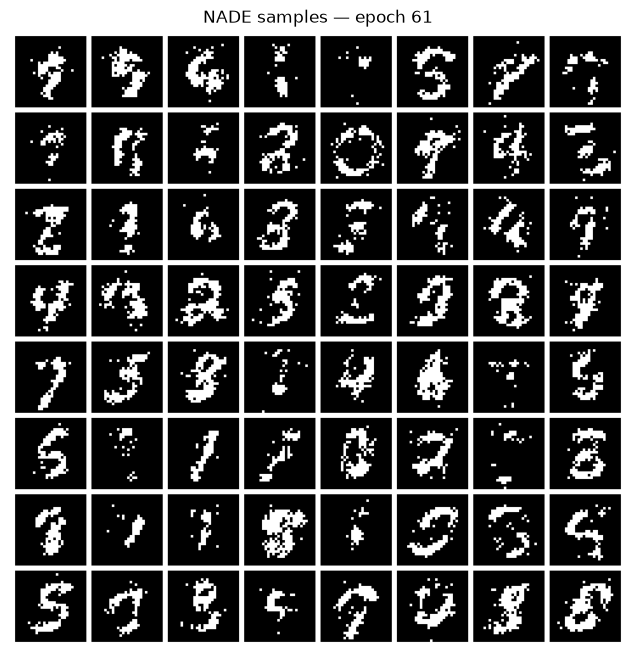

  batch 100: val NLL = 106.9048 (best 106.9048, 0/10) [saved ckpt_0245_nll106.9048.pt]
  batch 200: val NLL = 106.8563 (best 106.8563, 0/10) [saved ckpt_0246_nll106.8563.pt]
  batch 300: val NLL = 106.7472 (best 106.7472, 0/10) [saved ckpt_0247_nll106.7472.pt]
  batch 400: val NLL = 106.7258 (best 106.7258, 0/10) [saved ckpt_0248_nll106.7258.pt]
Epoch 62: train NLL = 106.5952


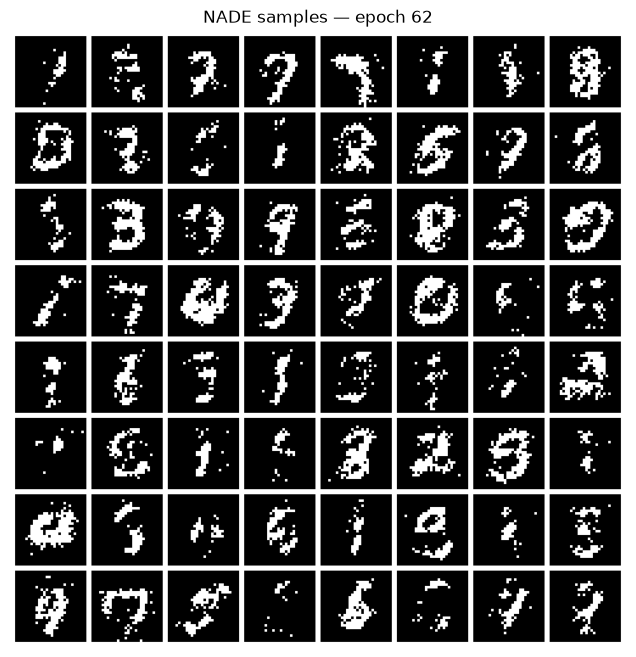

  batch 100: val NLL = 106.8884 (best 106.7258, 1/10) [saved ckpt_0249_nll106.8884.pt]
  batch 200: val NLL = 106.8934 (best 106.7258, 2/10) [saved ckpt_0250_nll106.8934.pt]
  batch 300: val NLL = 106.8166 (best 106.7258, 3/10) [saved ckpt_0251_nll106.8166.pt]
  batch 400: val NLL = 106.6525 (best 106.6525, 0/10) [saved ckpt_0252_nll106.6525.pt]
Epoch 63: train NLL = 106.3564


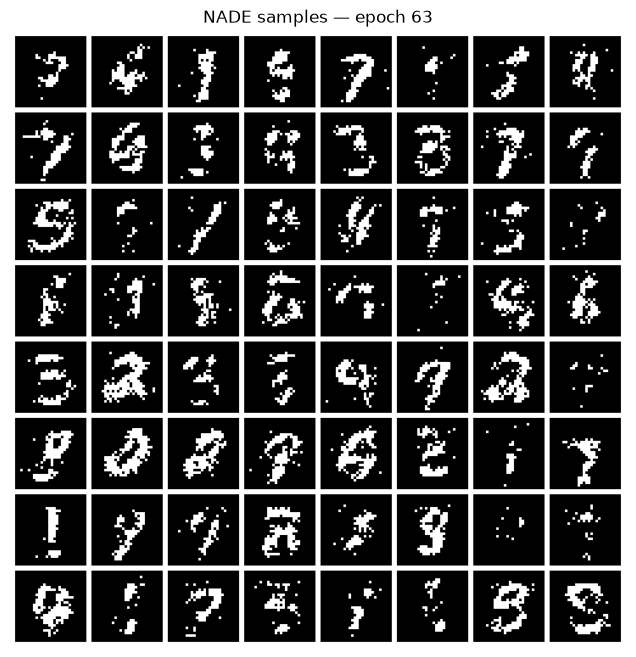

  batch 100: val NLL = 106.5115 (best 106.5115, 0/10) [saved ckpt_0253_nll106.5115.pt]
  batch 200: val NLL = 106.3877 (best 106.3877, 0/10) [saved ckpt_0254_nll106.3877.pt]
  batch 300: val NLL = 106.5615 (best 106.3877, 1/10) [saved ckpt_0255_nll106.5615.pt]
  batch 400: val NLL = 106.3283 (best 106.3283, 0/10) [saved ckpt_0256_nll106.3283.pt]
Epoch 64: train NLL = 106.1602


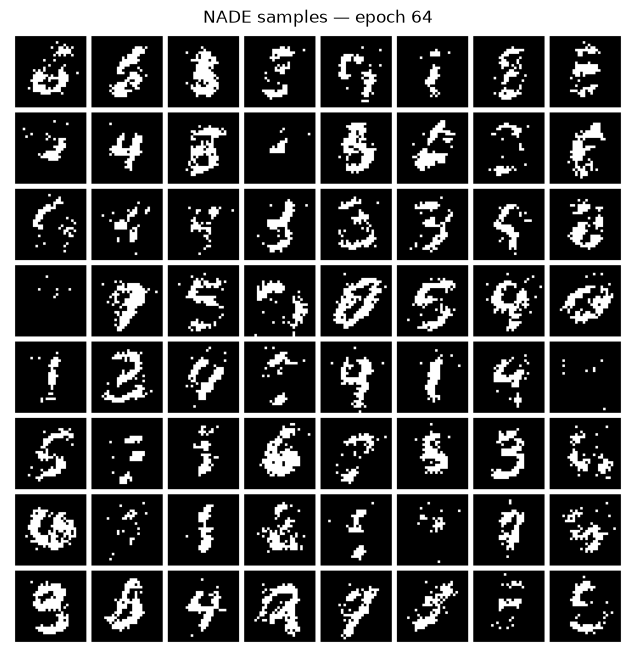

  batch 100: val NLL = 106.3619 (best 106.3283, 1/10) [saved ckpt_0257_nll106.3619.pt]
  batch 200: val NLL = 106.1826 (best 106.1826, 0/10) [saved ckpt_0258_nll106.1826.pt]
  batch 300: val NLL = 106.2357 (best 106.1826, 1/10) [saved ckpt_0259_nll106.2357.pt]
  batch 400: val NLL = 106.0879 (best 106.0879, 0/10) [saved ckpt_0260_nll106.0879.pt]
Epoch 65: train NLL = 105.9183


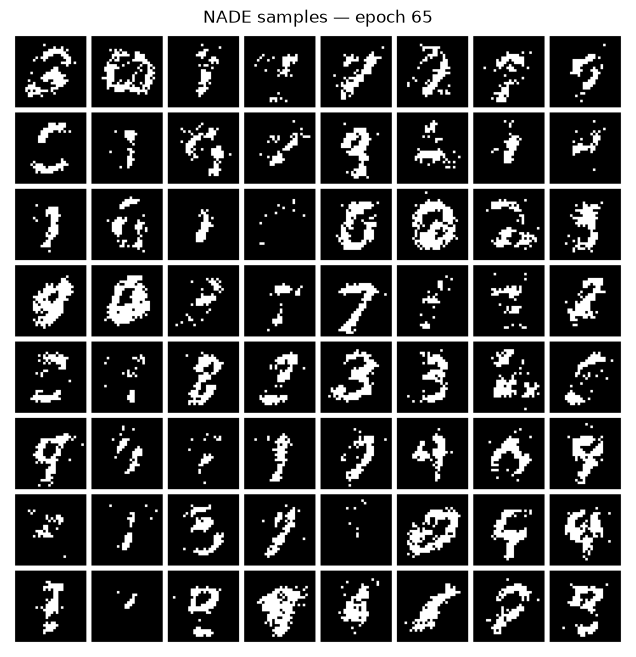

  batch 100: val NLL = 106.1342 (best 106.0879, 1/10) [saved ckpt_0261_nll106.1342.pt]
  batch 200: val NLL = 105.9934 (best 105.9934, 0/10) [saved ckpt_0262_nll105.9934.pt]
  batch 300: val NLL = 106.0256 (best 105.9934, 1/10) [saved ckpt_0263_nll106.0256.pt]
  batch 400: val NLL = 106.0291 (best 105.9934, 2/10) [saved ckpt_0264_nll106.0291.pt]
Epoch 66: train NLL = 105.6675


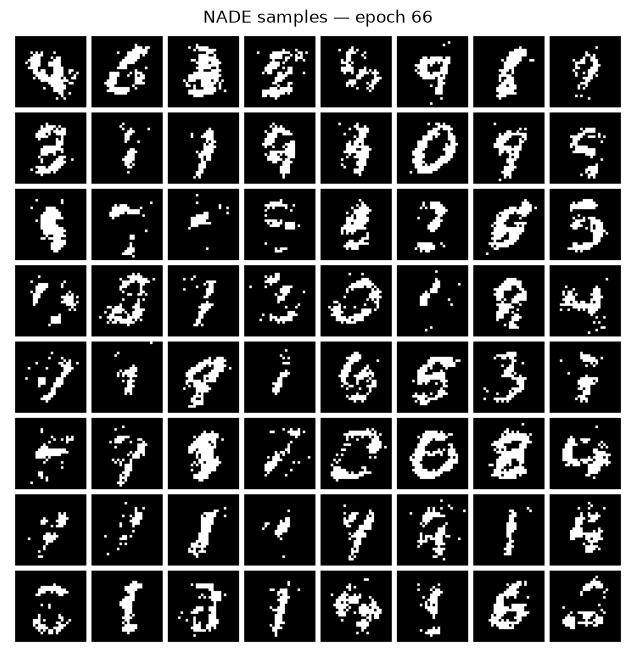

  batch 100: val NLL = 105.8907 (best 105.8907, 0/10) [saved ckpt_0265_nll105.8907.pt]
  batch 200: val NLL = 105.8131 (best 105.8131, 0/10) [saved ckpt_0266_nll105.8131.pt]
  batch 300: val NLL = 105.7280 (best 105.7280, 0/10) [saved ckpt_0267_nll105.7280.pt]
  batch 400: val NLL = 105.8174 (best 105.7280, 1/10) [saved ckpt_0268_nll105.8174.pt]
Epoch 67: train NLL = 105.4830


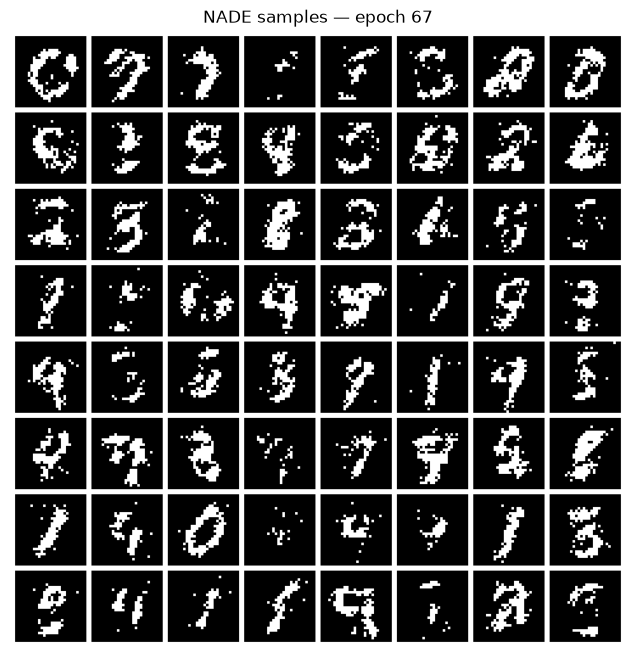

Transient error Service Unavailable encountered while exporting metrics batch, retrying in 0.84s.


  batch 100: val NLL = 105.7146 (best 105.7146, 0/10) [saved ckpt_0269_nll105.7146.pt]
  batch 200: val NLL = 105.5206 (best 105.5206, 0/10) [saved ckpt_0270_nll105.5206.pt]
  batch 300: val NLL = 105.5003 (best 105.5003, 0/10) [saved ckpt_0271_nll105.5003.pt]
  batch 400: val NLL = 105.5755 (best 105.5003, 1/10) [saved ckpt_0272_nll105.5755.pt]
Epoch 68: train NLL = 105.2543


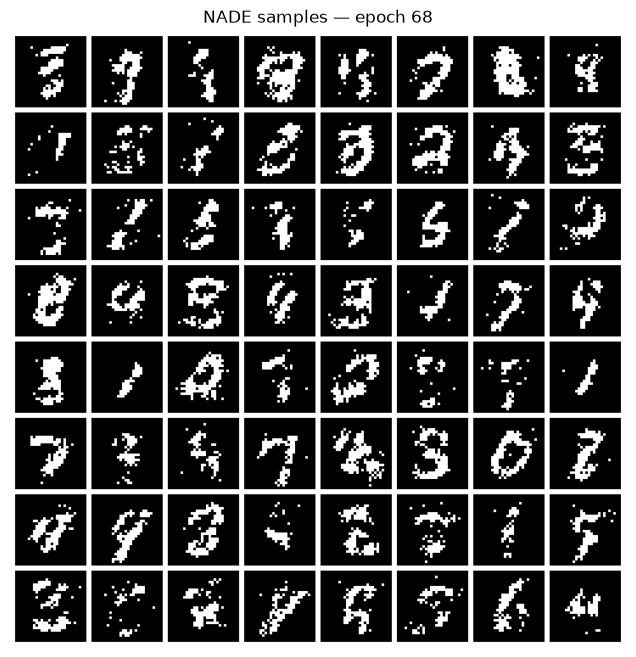

  batch 100: val NLL = 105.5203 (best 105.5003, 2/10) [saved ckpt_0273_nll105.5203.pt]
  batch 200: val NLL = 105.3700 (best 105.3700, 0/10) [saved ckpt_0274_nll105.3700.pt]
  batch 300: val NLL = 105.2799 (best 105.2799, 0/10) [saved ckpt_0275_nll105.2799.pt]
  batch 400: val NLL = 105.3811 (best 105.2799, 1/10) [saved ckpt_0276_nll105.3811.pt]
Epoch 69: train NLL = 105.0620


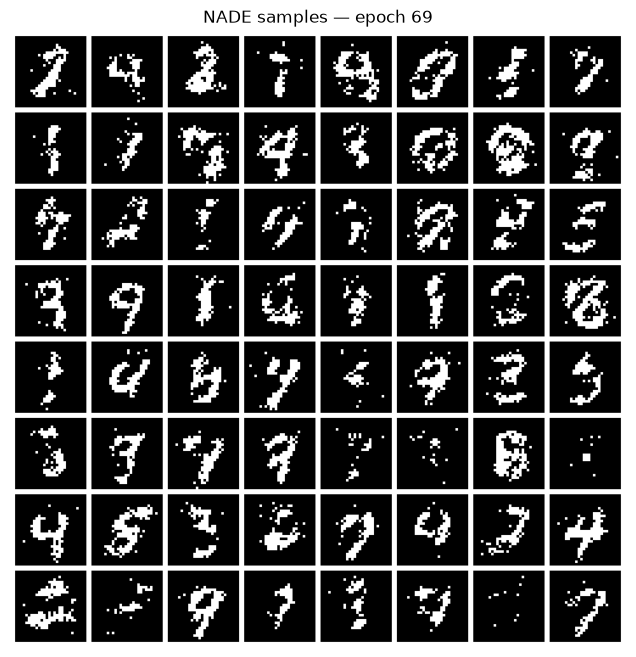

  batch 100: val NLL = 105.2943 (best 105.2799, 2/10) [saved ckpt_0277_nll105.2943.pt]
  batch 200: val NLL = 105.2236 (best 105.2236, 0/10) [saved ckpt_0278_nll105.2236.pt]
  batch 300: val NLL = 105.2475 (best 105.2236, 1/10) [saved ckpt_0279_nll105.2475.pt]
  batch 400: val NLL = 105.1596 (best 105.1596, 0/10) [saved ckpt_0280_nll105.1596.pt]
Epoch 70: train NLL = 104.8886


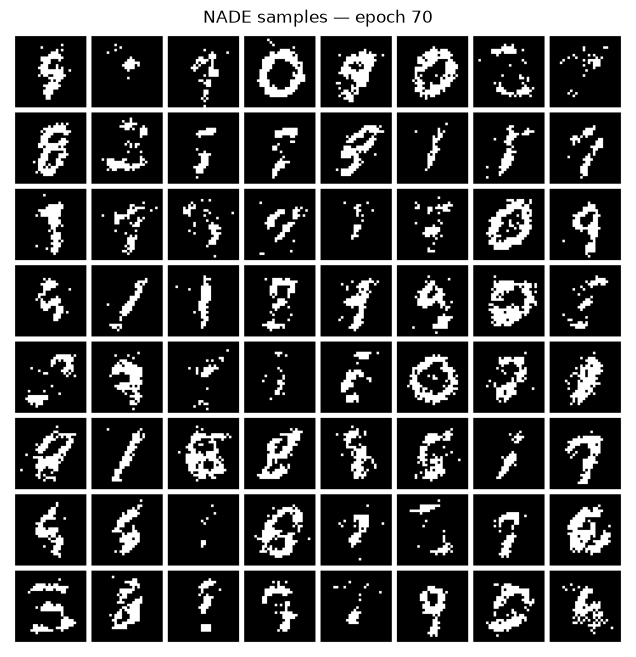

  batch 100: val NLL = 105.1102 (best 105.1102, 0/10) [saved ckpt_0281_nll105.1102.pt]
  batch 200: val NLL = 105.1345 (best 105.1102, 1/10) [saved ckpt_0282_nll105.1345.pt]
  batch 300: val NLL = 104.9208 (best 104.9208, 0/10) [saved ckpt_0283_nll104.9208.pt]
  batch 400: val NLL = 105.1039 (best 104.9208, 1/10) [saved ckpt_0284_nll105.1039.pt]
Epoch 71: train NLL = 104.6565


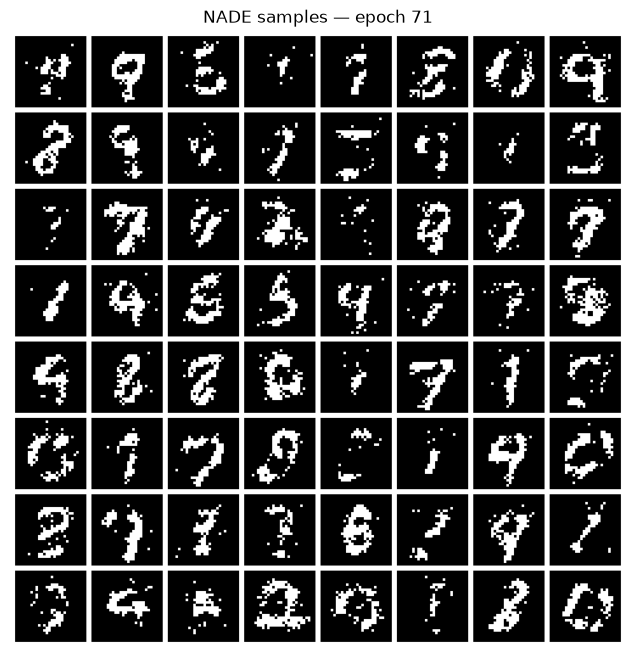

  batch 100: val NLL = 104.8519 (best 104.8519, 0/10) [saved ckpt_0285_nll104.8519.pt]
  batch 200: val NLL = 104.7432 (best 104.7432, 0/10) [saved ckpt_0286_nll104.7432.pt]
  batch 300: val NLL = 104.7668 (best 104.7432, 1/10) [saved ckpt_0287_nll104.7668.pt]
  batch 400: val NLL = 104.7849 (best 104.7432, 2/10) [saved ckpt_0288_nll104.7849.pt]
Epoch 72: train NLL = 104.4827


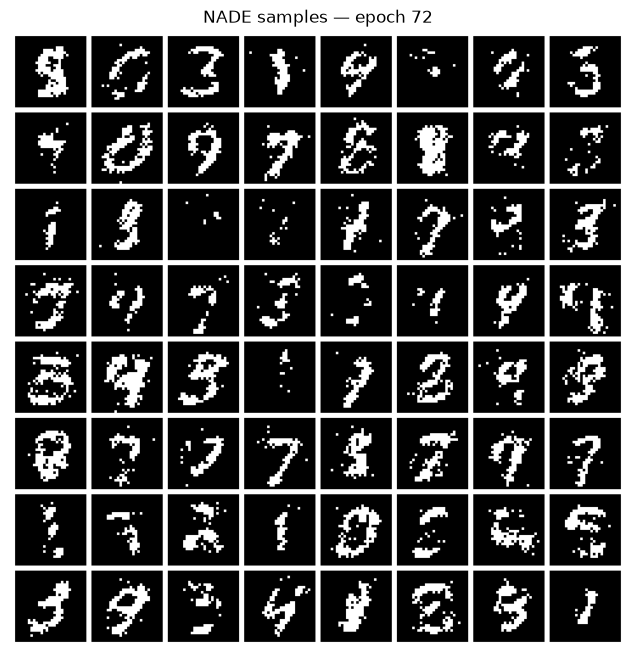

  batch 100: val NLL = 104.6188 (best 104.6188, 0/10) [saved ckpt_0289_nll104.6188.pt]
  batch 200: val NLL = 104.8143 (best 104.6188, 1/10) [saved ckpt_0290_nll104.8143.pt]
  batch 300: val NLL = 104.7805 (best 104.6188, 2/10) [saved ckpt_0291_nll104.7805.pt]
  batch 400: val NLL = 104.7287 (best 104.6188, 3/10) [saved ckpt_0292_nll104.7287.pt]
Epoch 73: train NLL = 104.3086


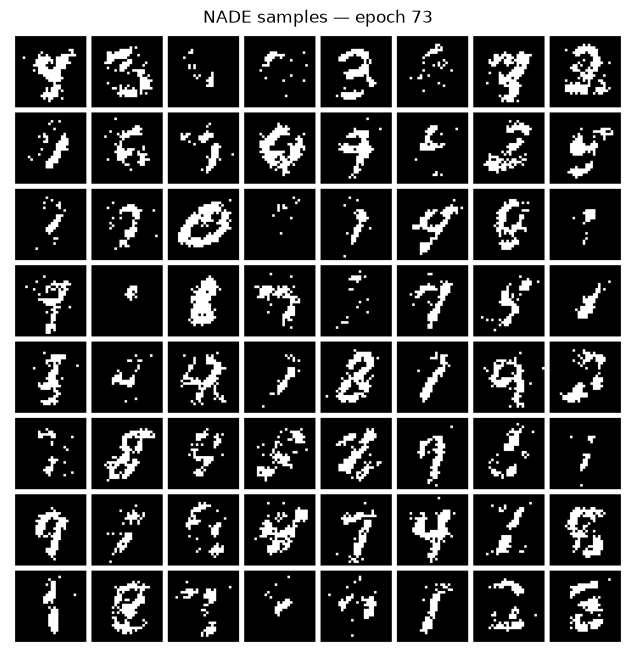

  batch 100: val NLL = 104.7763 (best 104.6188, 4/10) [saved ckpt_0293_nll104.7763.pt]
  batch 200: val NLL = 104.3971 (best 104.3971, 0/10) [saved ckpt_0294_nll104.3971.pt]
  batch 300: val NLL = 104.5360 (best 104.3971, 1/10) [saved ckpt_0295_nll104.5360.pt]
  batch 400: val NLL = 104.4076 (best 104.3971, 2/10) [saved ckpt_0296_nll104.4076.pt]
Epoch 74: train NLL = 104.1321


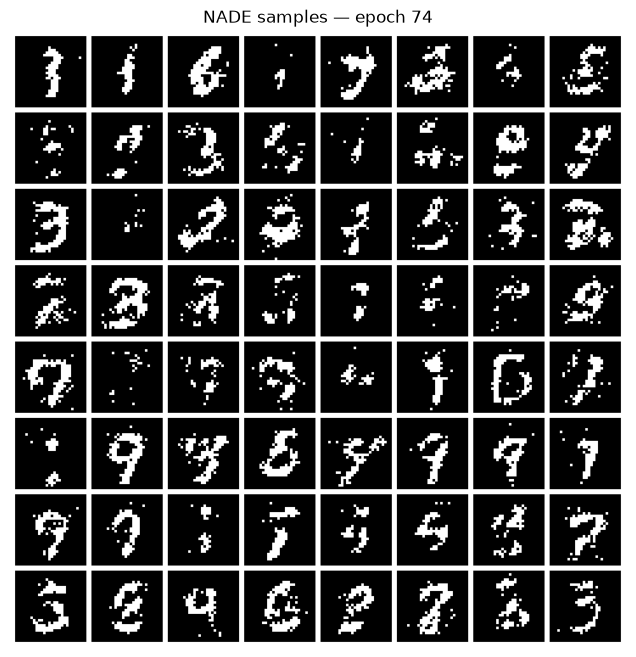

  batch 100: val NLL = 104.2942 (best 104.2942, 0/10) [saved ckpt_0297_nll104.2942.pt]
  batch 200: val NLL = 104.3597 (best 104.2942, 1/10) [saved ckpt_0298_nll104.3597.pt]
  batch 300: val NLL = 104.3038 (best 104.2942, 2/10) [saved ckpt_0299_nll104.3038.pt]


Transient error Service Unavailable encountered while exporting metrics batch, retrying in 1.16s.


  batch 400: val NLL = 104.3094 (best 104.2942, 3/10) [saved ckpt_0300_nll104.3094.pt]
Epoch 75: train NLL = 103.9425


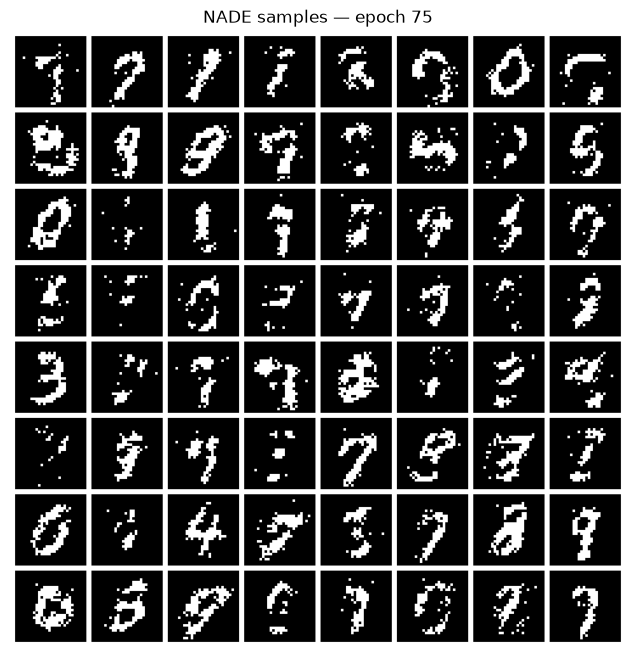

  batch 100: val NLL = 104.0232 (best 104.0232, 0/10) [saved ckpt_0301_nll104.0232.pt]
  batch 200: val NLL = 104.1485 (best 104.0232, 1/10) [saved ckpt_0302_nll104.1485.pt]
  batch 300: val NLL = 104.1240 (best 104.0232, 2/10) [saved ckpt_0303_nll104.1240.pt]
  batch 400: val NLL = 104.0273 (best 104.0232, 3/10) [saved ckpt_0304_nll104.0273.pt]
Epoch 76: train NLL = 103.7611


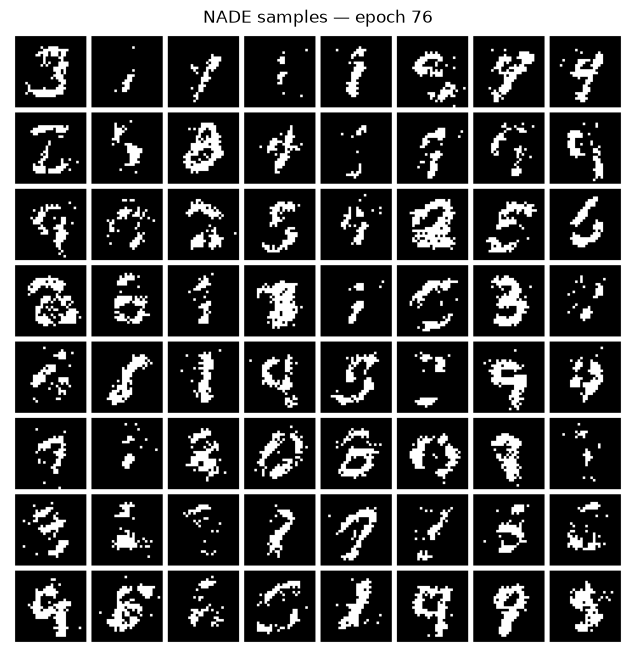

  batch 100: val NLL = 104.1486 (best 104.0232, 4/10) [saved ckpt_0305_nll104.1486.pt]
  batch 200: val NLL = 103.9781 (best 103.9781, 0/10) [saved ckpt_0306_nll103.9781.pt]
  batch 300: val NLL = 103.9901 (best 103.9781, 1/10) [saved ckpt_0307_nll103.9901.pt]
  batch 400: val NLL = 104.0520 (best 103.9781, 2/10) [saved ckpt_0308_nll104.0520.pt]
Epoch 77: train NLL = 103.6184


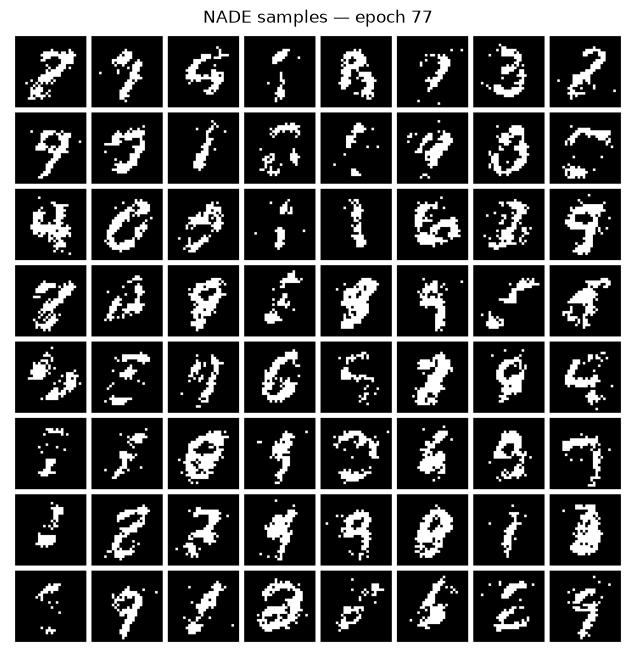

  batch 100: val NLL = 103.8108 (best 103.8108, 0/10) [saved ckpt_0309_nll103.8108.pt]
  batch 200: val NLL = 103.8279 (best 103.8108, 1/10) [saved ckpt_0310_nll103.8279.pt]
  batch 300: val NLL = 103.6875 (best 103.6875, 0/10) [saved ckpt_0311_nll103.6875.pt]
  batch 400: val NLL = 103.8289 (best 103.6875, 1/10) [saved ckpt_0312_nll103.8289.pt]
Epoch 78: train NLL = 103.4603


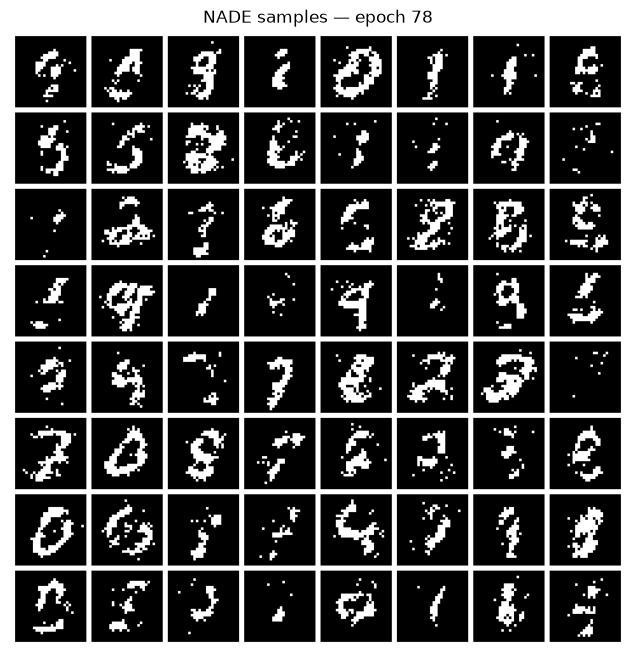

  batch 100: val NLL = 103.7626 (best 103.6875, 2/10) [saved ckpt_0313_nll103.7626.pt]
  batch 200: val NLL = 103.7553 (best 103.6875, 3/10) [saved ckpt_0314_nll103.7553.pt]
  batch 300: val NLL = 103.6695 (best 103.6695, 0/10) [saved ckpt_0315_nll103.6695.pt]
  batch 400: val NLL = 103.5516 (best 103.5516, 0/10) [saved ckpt_0316_nll103.5516.pt]
Epoch 79: train NLL = 103.2636


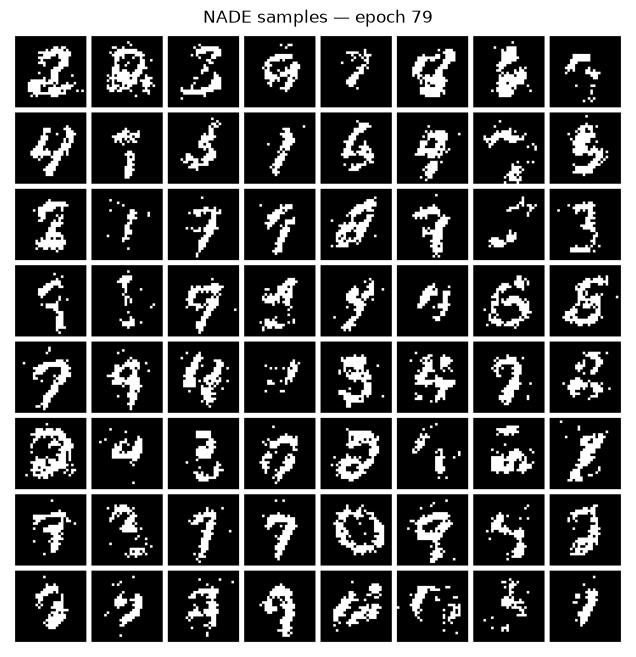

  batch 100: val NLL = 103.4378 (best 103.4378, 0/10) [saved ckpt_0317_nll103.4378.pt]
  batch 200: val NLL = 103.5371 (best 103.4378, 1/10) [saved ckpt_0318_nll103.5371.pt]
  batch 300: val NLL = 103.3921 (best 103.3921, 0/10) [saved ckpt_0319_nll103.3921.pt]
  batch 400: val NLL = 103.4441 (best 103.3921, 1/10) [saved ckpt_0320_nll103.4441.pt]
Epoch 80: train NLL = 103.1225


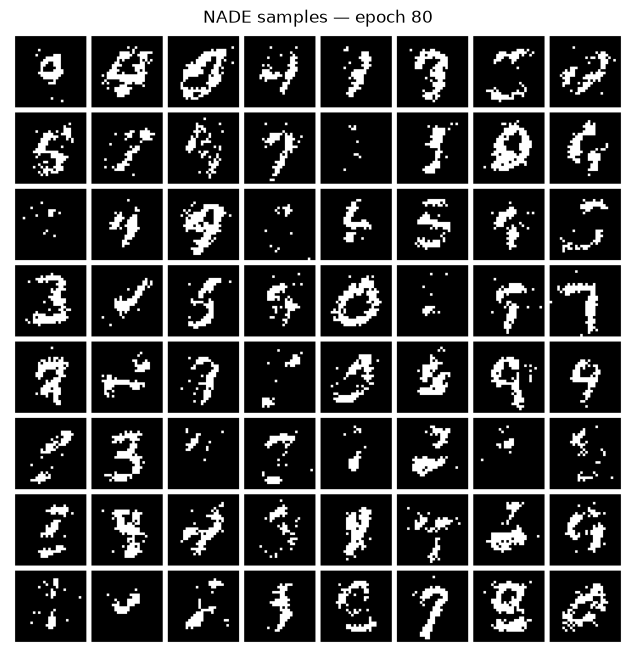

  batch 100: val NLL = 103.3984 (best 103.3921, 2/10) [saved ckpt_0321_nll103.3984.pt]
  batch 200: val NLL = 103.4997 (best 103.3921, 3/10) [saved ckpt_0322_nll103.4997.pt]
  batch 300: val NLL = 103.4515 (best 103.3921, 4/10) [saved ckpt_0323_nll103.4515.pt]
  batch 400: val NLL = 103.3549 (best 103.3549, 0/10) [saved ckpt_0324_nll103.3549.pt]
Epoch 81: train NLL = 103.0128


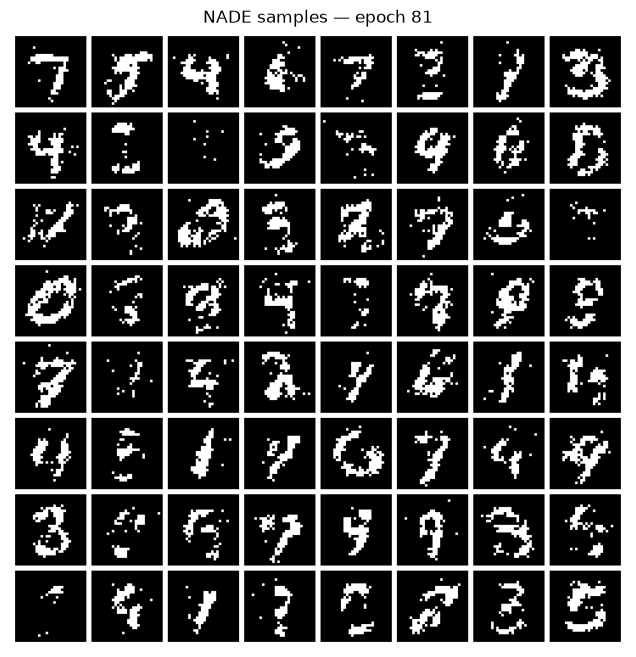

  batch 100: val NLL = 103.2832 (best 103.2832, 0/10) [saved ckpt_0325_nll103.2832.pt]
  batch 200: val NLL = 103.1483 (best 103.1483, 0/10) [saved ckpt_0326_nll103.1483.pt]
  batch 300: val NLL = 103.0823 (best 103.0823, 0/10) [saved ckpt_0327_nll103.0823.pt]
  batch 400: val NLL = 103.1521 (best 103.0823, 1/10) [saved ckpt_0328_nll103.1521.pt]
Epoch 82: train NLL = 102.8003


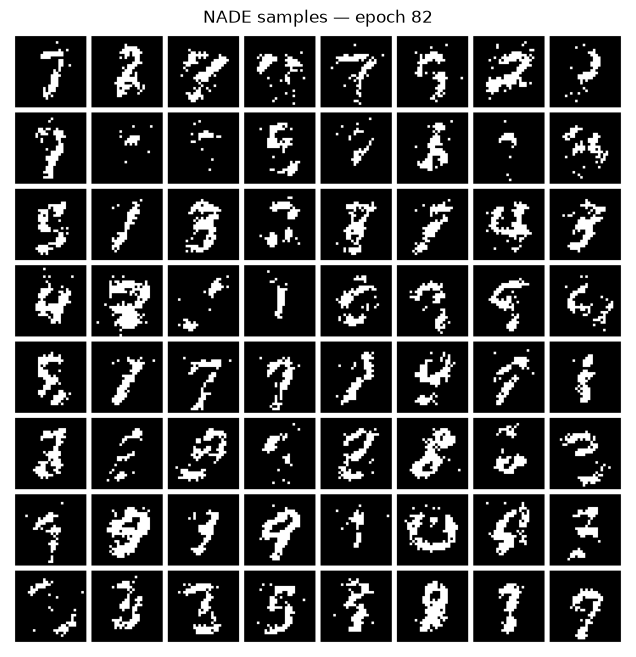

  batch 100: val NLL = 103.1237 (best 103.0823, 2/10) [saved ckpt_0329_nll103.1237.pt]
  batch 200: val NLL = 103.0070 (best 103.0070, 0/10) [saved ckpt_0330_nll103.0070.pt]
  batch 300: val NLL = 103.1263 (best 103.0070, 1/10) [saved ckpt_0331_nll103.1263.pt]
  batch 400: val NLL = 102.9626 (best 102.9626, 0/10) [saved ckpt_0332_nll102.9626.pt]
Epoch 83: train NLL = 102.7033


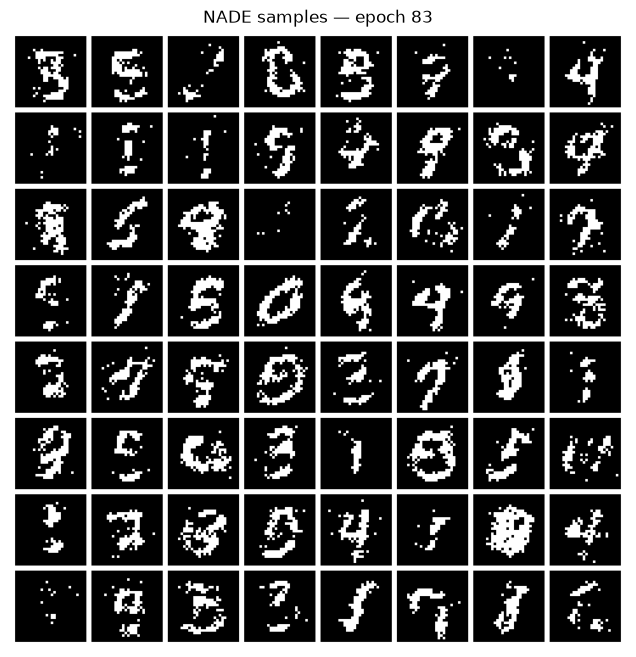

  batch 100: val NLL = 102.9669 (best 102.9626, 1/10) [saved ckpt_0333_nll102.9669.pt]
  batch 200: val NLL = 102.9152 (best 102.9152, 0/10) [saved ckpt_0334_nll102.9152.pt]
  batch 300: val NLL = 102.8072 (best 102.8072, 0/10) [saved ckpt_0335_nll102.8072.pt]
  batch 400: val NLL = 103.0264 (best 102.8072, 1/10) [saved ckpt_0336_nll103.0264.pt]
Epoch 84: train NLL = 102.5614


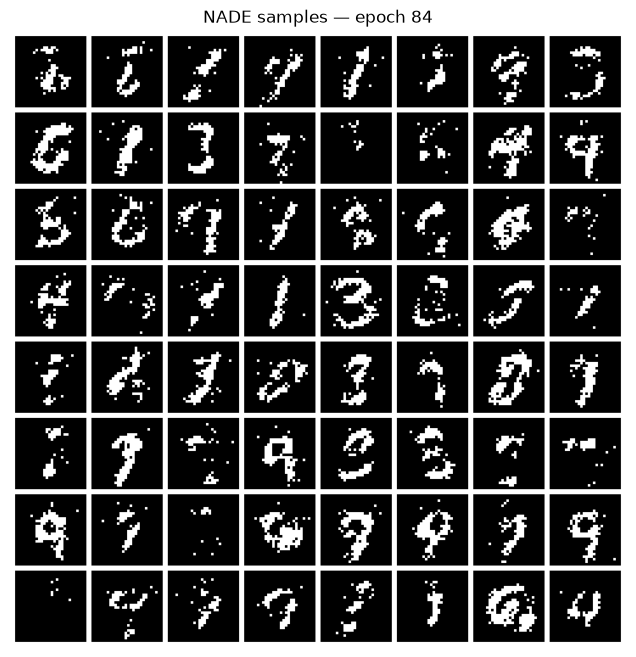

  batch 100: val NLL = 102.7438 (best 102.7438, 0/10) [saved ckpt_0337_nll102.7438.pt]
  batch 200: val NLL = 102.9002 (best 102.7438, 1/10) [saved ckpt_0338_nll102.9002.pt]
  batch 300: val NLL = 102.7099 (best 102.7099, 0/10) [saved ckpt_0339_nll102.7099.pt]
  batch 400: val NLL = 102.7919 (best 102.7099, 1/10) [saved ckpt_0340_nll102.7919.pt]
Epoch 85: train NLL = 102.3883


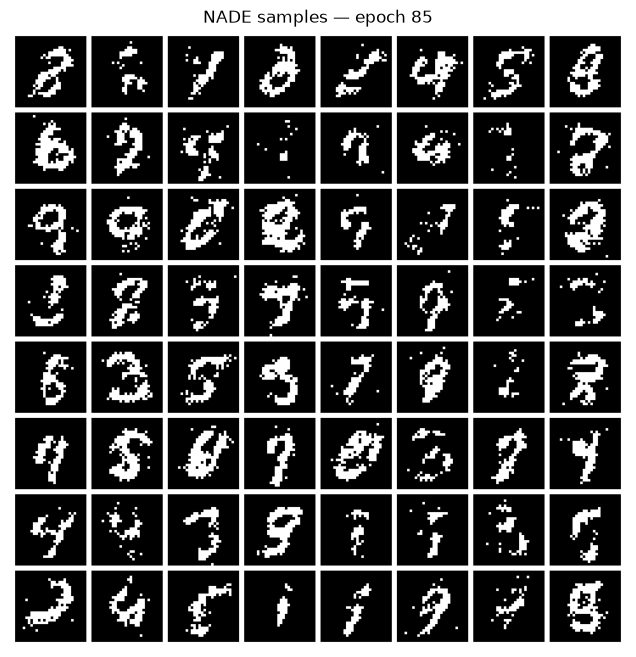

  batch 100: val NLL = 102.6445 (best 102.6445, 0/10) [saved ckpt_0341_nll102.6445.pt]
  batch 200: val NLL = 102.6342 (best 102.6342, 0/10) [saved ckpt_0342_nll102.6342.pt]
  batch 300: val NLL = 102.6842 (best 102.6342, 1/10) [saved ckpt_0343_nll102.6842.pt]
  batch 400: val NLL = 102.5909 (best 102.5909, 0/10) [saved ckpt_0344_nll102.5909.pt]
Epoch 86: train NLL = 102.2289


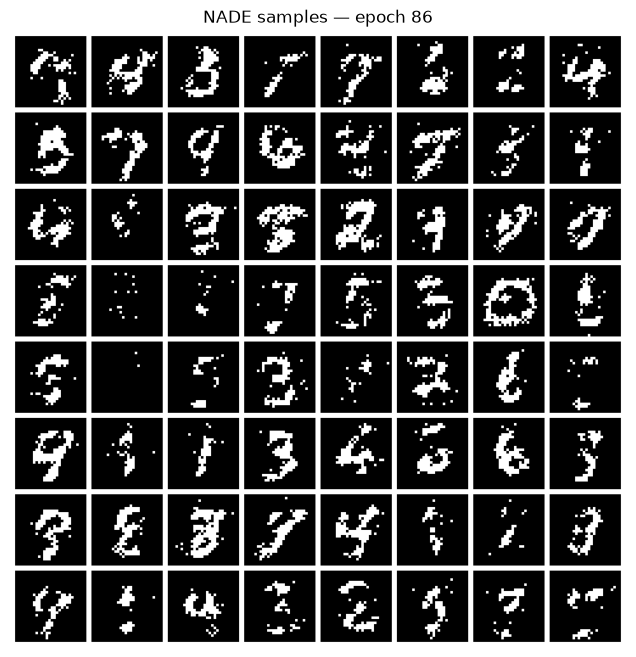

  batch 100: val NLL = 102.4622 (best 102.4622, 0/10) [saved ckpt_0345_nll102.4622.pt]
  batch 200: val NLL = 102.4566 (best 102.4566, 0/10) [saved ckpt_0346_nll102.4566.pt]
  batch 300: val NLL = 102.3646 (best 102.3646, 0/10) [saved ckpt_0347_nll102.3646.pt]
  batch 400: val NLL = 102.4544 (best 102.3646, 1/10) [saved ckpt_0348_nll102.4544.pt]
Epoch 87: train NLL = 102.0832


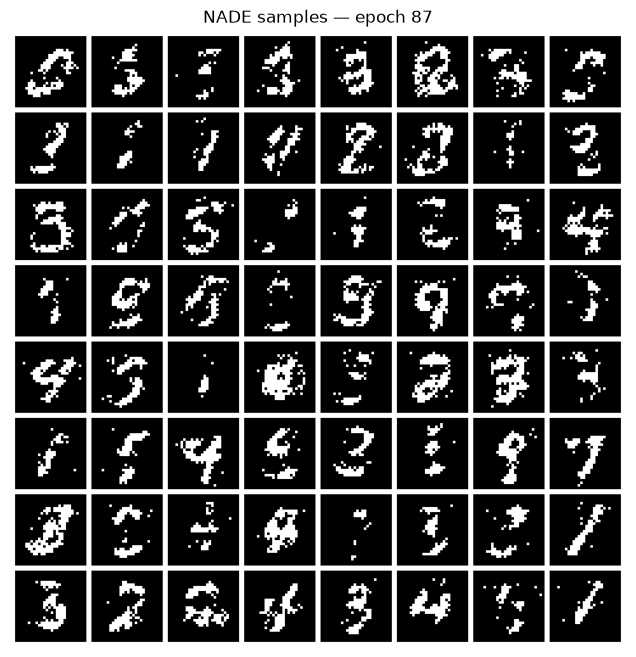

  batch 100: val NLL = 102.4384 (best 102.3646, 2/10) [saved ckpt_0349_nll102.4384.pt]
  batch 200: val NLL = 102.3060 (best 102.3060, 0/10) [saved ckpt_0350_nll102.3060.pt]
  batch 300: val NLL = 102.2041 (best 102.2041, 0/10) [saved ckpt_0351_nll102.2041.pt]
  batch 400: val NLL = 102.1894 (best 102.1894, 0/10) [saved ckpt_0352_nll102.1894.pt]
Epoch 88: train NLL = 101.9648


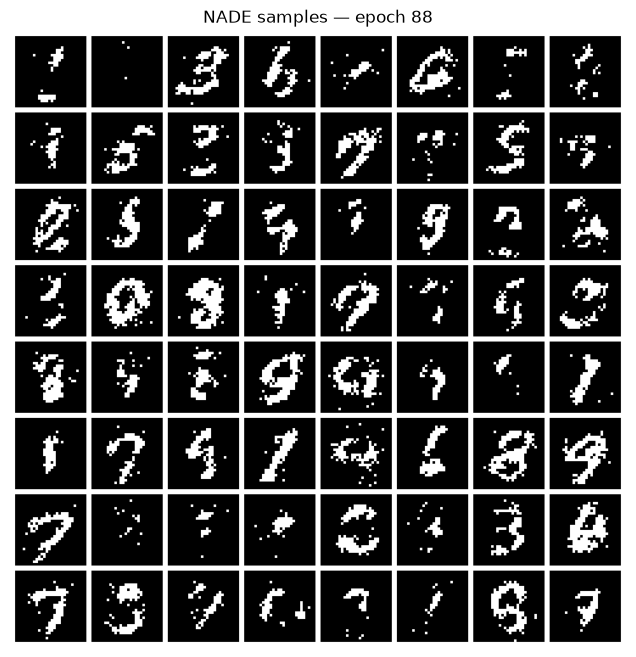

  batch 100: val NLL = 102.3884 (best 102.1894, 1/10) [saved ckpt_0353_nll102.3884.pt]
  batch 200: val NLL = 102.1866 (best 102.1866, 0/10) [saved ckpt_0354_nll102.1866.pt]
  batch 300: val NLL = 102.2474 (best 102.1866, 1/10) [saved ckpt_0355_nll102.2474.pt]
  batch 400: val NLL = 102.2144 (best 102.1866, 2/10) [saved ckpt_0356_nll102.2144.pt]
Epoch 89: train NLL = 101.8493


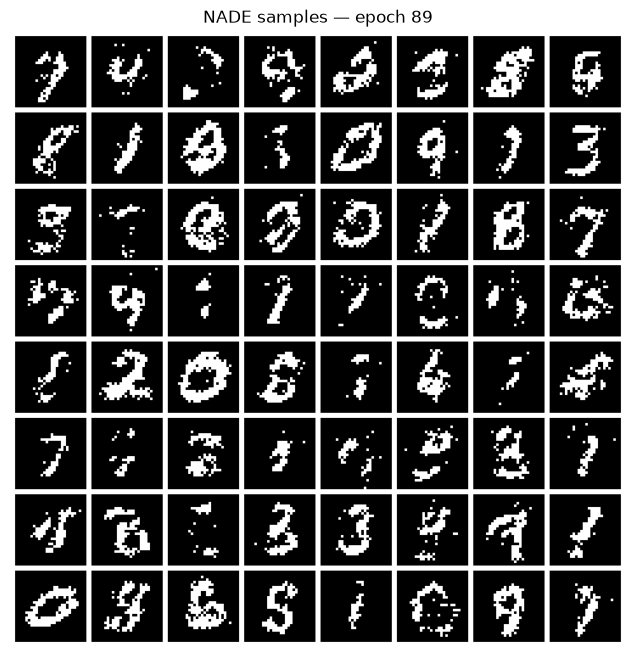

  batch 100: val NLL = 102.2424 (best 102.1866, 3/10) [saved ckpt_0357_nll102.2424.pt]
  batch 200: val NLL = 102.1519 (best 102.1519, 0/10) [saved ckpt_0358_nll102.1519.pt]
  batch 300: val NLL = 102.2003 (best 102.1519, 1/10) [saved ckpt_0359_nll102.2003.pt]
  batch 400: val NLL = 101.9382 (best 101.9382, 0/10) [saved ckpt_0360_nll101.9382.pt]
Epoch 90: train NLL = 101.6861


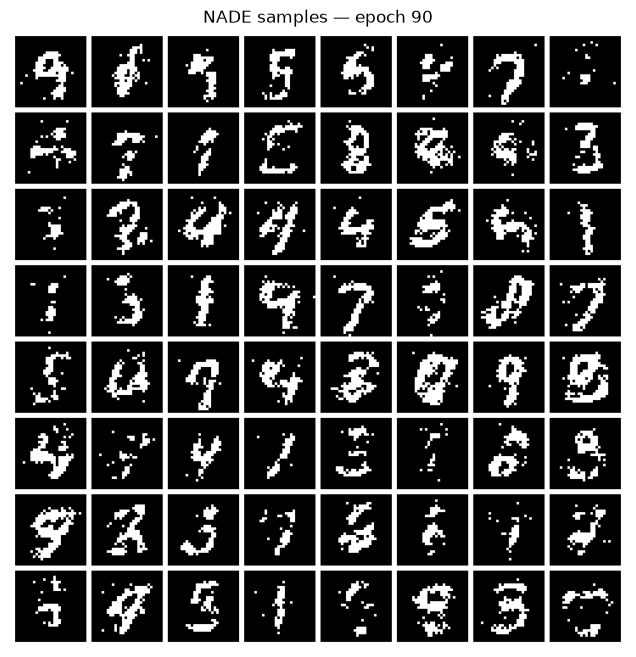

  batch 100: val NLL = 102.1006 (best 101.9382, 1/10) [saved ckpt_0361_nll102.1006.pt]
  batch 200: val NLL = 102.0806 (best 101.9382, 2/10) [saved ckpt_0362_nll102.0806.pt]
  batch 300: val NLL = 101.9403 (best 101.9382, 3/10) [saved ckpt_0363_nll101.9403.pt]
  batch 400: val NLL = 101.9657 (best 101.9382, 4/10) [saved ckpt_0364_nll101.9657.pt]
Epoch 91: train NLL = 101.5795


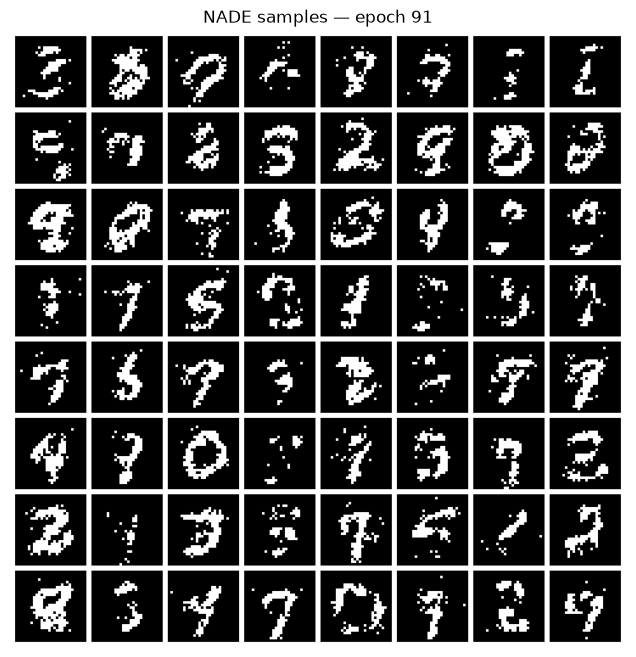

  batch 100: val NLL = 101.9153 (best 101.9153, 0/10) [saved ckpt_0365_nll101.9153.pt]
  batch 200: val NLL = 101.8313 (best 101.8313, 0/10) [saved ckpt_0366_nll101.8313.pt]
  batch 300: val NLL = 101.6334 (best 101.6334, 0/10) [saved ckpt_0367_nll101.6334.pt]
  batch 400: val NLL = 101.8679 (best 101.6334, 1/10) [saved ckpt_0368_nll101.8679.pt]
Epoch 92: train NLL = 101.4169


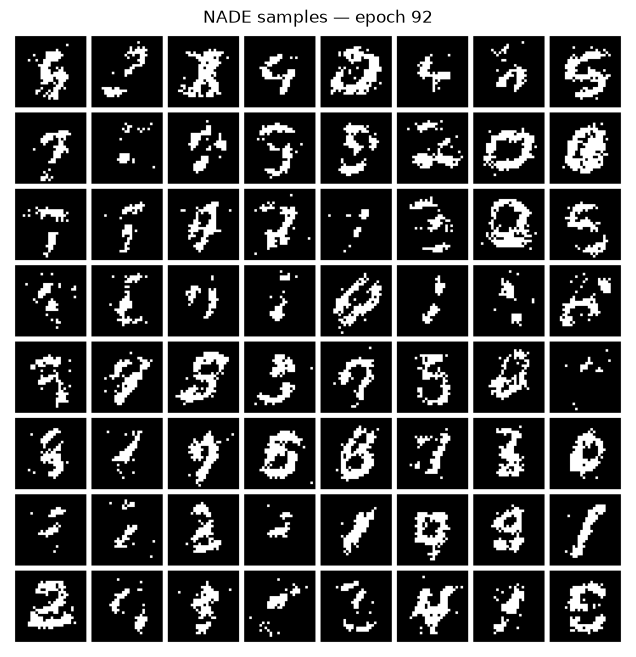

  batch 100: val NLL = 101.8278 (best 101.6334, 2/10) [saved ckpt_0369_nll101.8278.pt]
  batch 200: val NLL = 101.8719 (best 101.6334, 3/10) [saved ckpt_0370_nll101.8719.pt]
  batch 300: val NLL = 101.6856 (best 101.6334, 4/10) [saved ckpt_0371_nll101.6856.pt]
  batch 400: val NLL = 101.6700 (best 101.6334, 5/10) [saved ckpt_0372_nll101.6700.pt]
Epoch 93: train NLL = 101.3586


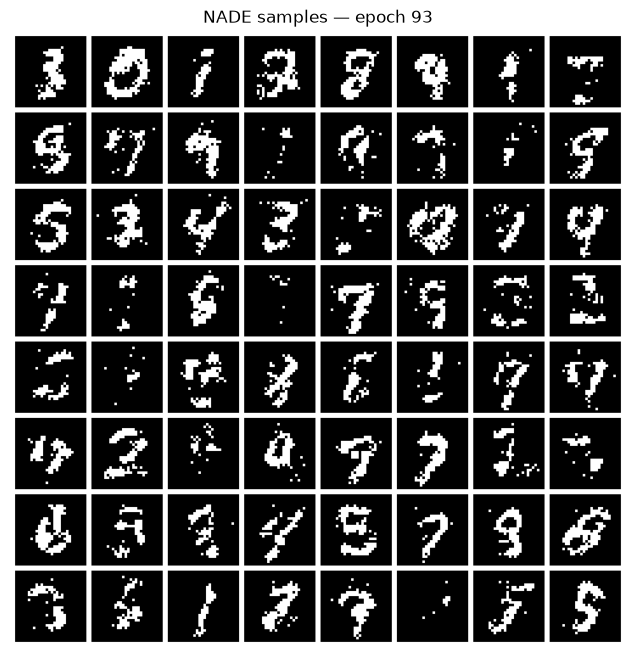

  batch 100: val NLL = 101.6298 (best 101.6298, 0/10) [saved ckpt_0373_nll101.6298.pt]
  batch 200: val NLL = 101.5932 (best 101.5932, 0/10) [saved ckpt_0374_nll101.5932.pt]
  batch 300: val NLL = 101.6053 (best 101.5932, 1/10) [saved ckpt_0375_nll101.6053.pt]
  batch 400: val NLL = 101.5567 (best 101.5567, 0/10) [saved ckpt_0376_nll101.5567.pt]
Epoch 94: train NLL = 101.1817


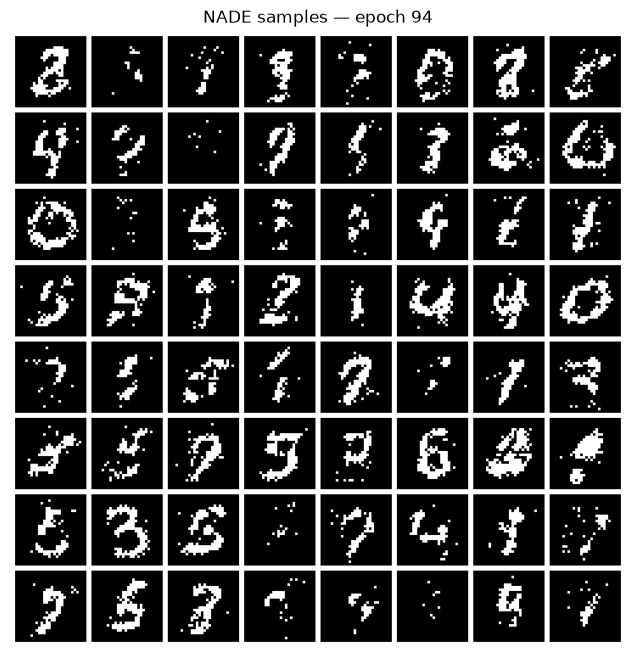

  batch 100: val NLL = 101.6145 (best 101.5567, 1/10) [saved ckpt_0377_nll101.6145.pt]
  batch 200: val NLL = 101.6046 (best 101.5567, 2/10) [saved ckpt_0378_nll101.6046.pt]
  batch 300: val NLL = 101.3517 (best 101.3517, 0/10) [saved ckpt_0379_nll101.3517.pt]
  batch 400: val NLL = 101.4753 (best 101.3517, 1/10) [saved ckpt_0380_nll101.4753.pt]
Epoch 95: train NLL = 101.0803


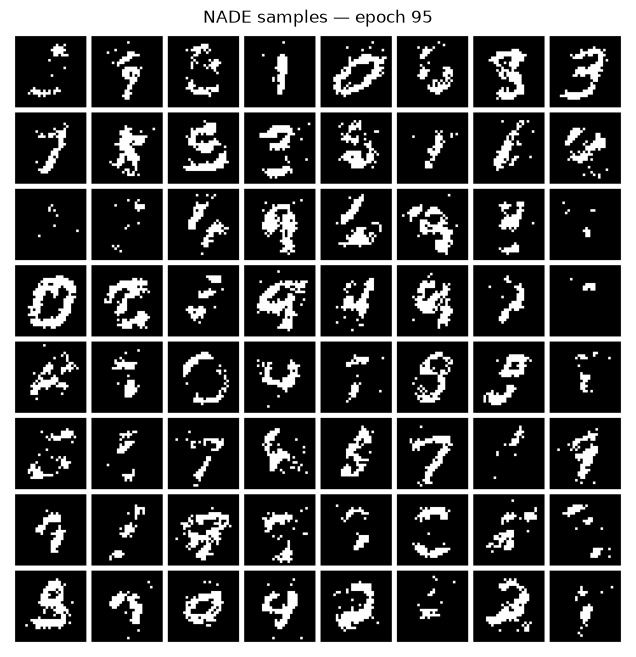

  batch 100: val NLL = 101.4332 (best 101.3517, 2/10) [saved ckpt_0381_nll101.4332.pt]
  batch 200: val NLL = 101.4788 (best 101.3517, 3/10) [saved ckpt_0382_nll101.4788.pt]
  batch 300: val NLL = 101.4200 (best 101.3517, 4/10) [saved ckpt_0383_nll101.4200.pt]
  batch 400: val NLL = 101.3130 (best 101.3130, 0/10) [saved ckpt_0384_nll101.3130.pt]
Epoch 96: train NLL = 100.9356


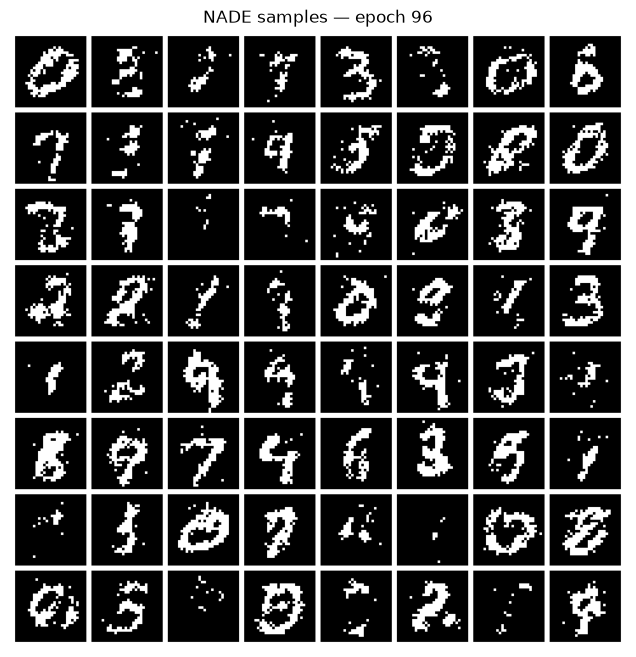

  batch 100: val NLL = 101.4707 (best 101.3130, 1/10) [saved ckpt_0385_nll101.4707.pt]
  batch 200: val NLL = 101.2444 (best 101.2444, 0/10) [saved ckpt_0386_nll101.2444.pt]
  batch 300: val NLL = 101.2875 (best 101.2444, 1/10) [saved ckpt_0387_nll101.2875.pt]
  batch 400: val NLL = 101.0526 (best 101.0526, 0/10) [saved ckpt_0388_nll101.0526.pt]
Epoch 97: train NLL = 100.8514


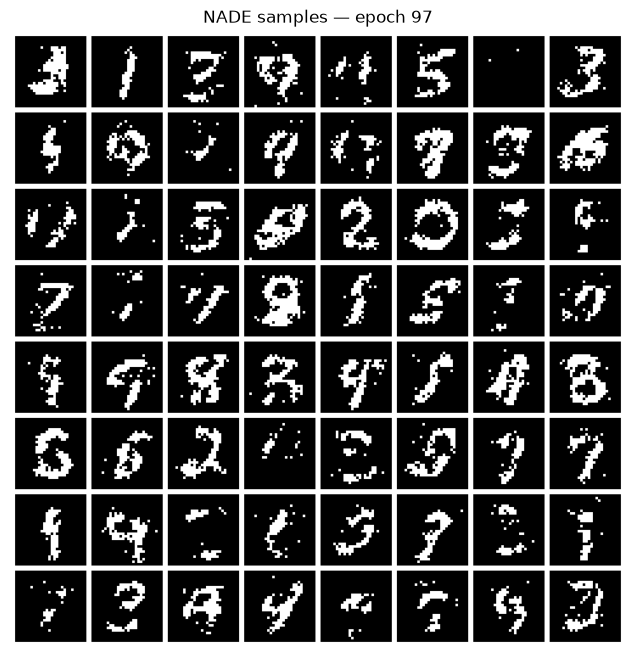

  batch 100: val NLL = 101.0994 (best 101.0526, 1/10) [saved ckpt_0389_nll101.0994.pt]
  batch 200: val NLL = 101.2364 (best 101.0526, 2/10) [saved ckpt_0390_nll101.2364.pt]
  batch 300: val NLL = 101.0949 (best 101.0526, 3/10) [saved ckpt_0391_nll101.0949.pt]
  batch 400: val NLL = 100.9560 (best 100.9560, 0/10) [saved ckpt_0392_nll100.9560.pt]
Epoch 98: train NLL = 100.7401


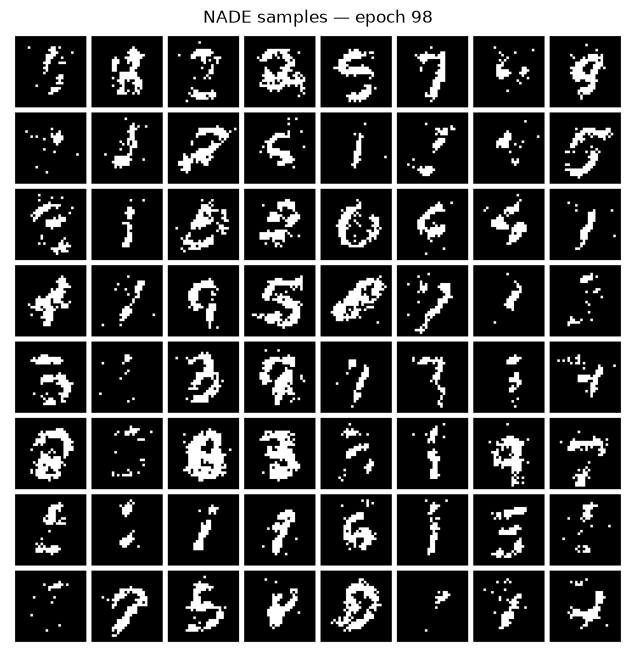

  batch 100: val NLL = 101.0600 (best 100.9560, 1/10) [saved ckpt_0393_nll101.0600.pt]
  batch 200: val NLL = 101.1639 (best 100.9560, 2/10) [saved ckpt_0394_nll101.1639.pt]
  batch 300: val NLL = 101.1372 (best 100.9560, 3/10) [saved ckpt_0395_nll101.1372.pt]
  batch 400: val NLL = 101.0051 (best 100.9560, 4/10) [saved ckpt_0396_nll101.0051.pt]
Epoch 99: train NLL = 100.6363


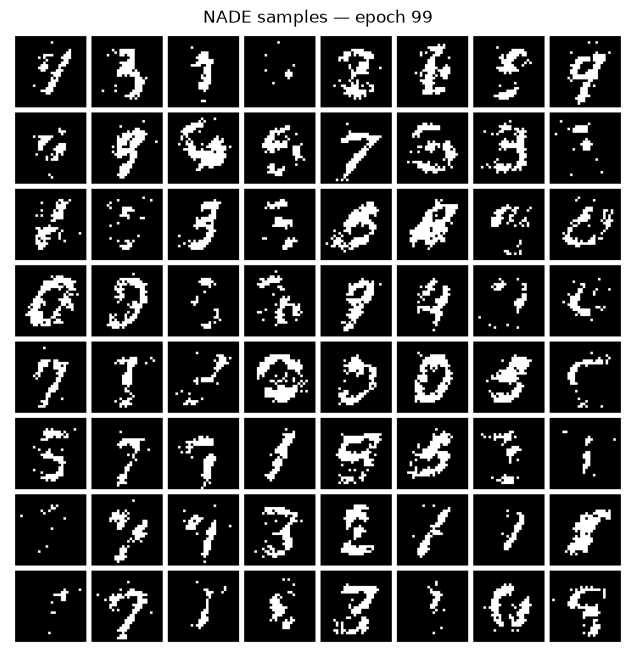

  batch 100: val NLL = 101.0303 (best 100.9560, 5/10) [saved ckpt_0397_nll101.0303.pt]
  batch 200: val NLL = 100.9635 (best 100.9560, 6/10) [saved ckpt_0398_nll100.9635.pt]
  batch 300: val NLL = 100.9872 (best 100.9560, 7/10) [saved ckpt_0399_nll100.9872.pt]
  batch 400: val NLL = 100.7883 (best 100.7883, 0/10) [saved ckpt_0400_nll100.7883.pt]
Epoch 100: train NLL = 100.5166


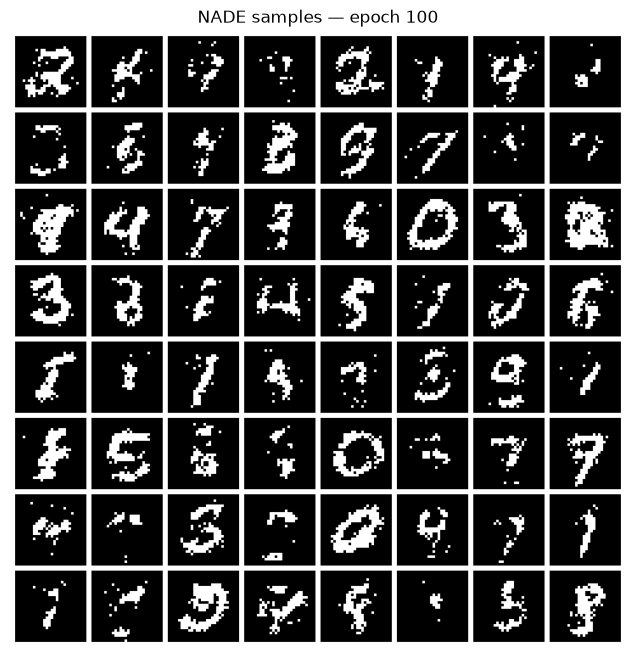

  batch 100: val NLL = 100.9547 (best 100.7883, 1/10) [saved ckpt_0401_nll100.9547.pt]
  batch 200: val NLL = 100.9745 (best 100.7883, 2/10) [saved ckpt_0402_nll100.9745.pt]
  batch 300: val NLL = 100.8675 (best 100.7883, 3/10) [saved ckpt_0403_nll100.8675.pt]
  batch 400: val NLL = 100.8149 (best 100.7883, 4/10) [saved ckpt_0404_nll100.8149.pt]
Epoch 101: train NLL = 100.3685


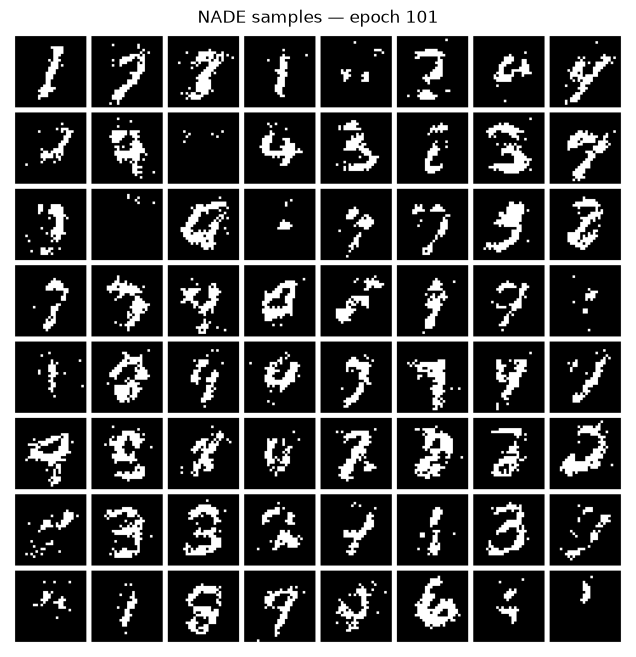

  batch 100: val NLL = 100.7461 (best 100.7461, 0/10) [saved ckpt_0405_nll100.7461.pt]
  batch 200: val NLL = 100.6551 (best 100.6551, 0/10) [saved ckpt_0406_nll100.6551.pt]
  batch 300: val NLL = 100.6058 (best 100.6058, 0/10) [saved ckpt_0407_nll100.6058.pt]
  batch 400: val NLL = 100.7214 (best 100.6058, 1/10) [saved ckpt_0408_nll100.7214.pt]
Epoch 102: train NLL = 100.3274


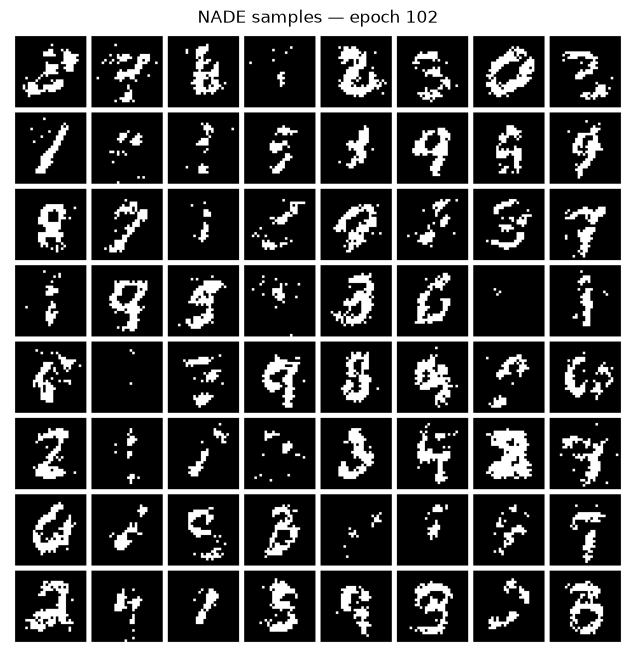

  batch 100: val NLL = 100.5245 (best 100.5245, 0/10) [saved ckpt_0409_nll100.5245.pt]
  batch 200: val NLL = 100.5904 (best 100.5245, 1/10) [saved ckpt_0410_nll100.5904.pt]
  batch 300: val NLL = 100.6300 (best 100.5245, 2/10) [saved ckpt_0411_nll100.6300.pt]
  batch 400: val NLL = 100.6116 (best 100.5245, 3/10) [saved ckpt_0412_nll100.6116.pt]
Epoch 103: train NLL = 100.1856


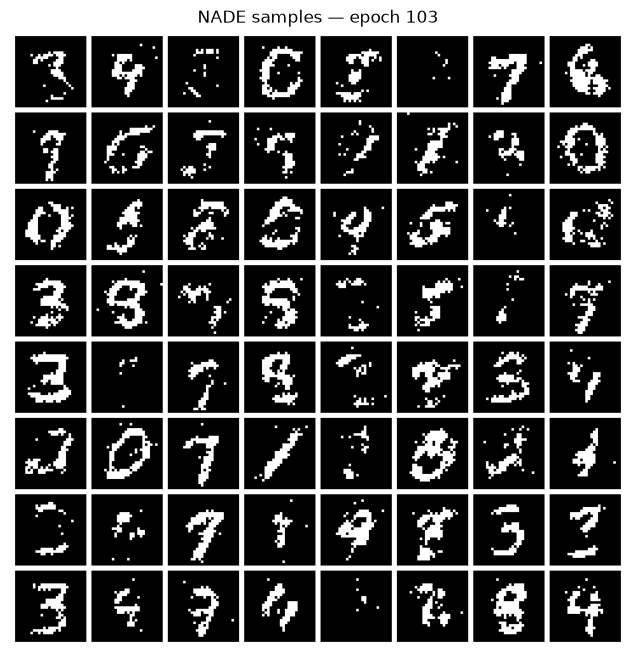

  batch 100: val NLL = 100.4817 (best 100.4817, 0/10) [saved ckpt_0413_nll100.4817.pt]
  batch 200: val NLL = 100.5509 (best 100.4817, 1/10) [saved ckpt_0414_nll100.5509.pt]
  batch 300: val NLL = 100.5280 (best 100.4817, 2/10) [saved ckpt_0415_nll100.5280.pt]
  batch 400: val NLL = 100.4324 (best 100.4324, 0/10) [saved ckpt_0416_nll100.4324.pt]
Epoch 104: train NLL = 100.1296


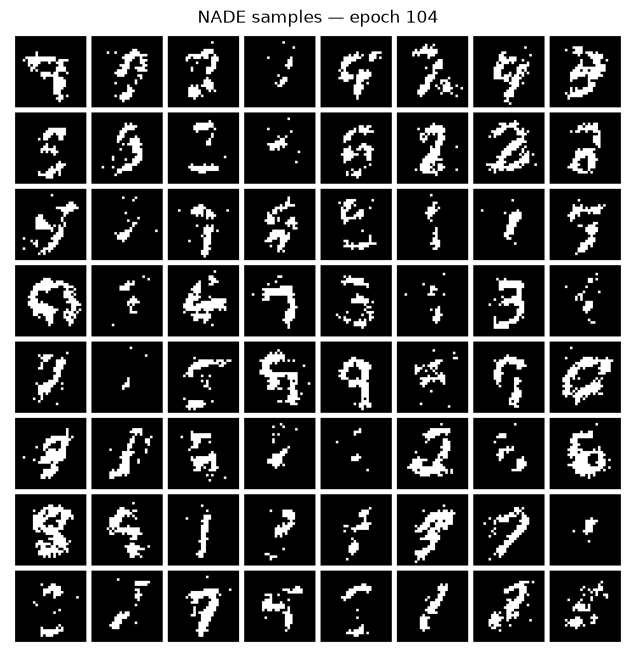

  batch 100: val NLL = 100.3688 (best 100.3688, 0/10) [saved ckpt_0417_nll100.3688.pt]
  batch 200: val NLL = 100.4069 (best 100.3688, 1/10) [saved ckpt_0418_nll100.4069.pt]
  batch 300: val NLL = 100.2859 (best 100.2859, 0/10) [saved ckpt_0419_nll100.2859.pt]
  batch 400: val NLL = 100.4314 (best 100.2859, 1/10) [saved ckpt_0420_nll100.4314.pt]
Epoch 105: train NLL = 99.9984


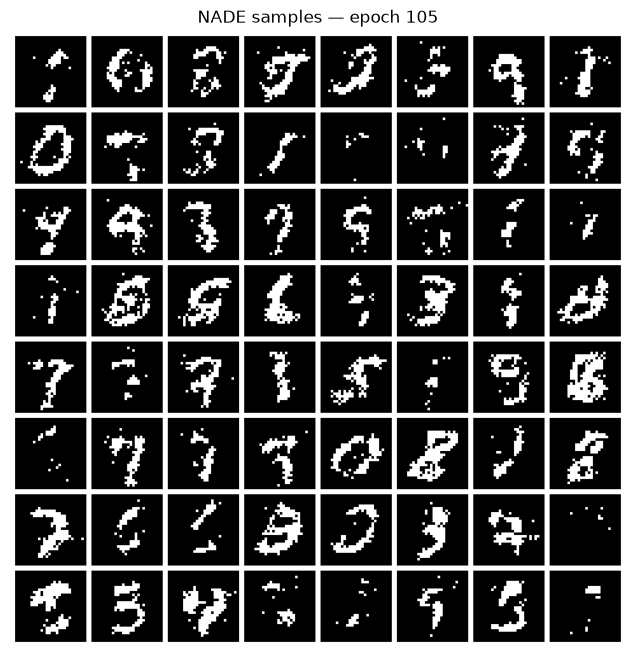

  batch 100: val NLL = 100.4009 (best 100.2859, 2/10) [saved ckpt_0421_nll100.4009.pt]
  batch 200: val NLL = 100.2864 (best 100.2859, 3/10) [saved ckpt_0422_nll100.2864.pt]
  batch 300: val NLL = 100.3709 (best 100.2859, 4/10) [saved ckpt_0423_nll100.3709.pt]
  batch 400: val NLL = 100.4540 (best 100.2859, 5/10) [saved ckpt_0424_nll100.4540.pt]
Epoch 106: train NLL = 99.9309


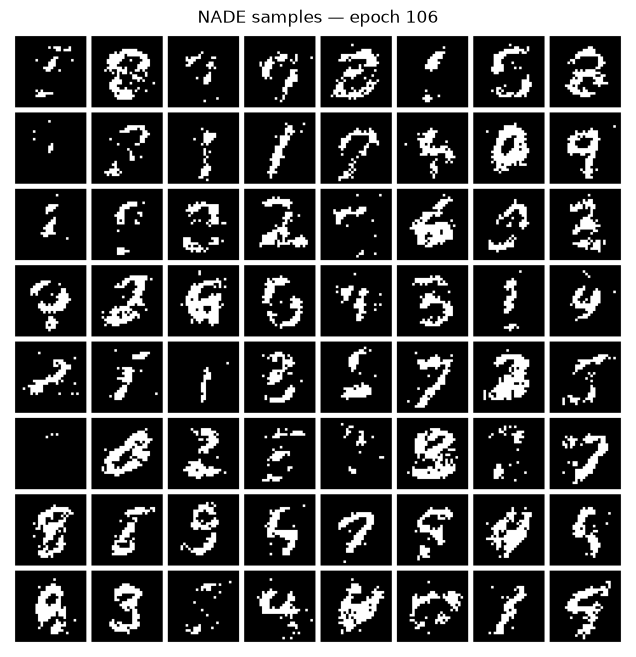

  batch 100: val NLL = 100.2058 (best 100.2058, 0/10) [saved ckpt_0425_nll100.2058.pt]
  batch 200: val NLL = 100.2017 (best 100.2017, 0/10) [saved ckpt_0426_nll100.2017.pt]
  batch 300: val NLL = 100.2422 (best 100.2017, 1/10) [saved ckpt_0427_nll100.2422.pt]
  batch 400: val NLL = 100.3351 (best 100.2017, 2/10) [saved ckpt_0428_nll100.3351.pt]
Epoch 107: train NLL = 99.8160


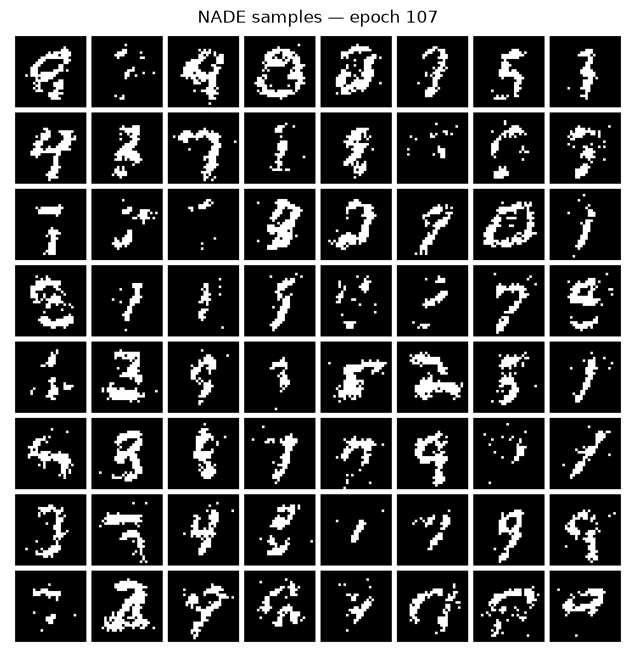

  batch 100: val NLL = 100.1539 (best 100.1539, 0/10) [saved ckpt_0429_nll100.1539.pt]
  batch 200: val NLL = 100.0480 (best 100.0480, 0/10) [saved ckpt_0430_nll100.0480.pt]
  batch 300: val NLL = 100.0890 (best 100.0480, 1/10) [saved ckpt_0431_nll100.0890.pt]
  batch 400: val NLL = 100.1323 (best 100.0480, 2/10) [saved ckpt_0432_nll100.1323.pt]
Epoch 108: train NLL = 99.6940


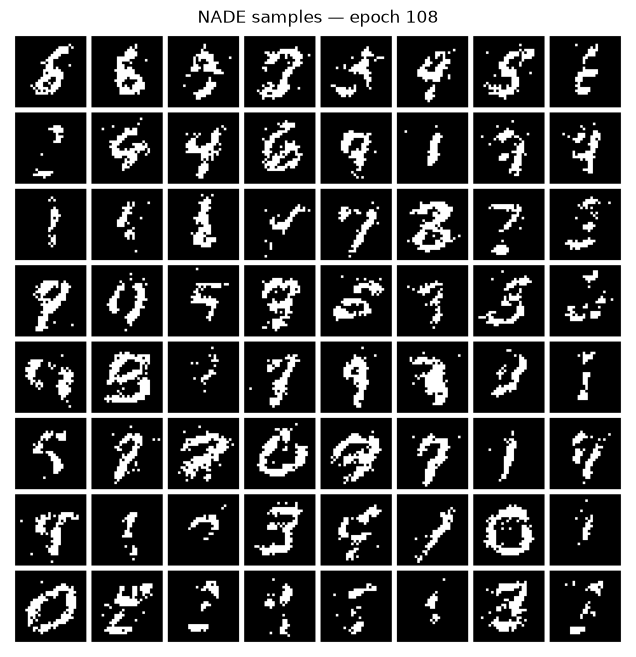

  batch 100: val NLL = 99.8911 (best 99.8911, 0/10) [saved ckpt_0433_nll99.8911.pt]
  batch 200: val NLL = 99.9734 (best 99.8911, 1/10) [saved ckpt_0434_nll99.9734.pt]
  batch 300: val NLL = 99.9201 (best 99.8911, 2/10) [saved ckpt_0435_nll99.9201.pt]
  batch 400: val NLL = 99.8886 (best 99.8886, 0/10) [saved ckpt_0436_nll99.8886.pt]
Epoch 109: train NLL = 99.6763


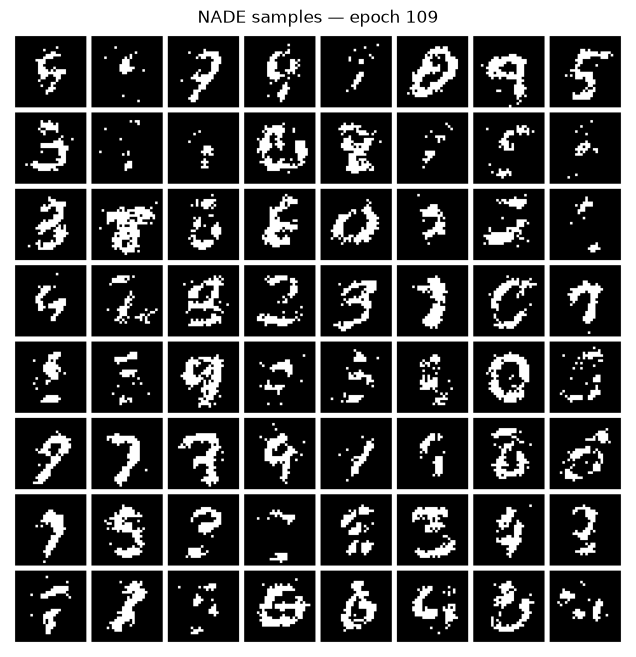

  batch 100: val NLL = 99.9479 (best 99.8886, 1/10) [saved ckpt_0437_nll99.9479.pt]
  batch 200: val NLL = 100.0123 (best 99.8886, 2/10) [saved ckpt_0438_nll100.0123.pt]
  batch 300: val NLL = 99.9762 (best 99.8886, 3/10) [saved ckpt_0439_nll99.9762.pt]
  batch 400: val NLL = 99.8656 (best 99.8656, 0/10) [saved ckpt_0440_nll99.8656.pt]
Epoch 110: train NLL = 99.4817


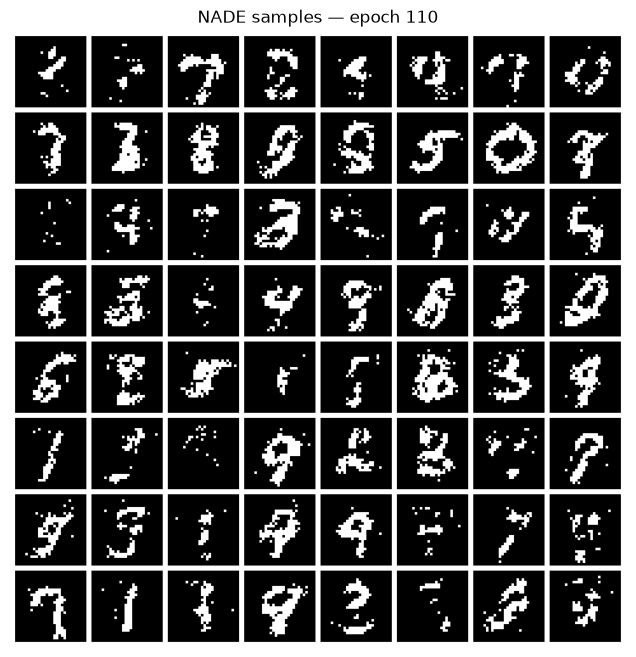

  batch 100: val NLL = 99.8578 (best 99.8578, 0/10) [saved ckpt_0441_nll99.8578.pt]
  batch 200: val NLL = 100.0326 (best 99.8578, 1/10) [saved ckpt_0442_nll100.0326.pt]
  batch 300: val NLL = 99.7988 (best 99.7988, 0/10) [saved ckpt_0443_nll99.7988.pt]
  batch 400: val NLL = 99.8275 (best 99.7988, 1/10) [saved ckpt_0444_nll99.8275.pt]
Epoch 111: train NLL = 99.3875


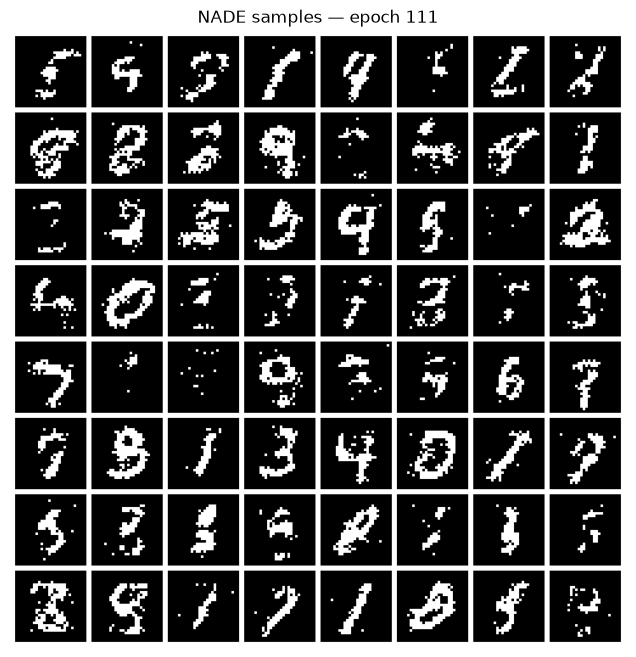

  batch 100: val NLL = 99.8676 (best 99.7988, 2/10) [saved ckpt_0445_nll99.8676.pt]
  batch 200: val NLL = 99.8945 (best 99.7988, 3/10) [saved ckpt_0446_nll99.8945.pt]
  batch 300: val NLL = 99.6198 (best 99.6198, 0/10) [saved ckpt_0447_nll99.6198.pt]
  batch 400: val NLL = 99.6723 (best 99.6198, 1/10) [saved ckpt_0448_nll99.6723.pt]
Epoch 112: train NLL = 99.3246


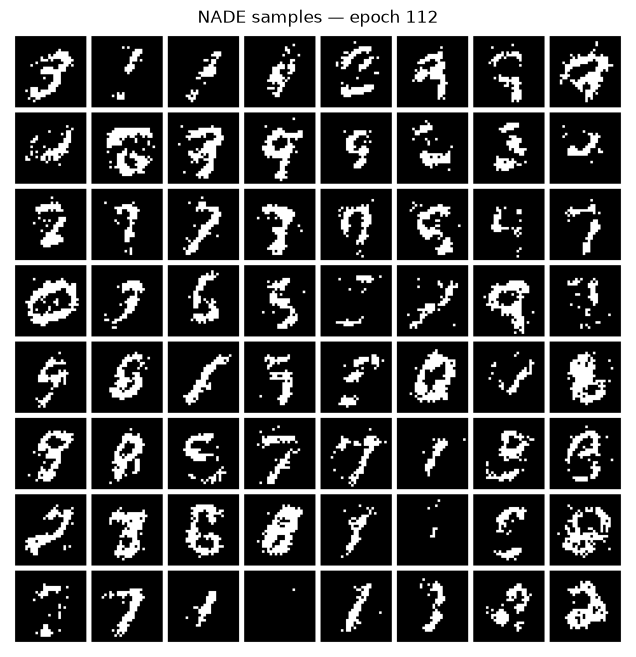

  batch 100: val NLL = 99.8644 (best 99.6198, 2/10) [saved ckpt_0449_nll99.8644.pt]
  batch 200: val NLL = 99.7695 (best 99.6198, 3/10) [saved ckpt_0450_nll99.7695.pt]
  batch 300: val NLL = 99.5854 (best 99.5854, 0/10) [saved ckpt_0451_nll99.5854.pt]
  batch 400: val NLL = 99.6747 (best 99.5854, 1/10) [saved ckpt_0452_nll99.6747.pt]
Epoch 113: train NLL = 99.2245


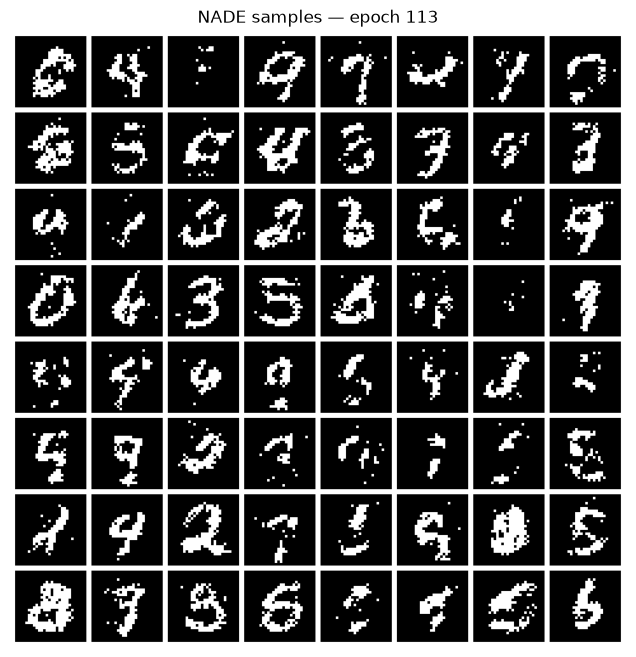

  batch 100: val NLL = 99.5604 (best 99.5604, 0/10) [saved ckpt_0453_nll99.5604.pt]
  batch 200: val NLL = 99.6143 (best 99.5604, 1/10) [saved ckpt_0454_nll99.6143.pt]
  batch 300: val NLL = 99.5754 (best 99.5604, 2/10) [saved ckpt_0455_nll99.5754.pt]
  batch 400: val NLL = 99.5923 (best 99.5604, 3/10) [saved ckpt_0456_nll99.5923.pt]
Epoch 114: train NLL = 99.1336


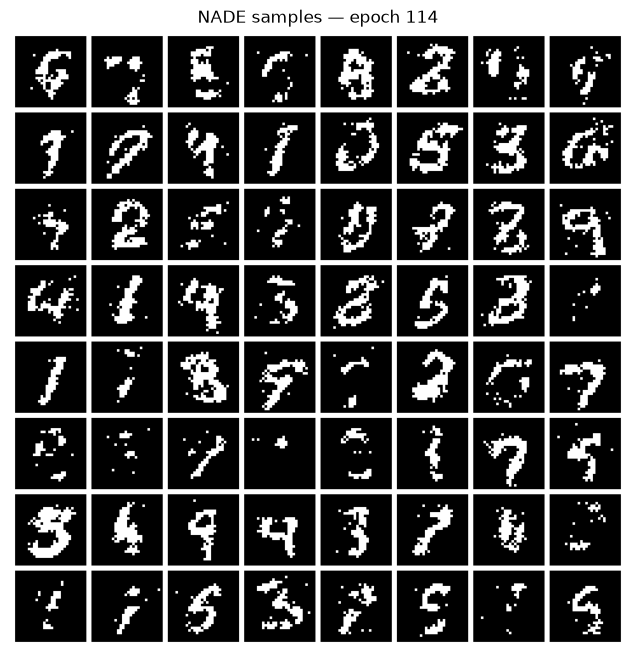

  batch 100: val NLL = 99.4370 (best 99.4370, 0/10) [saved ckpt_0457_nll99.4370.pt]
  batch 200: val NLL = 99.4734 (best 99.4370, 1/10) [saved ckpt_0458_nll99.4734.pt]
  batch 300: val NLL = 99.5009 (best 99.4370, 2/10) [saved ckpt_0459_nll99.5009.pt]
  batch 400: val NLL = 99.4311 (best 99.4311, 0/10) [saved ckpt_0460_nll99.4311.pt]
Epoch 115: train NLL = 99.0666


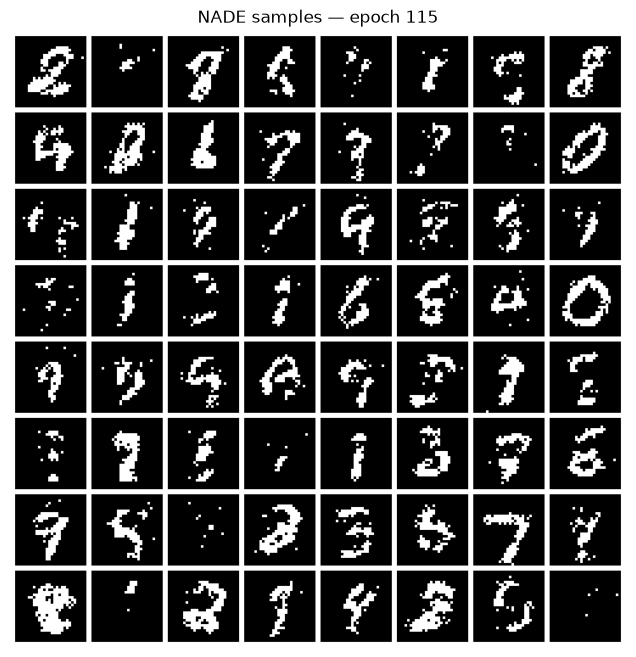

  batch 100: val NLL = 99.5073 (best 99.4311, 1/10) [saved ckpt_0461_nll99.5073.pt]
  batch 200: val NLL = 99.5162 (best 99.4311, 2/10) [saved ckpt_0462_nll99.5162.pt]
  batch 300: val NLL = 99.3942 (best 99.3942, 0/10) [saved ckpt_0463_nll99.3942.pt]
  batch 400: val NLL = 99.3454 (best 99.3454, 0/10) [saved ckpt_0464_nll99.3454.pt]
Epoch 116: train NLL = 98.9685


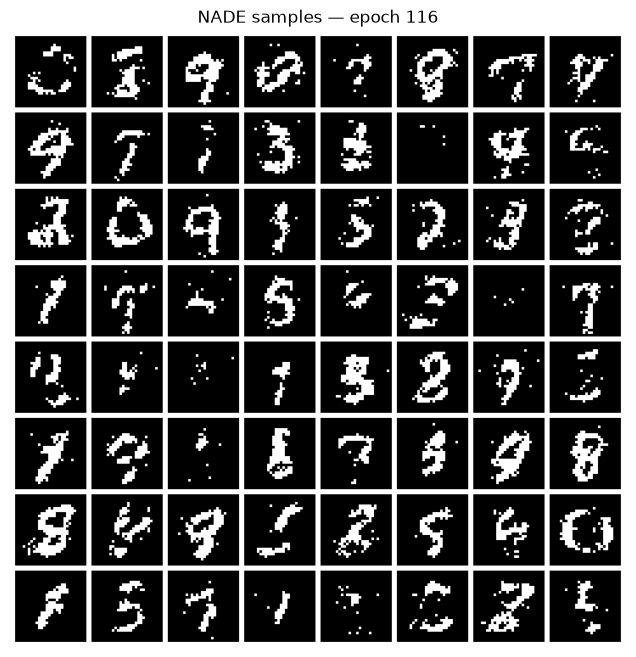

  batch 100: val NLL = 99.4222 (best 99.3454, 1/10) [saved ckpt_0465_nll99.4222.pt]
  batch 200: val NLL = 99.2009 (best 99.2009, 0/10) [saved ckpt_0466_nll99.2009.pt]
  batch 300: val NLL = 99.2928 (best 99.2009, 1/10) [saved ckpt_0467_nll99.2928.pt]
  batch 400: val NLL = 99.4194 (best 99.2009, 2/10) [saved ckpt_0468_nll99.4194.pt]
Epoch 117: train NLL = 98.9016


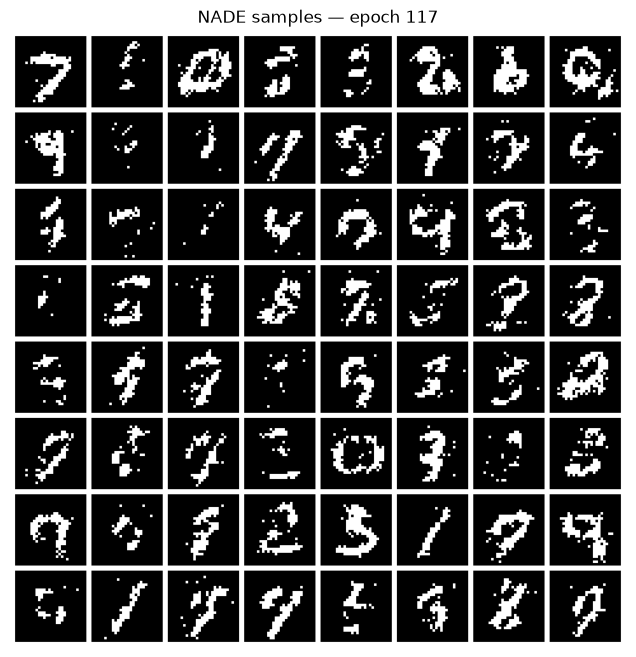

  batch 100: val NLL = 99.3870 (best 99.2009, 3/10) [saved ckpt_0469_nll99.3870.pt]
  batch 200: val NLL = 99.2094 (best 99.2009, 4/10) [saved ckpt_0470_nll99.2094.pt]
  batch 300: val NLL = 99.0913 (best 99.0913, 0/10) [saved ckpt_0471_nll99.0913.pt]
  batch 400: val NLL = 99.2267 (best 99.0913, 1/10) [saved ckpt_0472_nll99.2267.pt]
Epoch 118: train NLL = 98.7728


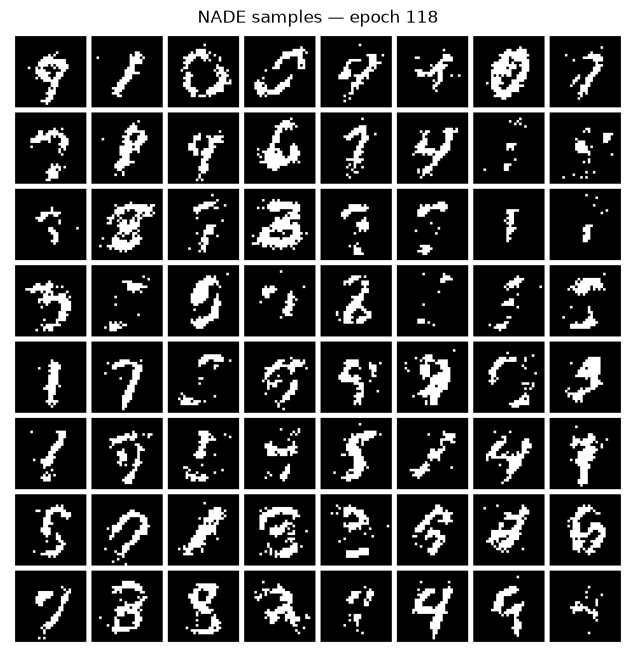

  batch 100: val NLL = 99.0437 (best 99.0437, 0/10) [saved ckpt_0473_nll99.0437.pt]
  batch 200: val NLL = 99.0678 (best 99.0437, 1/10) [saved ckpt_0474_nll99.0678.pt]
  batch 300: val NLL = 99.0562 (best 99.0437, 2/10) [saved ckpt_0475_nll99.0562.pt]
  batch 400: val NLL = 99.2228 (best 99.0437, 3/10) [saved ckpt_0476_nll99.2228.pt]
Epoch 119: train NLL = 98.6984


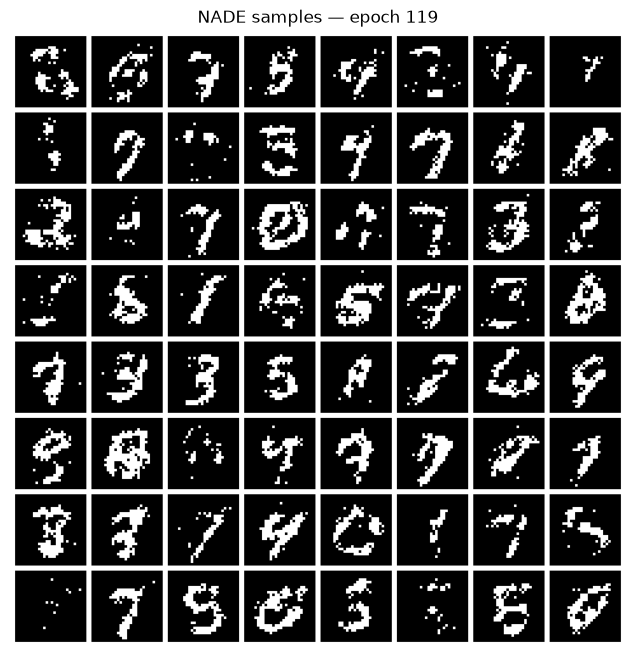

  batch 100: val NLL = 98.9714 (best 98.9714, 0/10) [saved ckpt_0477_nll98.9714.pt]
  batch 200: val NLL = 99.0672 (best 98.9714, 1/10) [saved ckpt_0478_nll99.0672.pt]
  batch 300: val NLL = 99.0887 (best 98.9714, 2/10) [saved ckpt_0479_nll99.0887.pt]
  batch 400: val NLL = 98.9048 (best 98.9048, 0/10) [saved ckpt_0480_nll98.9048.pt]
Epoch 120: train NLL = 98.6372


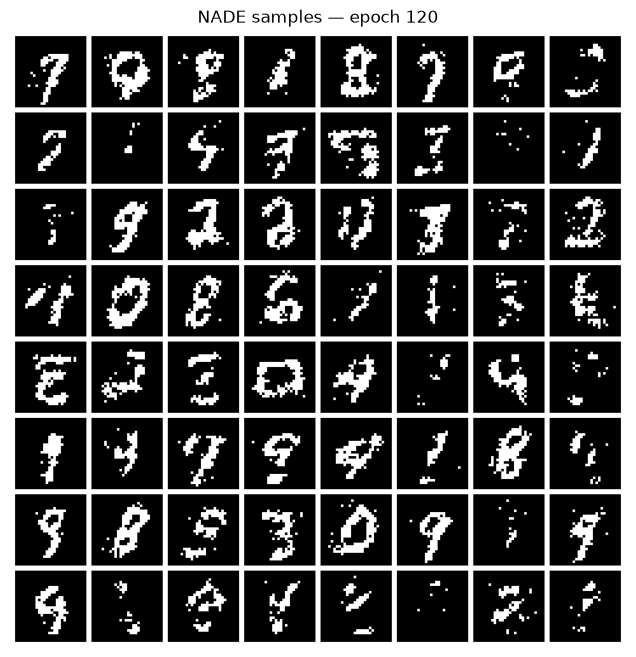

  batch 100: val NLL = 98.8936 (best 98.8936, 0/10) [saved ckpt_0481_nll98.8936.pt]
  batch 200: val NLL = 99.0012 (best 98.8936, 1/10) [saved ckpt_0482_nll99.0012.pt]
  batch 300: val NLL = 98.8948 (best 98.8936, 2/10) [saved ckpt_0483_nll98.8948.pt]
  batch 400: val NLL = 98.9642 (best 98.8936, 3/10) [saved ckpt_0484_nll98.9642.pt]
Epoch 121: train NLL = 98.5283


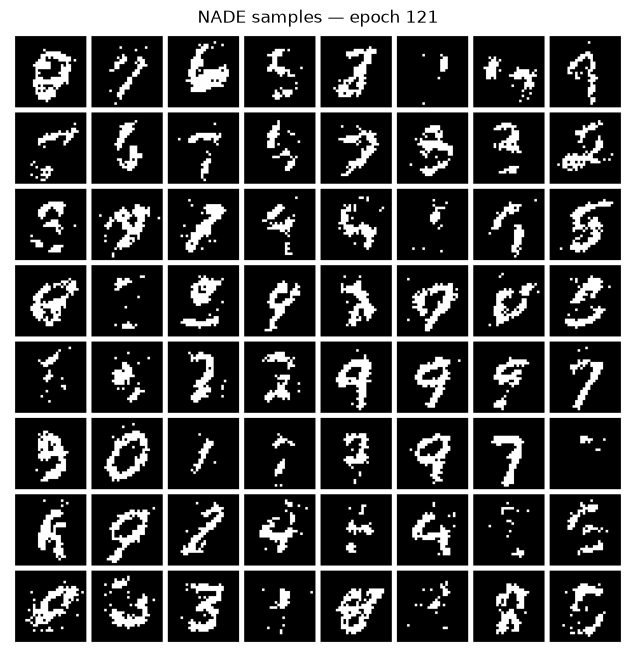

  batch 100: val NLL = 98.9716 (best 98.8936, 4/10) [saved ckpt_0485_nll98.9716.pt]
  batch 200: val NLL = 98.8803 (best 98.8803, 0/10) [saved ckpt_0486_nll98.8803.pt]
  batch 300: val NLL = 99.0815 (best 98.8803, 1/10)
  batch 400: val NLL = 98.9318 (best 98.8803, 2/10) [saved ckpt_0487_nll98.9318.pt]
Epoch 122: train NLL = 98.4526


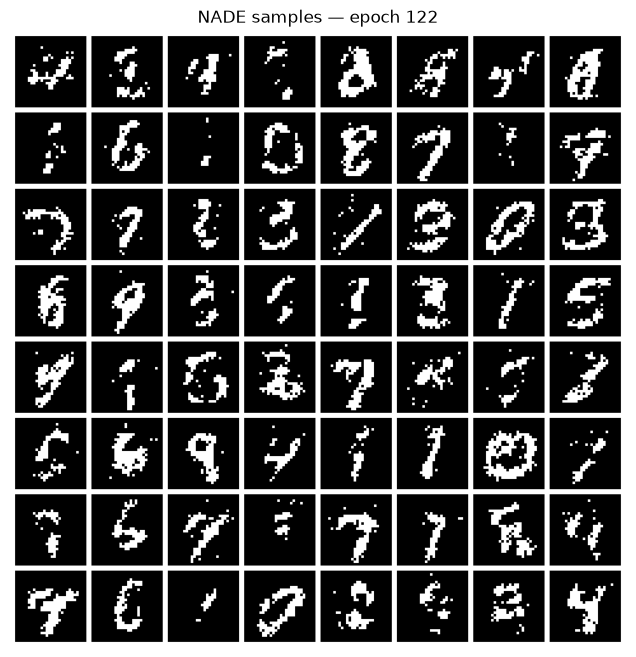

  batch 100: val NLL = 98.7737 (best 98.7737, 0/10) [saved ckpt_0488_nll98.7737.pt]
  batch 200: val NLL = 98.9203 (best 98.7737, 1/10) [saved ckpt_0489_nll98.9203.pt]
  batch 300: val NLL = 98.7998 (best 98.7737, 2/10) [saved ckpt_0490_nll98.7998.pt]
  batch 400: val NLL = 98.9368 (best 98.7737, 3/10) [saved ckpt_0491_nll98.9368.pt]
Epoch 123: train NLL = 98.3917


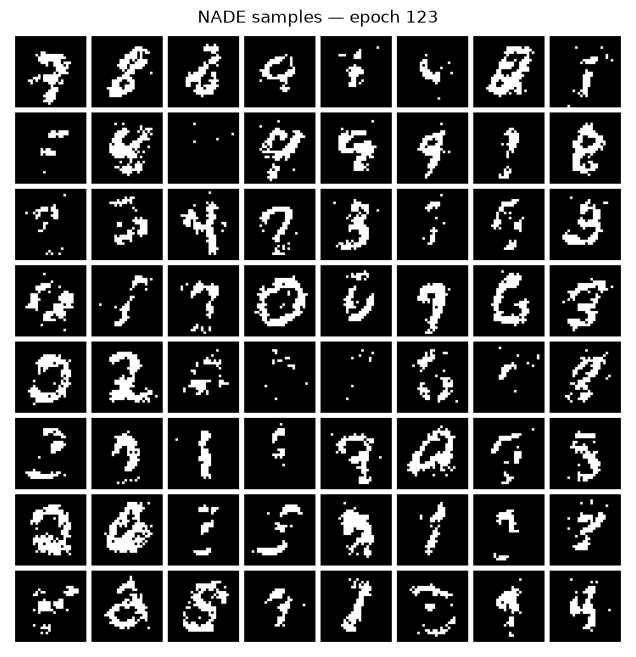

  batch 100: val NLL = 98.7640 (best 98.7640, 0/10) [saved ckpt_0492_nll98.7640.pt]
  batch 200: val NLL = 98.7141 (best 98.7141, 0/10) [saved ckpt_0493_nll98.7141.pt]
  batch 300: val NLL = 98.7189 (best 98.7141, 1/10) [saved ckpt_0494_nll98.7189.pt]
  batch 400: val NLL = 98.8072 (best 98.7141, 2/10) [saved ckpt_0495_nll98.8072.pt]
Epoch 124: train NLL = 98.3226


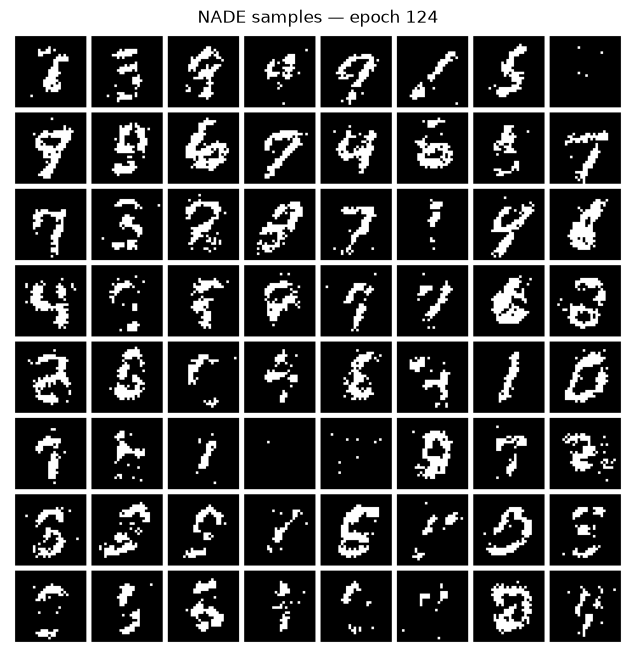

  batch 100: val NLL = 98.7498 (best 98.7141, 3/10) [saved ckpt_0496_nll98.7498.pt]
  batch 200: val NLL = 98.7128 (best 98.7128, 0/10) [saved ckpt_0497_nll98.7128.pt]
  batch 300: val NLL = 98.7899 (best 98.7128, 1/10) [saved ckpt_0498_nll98.7899.pt]
  batch 400: val NLL = 98.5023 (best 98.5023, 0/10) [saved ckpt_0499_nll98.5023.pt]
Epoch 125: train NLL = 98.1981


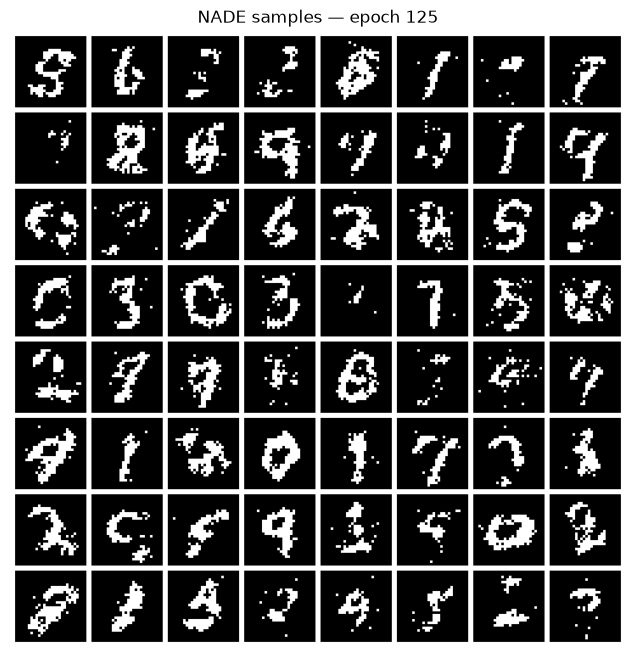

  batch 100: val NLL = 98.6139 (best 98.5023, 1/10) [saved ckpt_0500_nll98.6139.pt]
  batch 200: val NLL = 98.5478 (best 98.5023, 2/10) [saved ckpt_0501_nll98.5478.pt]
  batch 300: val NLL = 98.6119 (best 98.5023, 3/10) [saved ckpt_0502_nll98.6119.pt]
  batch 400: val NLL = 98.6361 (best 98.5023, 4/10) [saved ckpt_0503_nll98.6361.pt]
Epoch 126: train NLL = 98.1376


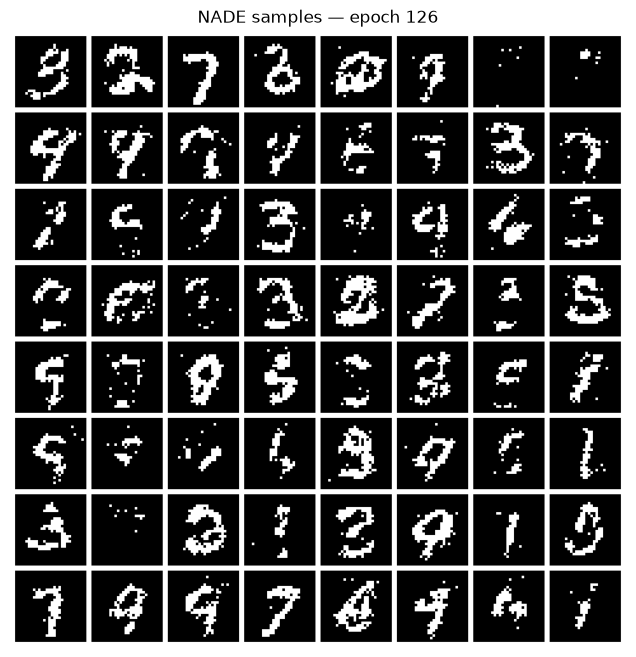

  batch 100: val NLL = 98.6851 (best 98.5023, 5/10) [saved ckpt_0504_nll98.6851.pt]
  batch 200: val NLL = 98.5369 (best 98.5023, 6/10) [saved ckpt_0505_nll98.5369.pt]
  batch 300: val NLL = 98.3336 (best 98.3336, 0/10) [saved ckpt_0506_nll98.3336.pt]
  batch 400: val NLL = 98.6345 (best 98.3336, 1/10) [saved ckpt_0507_nll98.6345.pt]
Epoch 127: train NLL = 98.0916


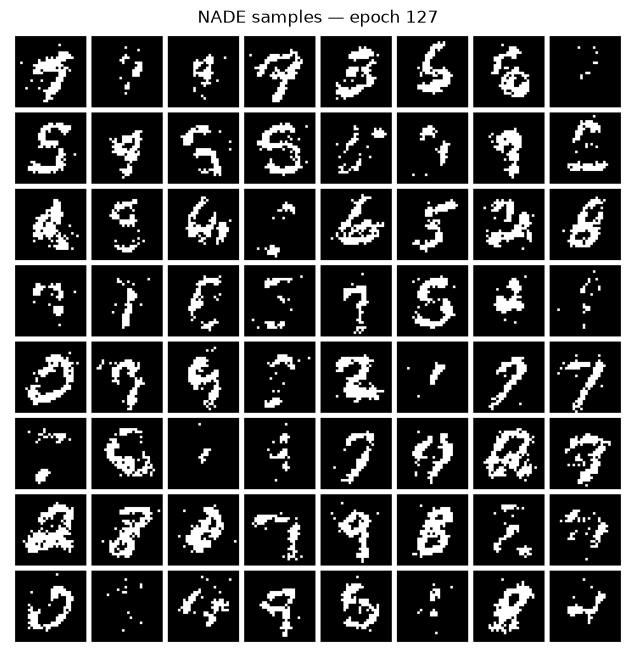

  batch 100: val NLL = 98.3220 (best 98.3220, 0/10) [saved ckpt_0508_nll98.3220.pt]
  batch 200: val NLL = 98.4853 (best 98.3220, 1/10) [saved ckpt_0509_nll98.4853.pt]
  batch 300: val NLL = 98.4418 (best 98.3220, 2/10) [saved ckpt_0510_nll98.4418.pt]
  batch 400: val NLL = 98.3808 (best 98.3220, 3/10) [saved ckpt_0511_nll98.3808.pt]
Epoch 128: train NLL = 97.9735


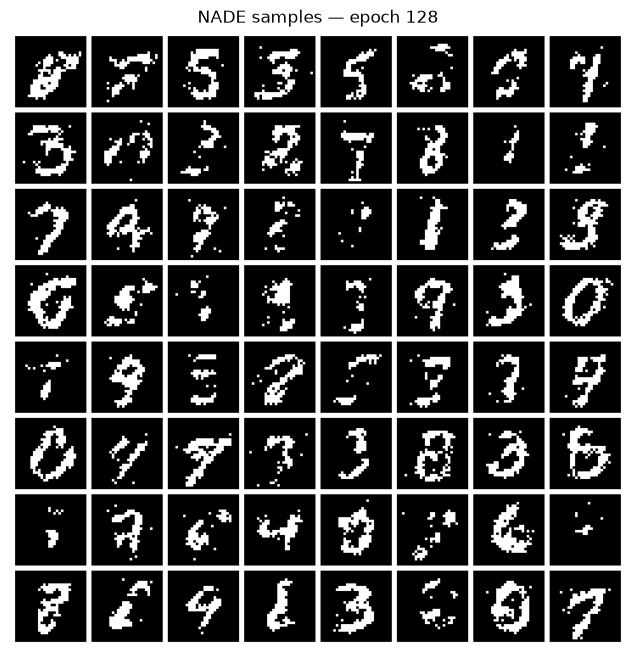

  batch 100: val NLL = 98.3878 (best 98.3220, 4/10) [saved ckpt_0512_nll98.3878.pt]
  batch 200: val NLL = 98.3675 (best 98.3220, 5/10) [saved ckpt_0513_nll98.3675.pt]
  batch 300: val NLL = 98.4597 (best 98.3220, 6/10) [saved ckpt_0514_nll98.4597.pt]
  batch 400: val NLL = 98.4768 (best 98.3220, 7/10) [saved ckpt_0515_nll98.4768.pt]
Epoch 129: train NLL = 97.9142


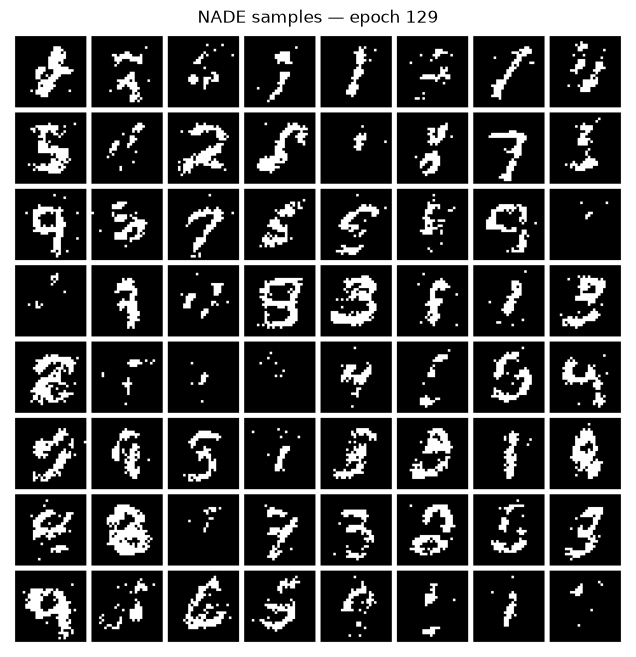

  batch 100: val NLL = 98.2572 (best 98.2572, 0/10) [saved ckpt_0516_nll98.2572.pt]
  batch 200: val NLL = 98.2086 (best 98.2086, 0/10) [saved ckpt_0517_nll98.2086.pt]
  batch 300: val NLL = 98.3081 (best 98.2086, 1/10) [saved ckpt_0518_nll98.3081.pt]
  batch 400: val NLL = 98.2856 (best 98.2086, 2/10) [saved ckpt_0519_nll98.2856.pt]
Epoch 130: train NLL = 97.8379


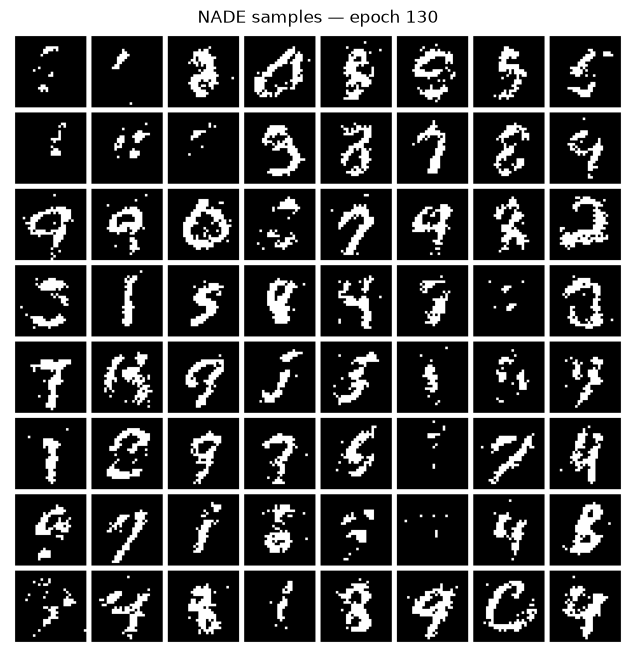

  batch 100: val NLL = 98.2768 (best 98.2086, 3/10) [saved ckpt_0520_nll98.2768.pt]
  batch 200: val NLL = 98.1649 (best 98.1649, 0/10) [saved ckpt_0521_nll98.1649.pt]
  batch 300: val NLL = 98.2729 (best 98.1649, 1/10) [saved ckpt_0522_nll98.2729.pt]
  batch 400: val NLL = 98.2580 (best 98.1649, 2/10) [saved ckpt_0523_nll98.2580.pt]
Epoch 131: train NLL = 97.7796


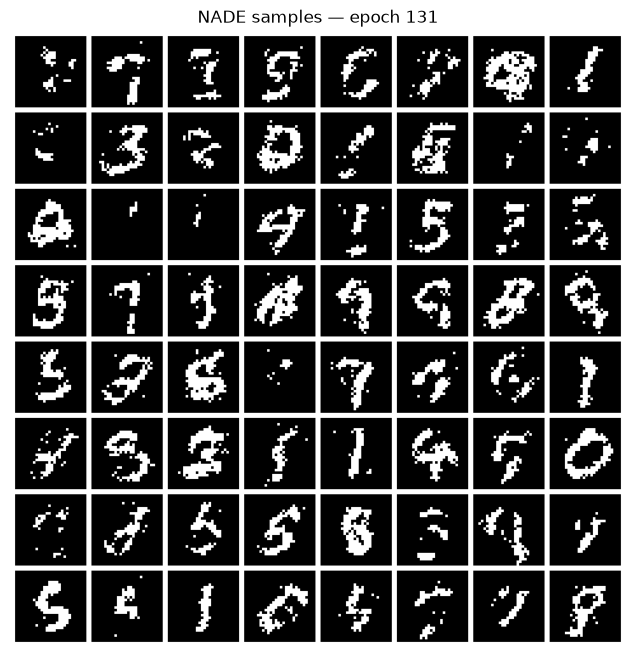

  batch 100: val NLL = 98.2386 (best 98.1649, 3/10) [saved ckpt_0524_nll98.2386.pt]
  batch 200: val NLL = 98.1540 (best 98.1540, 0/10) [saved ckpt_0525_nll98.1540.pt]
  batch 300: val NLL = 98.2197 (best 98.1540, 1/10) [saved ckpt_0526_nll98.2197.pt]
  batch 400: val NLL = 98.1360 (best 98.1360, 0/10) [saved ckpt_0527_nll98.1360.pt]
Epoch 132: train NLL = 97.7374


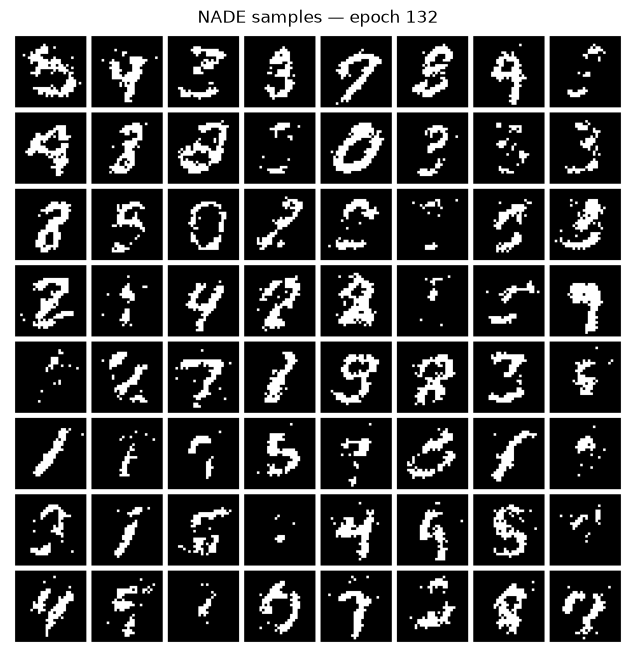

  batch 100: val NLL = 98.0766 (best 98.0766, 0/10) [saved ckpt_0528_nll98.0766.pt]
  batch 200: val NLL = 97.9980 (best 97.9980, 0/10) [saved ckpt_0529_nll97.9980.pt]
  batch 300: val NLL = 98.2735 (best 97.9980, 1/10)
  batch 400: val NLL = 98.1206 (best 97.9980, 2/10) [saved ckpt_0530_nll98.1206.pt]
Epoch 133: train NLL = 97.6524


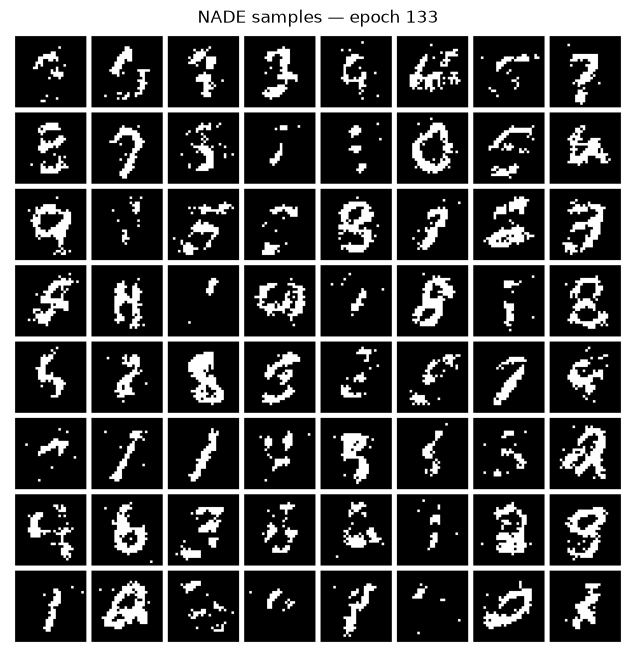

  batch 100: val NLL = 98.1224 (best 97.9980, 3/10) [saved ckpt_0531_nll98.1224.pt]
  batch 200: val NLL = 98.1381 (best 97.9980, 4/10) [saved ckpt_0532_nll98.1381.pt]
  batch 300: val NLL = 98.1321 (best 97.9980, 5/10) [saved ckpt_0533_nll98.1321.pt]
  batch 400: val NLL = 98.0330 (best 97.9980, 6/10) [saved ckpt_0534_nll98.0330.pt]
Epoch 134: train NLL = 97.5684


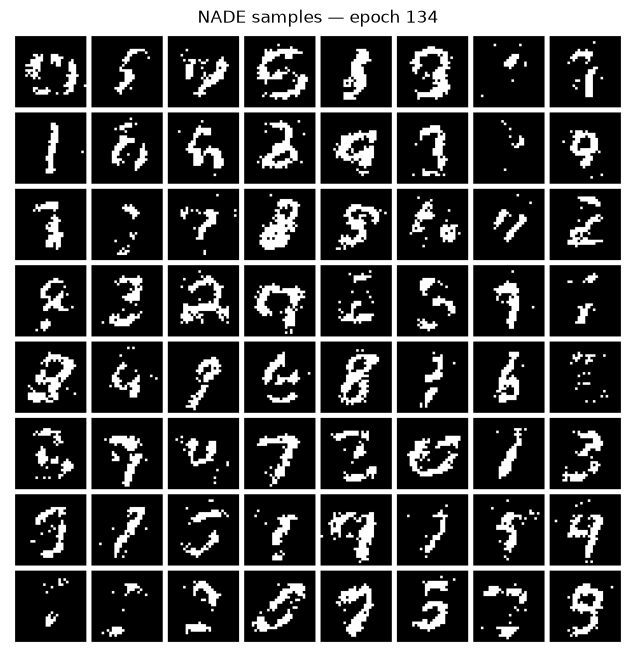

  batch 100: val NLL = 97.9283 (best 97.9283, 0/10) [saved ckpt_0535_nll97.9283.pt]
  batch 200: val NLL = 97.9523 (best 97.9283, 1/10) [saved ckpt_0536_nll97.9523.pt]
  batch 300: val NLL = 97.8866 (best 97.8866, 0/10) [saved ckpt_0537_nll97.8866.pt]
  batch 400: val NLL = 97.9333 (best 97.8866, 1/10) [saved ckpt_0538_nll97.9333.pt]
Epoch 135: train NLL = 97.4933


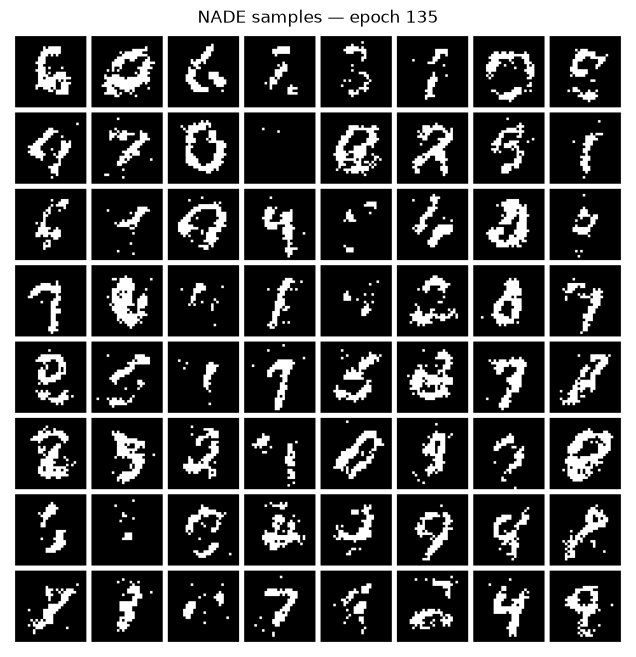

  batch 100: val NLL = 98.0627 (best 97.8866, 2/10) [saved ckpt_0539_nll98.0627.pt]
  batch 200: val NLL = 97.8368 (best 97.8368, 0/10) [saved ckpt_0540_nll97.8368.pt]
  batch 300: val NLL = 97.9185 (best 97.8368, 1/10) [saved ckpt_0541_nll97.9185.pt]
  batch 400: val NLL = 97.9381 (best 97.8368, 2/10) [saved ckpt_0542_nll97.9381.pt]
Epoch 136: train NLL = 97.4533


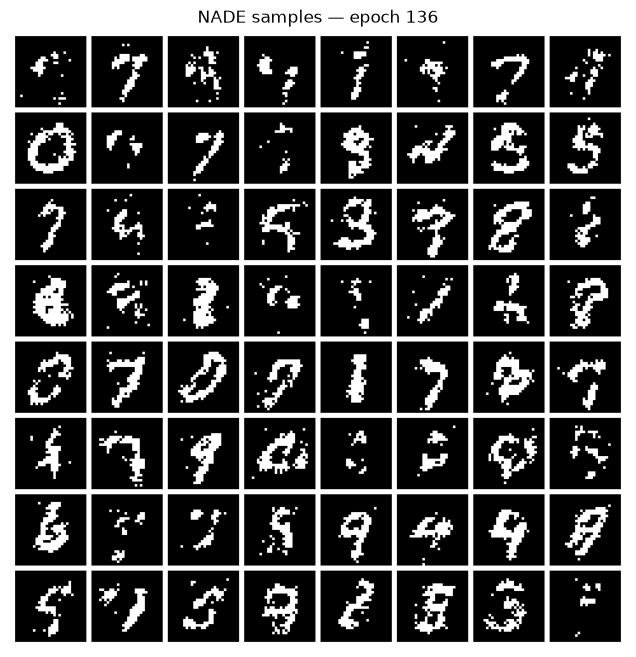

  batch 100: val NLL = 97.8433 (best 97.8368, 3/10) [saved ckpt_0543_nll97.8433.pt]
  batch 200: val NLL = 97.8032 (best 97.8032, 0/10) [saved ckpt_0544_nll97.8032.pt]
  batch 300: val NLL = 97.7349 (best 97.7349, 0/10) [saved ckpt_0545_nll97.7349.pt]
  batch 400: val NLL = 97.8069 (best 97.7349, 1/10) [saved ckpt_0546_nll97.8069.pt]
Epoch 137: train NLL = 97.3603


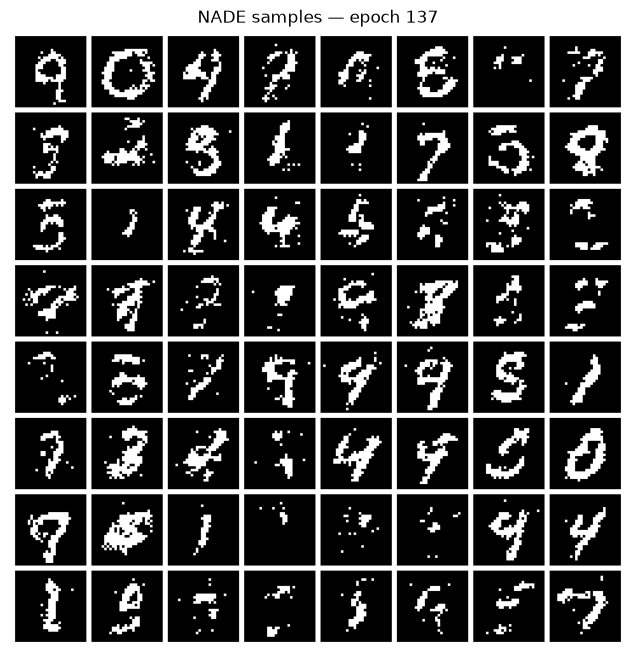

  batch 100: val NLL = 97.5562 (best 97.5562, 0/10) [saved ckpt_0547_nll97.5562.pt]
  batch 200: val NLL = 97.8078 (best 97.5562, 1/10) [saved ckpt_0548_nll97.8078.pt]
  batch 300: val NLL = 97.6534 (best 97.5562, 2/10) [saved ckpt_0549_nll97.6534.pt]
  batch 400: val NLL = 97.8580 (best 97.5562, 3/10) [saved ckpt_0550_nll97.8580.pt]
Epoch 138: train NLL = 97.2425


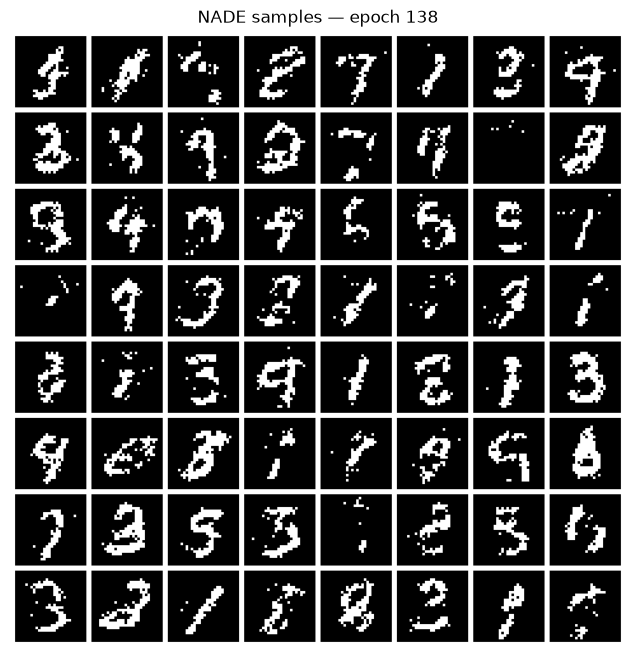

  batch 100: val NLL = 97.6990 (best 97.5562, 4/10) [saved ckpt_0551_nll97.6990.pt]
  batch 200: val NLL = 97.8189 (best 97.5562, 5/10) [saved ckpt_0552_nll97.8189.pt]
  batch 300: val NLL = 97.7682 (best 97.5562, 6/10) [saved ckpt_0553_nll97.7682.pt]
  batch 400: val NLL = 97.8582 (best 97.5562, 7/10)
Epoch 139: train NLL = 97.2777


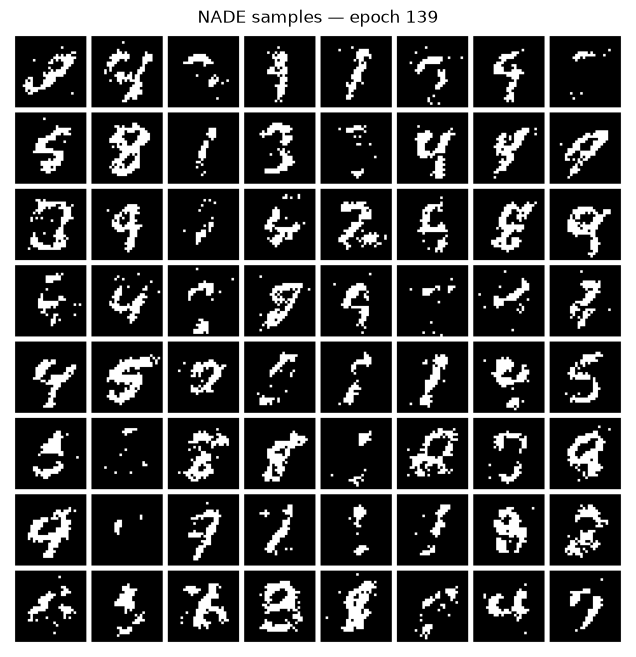

  batch 100: val NLL = 97.7005 (best 97.5562, 8/10) [saved ckpt_0554_nll97.7005.pt]
  batch 200: val NLL = 97.7727 (best 97.5562, 9/10) [saved ckpt_0555_nll97.7727.pt]
  batch 300: val NLL = 97.6392 (best 97.5562, 10/10) [saved ckpt_0556_nll97.6392.pt]
Early stopping at epoch 140, batch 300
Epoch 140: train NLL = 97.1977
Restored best model — val NLL = 97.7829
Test NLL = 96.6086

Top 10 checkpoints in checkpoints:
   1. 97.5562  checkpoints/ckpt_0547_nll97.5562.pt
   2. 97.6392  checkpoints/ckpt_0556_nll97.6392.pt
   3. 97.6534  checkpoints/ckpt_0549_nll97.6534.pt
   4. 97.6990  checkpoints/ckpt_0551_nll97.6990.pt
   5. 97.7005  checkpoints/ckpt_0554_nll97.7005.pt
   6. 97.7349  checkpoints/ckpt_0545_nll97.7349.pt
   7. 97.7682  checkpoints/ckpt_0553_nll97.7682.pt
   8. 97.7727  checkpoints/ckpt_0555_nll97.7727.pt
   9. 97.8032  checkpoints/ckpt_0544_nll97.8032.pt
  10. 97.8069  checkpoints/ckpt_0546_nll97.8069.pt


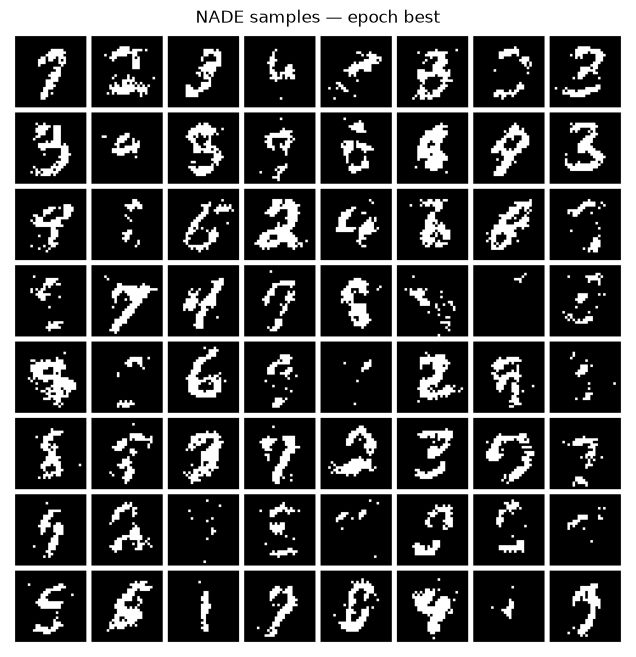

wandb: ERROR The nbformat package was not found. It is required to save notebook history.


epoch,▁▁▁▁▂▂▂▃▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇███
test/nll_per_image,▁
train/loss_step,██▅▅▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁
train/nll_per_image,█▆▆▅▄▄▃▃▃▃▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val/bad_evals,▁▁▁▁▁▁▂▁▂▁▃▁▂▁▁▂▂▃▄▂▂▂▁▁▁▄█▁▃▁▁▂▃▄▃▄▂▄▃█
val/best,█▇▇▆▅▄▄▄▄▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val/is_top_k,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val/nll_per_image,█▆▅▄▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
best_val_nll,97.78294
epoch,140
test/nll_per_image,96.60861


In [53]:
# Samples from the untrained model, for comparison
sample_and_log(model, n=64, epoch=0)

stopper = EarlyStopping(patience=PATIENCE)
keep = TopKCheckpoints(k=run.config.top_k_checkpoints, out_dir="checkpoints")

for epoch in range(1, run.config.epochs + 1):
    model.train()
    avg_loss, stopped = train_one_epoch(epoch, stopper, keep)

    wandb.log({"train/nll_per_image": avg_loss, "epoch": epoch}, commit=False)
    print(f"Epoch {epoch}: train NLL = {avg_loss:.4f}")

    if stopped:
        break

    sample_and_log(model, n=64, epoch=epoch)

# Roll back to the single best state seen during training
stopper.restore(model)
best_val = evaluate(model, val_loader)
print(f"Restored best model — val NLL = {best_val:.4f}")
wandb.summary["best_val_nll"] = best_val

# Unbiased final score: test set was never used for stopping or selection
test_nll = evaluate(model, test_loader)
print(f"Test NLL = {test_nll:.4f}")
wandb.log({"test/nll_per_image": test_nll})
wandb.summary["test_nll"] = test_nll

# Report the k best checkpoints kept on disk
print(f"\nTop {len(keep.entries)} checkpoints in {keep.out_dir}:")
for rank, (val, path) in enumerate(keep.entries, 1):
    print(f"  {rank:2d}. {val:.4f}  {path}")
wandb.summary["top_k_checkpoints"] = [str(p) for p in keep.paths()]

sample_and_log(model, n=64, epoch="best", key="samples/best_model")
wandb.finish()
